# What do the models output on unseen instructions? — post-hoc diagnostics for BOTH experiments

This notebook **does not train, fine-tune or re-select anything**. It reads the *saved* test predictions of all
trained models from both experiments (`distinct_pairs`, `all_pairs`) and asks what the models systematically output
on strings they were not trained on (singles, unseen pairs, all 27 triples).

**Task reminder.** 6x6 grids of digits 0-9; `A` = shift right by one with wrap, `B` = rotate 90° clockwise,
`C` = mirror left-right; strings run **left to right** (`AB` = B(A(X))).

**What is measured** (all on frozen predictions):
1. *Audit*: integer exact/cell counts recomputed from raw records; stored targets re-derived by an independent oracle;
   grid/string alignment across models and experiments; free-running vs teacher-forced provenance.
2. *Legal-transformation matching*: every prediction is compared with **all 288** transformations generated by A, B, C
   (36 translations x 8 square orientations). Exact matches can be unique, ambiguous, or absent.
3. *Pre-declared error hypotheses* (identity, first/last op, prefixes/suffixes, dropped/reordered ops, collapsed repeats,
   doubled singles, training-pair transformations).
4. *Stability across grids*: one fixed transformation, a bijective source permutation, and a many-to-one source-copy
   map are **fitted to model predictions on half of the base grids** and evaluated on the other half (DIAG split).
5. *Composition consistency* of the fitted single-operation maps, and the explicit **half-period ambiguity**
   A'=ZA, B'=ZB, C'=ZC (Z = shift by 3 right and 3 down), which leaves every length-2 string unchanged.
6. *Calibration controls* showing why exact accuracy 0 with cell accuracy ~0.10 can still be a perfectly structured error.

**Interpretation limits.** Behavioural compatibility is not a mechanistic or causal claim; DIAG-split fidelities
describe frozen predictions and are not a new benchmark; one training seed only.


In [2]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 8850c0fd42a7e5f23cded2abf833240a0eb8350f


In [3]:
# --- CONFIGURATION ------------------------------------------------------------------------------------
# Results root used by notebooks 01/02 (their saved outputs show
# /content/drive/MyDrive/decompositionality_results/<experiment>). Change if you used another RESULTS_ROOT.
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
EXPERIMENT_RESULT_DIRS = {
    "distinct_pairs": f"{RESULTS_ROOT}/distinct_pairs",
    "all_pairs": f"{RESULTS_ROOT}/all_pairs",
}
DIAGNOSTICS_OUTPUT_DIR = os.environ.get("DECOMP_DIAGNOSTICS_DIR") or f"{RESULTS_ROOT}/diagnostics_generalization_failures"
MODELS = None                         # None = every model discovered in the result folders
CHUNK_SIZE = 2000                     # records per vectorized matching chunk (memory ~ CHUNK_SIZE x 288 x 36 bytes)
USE_CACHE = True                      # reuse per-run results keyed by prediction-file hash + analysis version
SPLIT_SEED = 20251106                 # deterministic FIT/DIAG split of base-grid IDs (identical for all runs)
HASH_CHECKPOINTS = True               # record SHA-256 of best.pt for provenance (read-only)
RUN_FROZEN_INFERENCE_IF_MISSING = False   # opt-in: regenerate MISSING predictions from best.pt (GPU helpful; never trains)
USE_SYNTHETIC_FIXTURES = os.environ.get("DECOMP_SYNTHETIC_FIXTURES") == "1"  # demo/test ONLY: planted fake models
# --------------------------------------------------------------------------------------------------------------

if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

if USE_SYNTHETIC_FIXTURES:
    import tempfile
    from decompositionality.diagnosis.fixtures import write_fixture_results, PLANTED
    _fx = pathlib.Path(tempfile.mkdtemp()) / "SYNTHETIC_results"
    EXPERIMENT_RESULT_DIRS = write_fixture_results(_fx, n_grids=40)
    DIAGNOSTICS_OUTPUT_DIR = str(_fx / "diagnostics_generalization_failures")
    print("*** SYNTHETIC FIXTURE MODE: planted fake behaviours, NOT real model outputs ***")
    for k, v in PLANTED.items():
        print(f"   {k}: {v}")

from decompositionality.diagnosis.runner import DiagnosticsConfig, run_diagnostics
cfg = DiagnosticsConfig(experiment_dirs=EXPERIMENT_RESULT_DIRS, output_dir=DIAGNOSTICS_OUTPUT_DIR, models=MODELS,
                        chunk_size=CHUNK_SIZE, use_cache=USE_CACHE, split_seed=SPLIT_SEED,
                        hash_checkpoints=HASH_CHECKPOINTS,
                        run_frozen_inference_if_missing=RUN_FROZEN_INFERENCE_IF_MISSING)
print("experiment folders:", EXPERIMENT_RESULT_DIRS)
print("diagnostics output:", DIAGNOSTICS_OUTPUT_DIR)


Mounted at /content/drive
experiment folders: {'distinct_pairs': '/content/drive/MyDrive/decompositionality_results/distinct_pairs', 'all_pairs': '/content/drive/MyDrive/decompositionality_results/all_pairs'}
diagnostics output: /content/drive/MyDrive/decompositionality_results/diagnostics_generalization_failures


In [4]:
# --- 1. Which experiments/models were found? (searched only inside the configured folders) ---
import pandas as pd
from IPython.display import Image, Markdown, display
from decompositionality.diagnosis.artifacts import inventory
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
inv = inventory(cfg.experiment_dirs, pathlib.Path(cfg.output_dir) / "regenerated_predictions", cfg.models)
display(inv[["experiment", "model", "status", "original_predictions", "best_checkpoint", "manifest"]])
missing = inv[~inv.status.str.startswith("predictions available")]
if len(missing):
    print(f"{len(missing)} experiment/model combinations have NO predictions; they are reported as missing, never as 0.")
    if not RUN_FROZEN_INFERENCE_IF_MISSING:
        print("Set RUN_FROZEN_INFERENCE_IF_MISSING=True to regenerate them from the selected checkpoints (no training).")


,experiment,model,status,original_predictions,best_checkpoint,manifest
0,distinct_pairs,transformer_ar,predictions available (original),True,True,True
1,distinct_pairs,looped_transformer_ar,predictions available (original),True,True,True
2,distinct_pairs,transformer_encoder,predictions available (original),True,True,True
3,distinct_pairs,looped_transformer_encoder,predictions available (original),True,True,True
4,distinct_pairs,vit,predictions available (original),True,True,True
5,distinct_pairs,looped_vit,predictions available (original),True,True,True
6,distinct_pairs,trm,predictions available (original),True,True,True
7,distinct_pairs,rescnn_film,predictions available (original),True,True,True
8,distinct_pairs,unet_film,predictions available (original),True,True,True
9,all_pairs,transformer_ar,predictions available (original),True,True,True


## Run
One call performs the audit, catalog construction, matching, rule fitting, controls, figures and report. Re-running skips runs whose prediction-file hash and analysis version are unchanged.

In [5]:
# --- 2. Run the full diagnostic pipeline (cached; CPU is sufficient; no model weights are loaded) ---
import time
_t = time.time()
R = run_diagnostics(cfg)
print(f"done in {time.time() - _t:.0f}s")
FIG = pathlib.Path(cfg.output_dir) / "figures"
def show(name):
    for p in sorted(FIG.glob(name + "*.png")):
        display(Image(filename=str(p)))


Artifact inventory:
    experiment                      model                           status
distinct_pairs             transformer_ar predictions available (original)
distinct_pairs      looped_transformer_ar predictions available (original)
distinct_pairs        transformer_encoder predictions available (original)
distinct_pairs looped_transformer_encoder predictions available (original)
distinct_pairs                        vit predictions available (original)
distinct_pairs                 looped_vit predictions available (original)
distinct_pairs                        trm predictions available (original)
distinct_pairs                rescnn_film predictions available (original)
distinct_pairs                  unet_film predictions available (original)
     all_pairs             transformer_ar predictions available (original)
     all_pairs      looped_transformer_ar predictions available (original)
     all_pairs        transformer_encoder predictions available (original)
     

## Audit
Integer counts come from raw per-example records (not rounded summaries). `attribution_blocked` runs are excluded from all explanatory analyses.

In [6]:
# --- 3. Artifact audit and integer success counts recomputed from raw records ---
cols = ["experiment", "model", "source", "n_records", "n_strings", "missing_strings", "duplicate_keys", "selected_step",
        "decoding", "invalid_records", "out_of_range_prediction_values", "target_oracle_mismatches",
        "input_manifest_mismatches", "stored_exact_mismatch", "attribution_blocked"]
display(R["audit"][[c for c in cols if c in R["audit"]]])
print("Test manifests identical across experiments:", R["manifests_identical_across_experiments"])
display(R["alignment"])
g = R["metrics_groups"]
display(g[["experiment", "model", "group", "exact_correct", "n", "exact_acc", "cell_correct", "cells_total", "cell_acc",
           "invalid_records", "invalid_rate"]].style.format({"exact_acc": "{:.6f}", "cell_acc": "{:.6f}", "invalid_rate": "{:.6f}"}, na_rep="N/A"))


,experiment,model,source,n_records,n_strings,missing_strings,duplicate_keys,selected_step,decoding,invalid_records,out_of_range_prediction_values,target_oracle_mismatches,input_manifest_mismatches,stored_exact_mismatch,attribution_blocked
0,distinct_pairs,transformer_ar,original,39000,39,,0,4750,AR free-running greedy decoding (eval_summary ...,0,0,0,0,0,False
1,distinct_pairs,looped_transformer_ar,original,39000,39,,0,5000,AR free-running greedy decoding (eval_summary ...,0,0,0,0,0,False
2,distinct_pairs,transformer_encoder,original,39000,39,,0,5000,parallel prediction (parallel argmax); not aut...,0,0,0,0,0,False
3,distinct_pairs,looped_transformer_encoder,original,39000,39,,0,5000,parallel prediction (parallel argmax); not aut...,0,0,0,0,0,False
4,distinct_pairs,vit,original,39000,39,,0,5000,parallel prediction (parallel argmax); not aut...,0,0,0,0,0,False
5,distinct_pairs,looped_vit,original,39000,39,,0,5000,parallel prediction (parallel argmax); not aut...,0,0,0,0,0,False
6,distinct_pairs,trm,original,39000,39,,0,4750,parallel prediction (parallel argmax of final ...,0,0,0,0,0,False
7,distinct_pairs,rescnn_film,original,39000,39,,0,5000,parallel prediction (parallel argmax); not aut...,0,0,0,0,0,False
8,distinct_pairs,unet_film,original,39000,39,,0,4500,parallel prediction (parallel argmax); not aut...,0,0,0,0,0,False
9,all_pairs,transformer_ar,original,39000,39,,0,5000,AR free-running greedy decoding (eval_summary ...,0,0,0,0,0,False


Test manifests identical across experiments: True


,run,n_keys,missing_vs_union,matched_in_all_runs
0,distinct_pairs/transformer_ar,39000,0,39000
1,distinct_pairs/looped_transformer_ar,39000,0,39000
2,distinct_pairs/transformer_encoder,39000,0,39000
3,distinct_pairs/looped_transformer_encoder,39000,0,39000
4,distinct_pairs/vit,39000,0,39000
5,distinct_pairs/looped_vit,39000,0,39000
6,distinct_pairs/trm,39000,0,39000
7,distinct_pairs/rescnn_film,39000,0,39000
8,distinct_pairs/unet_film,39000,0,39000
9,all_pairs/transformer_ar,39000,0,39000


,experiment,model,group,exact_correct,n,exact_acc,cell_correct,cells_total,cell_acc,invalid_records,invalid_rate
0,distinct_pairs,transformer_ar,singles,0,3000,0.000000,11174,108000,0.103463,0,0.000000
1,distinct_pairs,transformer_ar,pairs_seen,6000,6000,1.000000,216000,216000,1.000000,0,0.000000
2,distinct_pairs,transformer_ar,pairs_unseen,0,3000,0.000000,37234,108000,0.344759,0,0.000000
3,distinct_pairs,transformer_ar,triples_all_distinct,0,6000,0.000000,21917,216000,0.101468,0,0.000000
4,distinct_pairs,transformer_ar,triples_two_types,0,18000,0.000000,64595,648000,0.099684,0,0.000000
5,distinct_pairs,transformer_ar,triples_one_type,0,3000,0.000000,10658,108000,0.098685,0,0.000000
6,distinct_pairs,transformer_ar,triples_all,0,27000,0.000000,97170,972000,0.099969,0,0.000000
7,distinct_pairs,looped_transformer_ar,singles,0,3000,0.000000,10796,108000,0.099963,0,0.000000
8,distinct_pairs,looped_transformer_ar,pairs_seen,6000,6000,1.000000,216000,216000,1.000000,0,0.000000
9,distinct_pairs,looped_transformer_ar,pairs_unseen,0,3000,0.000000,37977,108000,0.351639,0,0.000000


In [7]:
# --- 4. The 288-element transformation catalog and the 39 evaluated strings ---
print(R["catalog_check"])
display(R["string_classes"][R["string_classes"].experiment == "distinct_pairs"]
        .drop(columns=["experiment"]).style.hide(axis="index"))
print("Strings with the same group_id are aliases (same transformation). 'transformation_in_training' tracks the "
      "transformation, 'string_in_training' the symbolic string.")


{'size': 288, 'z_id': 287, 'z_word': 'AAABAAABBB', 'max_word_length': 10, 'digest': '26fb0029adf0dbda'}


string,group_id,canonical_word,string_in_training,transformation_in_training,alt_generator_id,alt_generator_word,evaluated_aliases
A,1,A,False,False,285,BAAABAABB,ACC CCA
B,2,B,False,False,176,AAABAAA,BCC CCB
C,3,C,False,False,277,AAABAAACB,ACA BCB CCC
AA,4,AA,False,False,4,AA,
AB,5,AB,True,True,5,AB,
AC,6,AC,True,True,6,AC,
BA,7,BA,True,True,7,BA,
BB,8,BB,False,False,8,BB,
BC,9,BC,True,True,9,BC,
CA,10,CA,True,True,10,CA,


Strings with the same group_id are aliases (same transformation). 'transformation_in_training' tracks the transformation, 'string_in_training' the symbolic string.


## What the models output
Categories: *correct*; *wrong: unique legal* (exactly one of the 288 transformations reproduces the prediction); *wrong: ambiguous legal* (several do, e.g. symmetric inputs); *no legal match*. A match does not identify which symbolic string was executed.

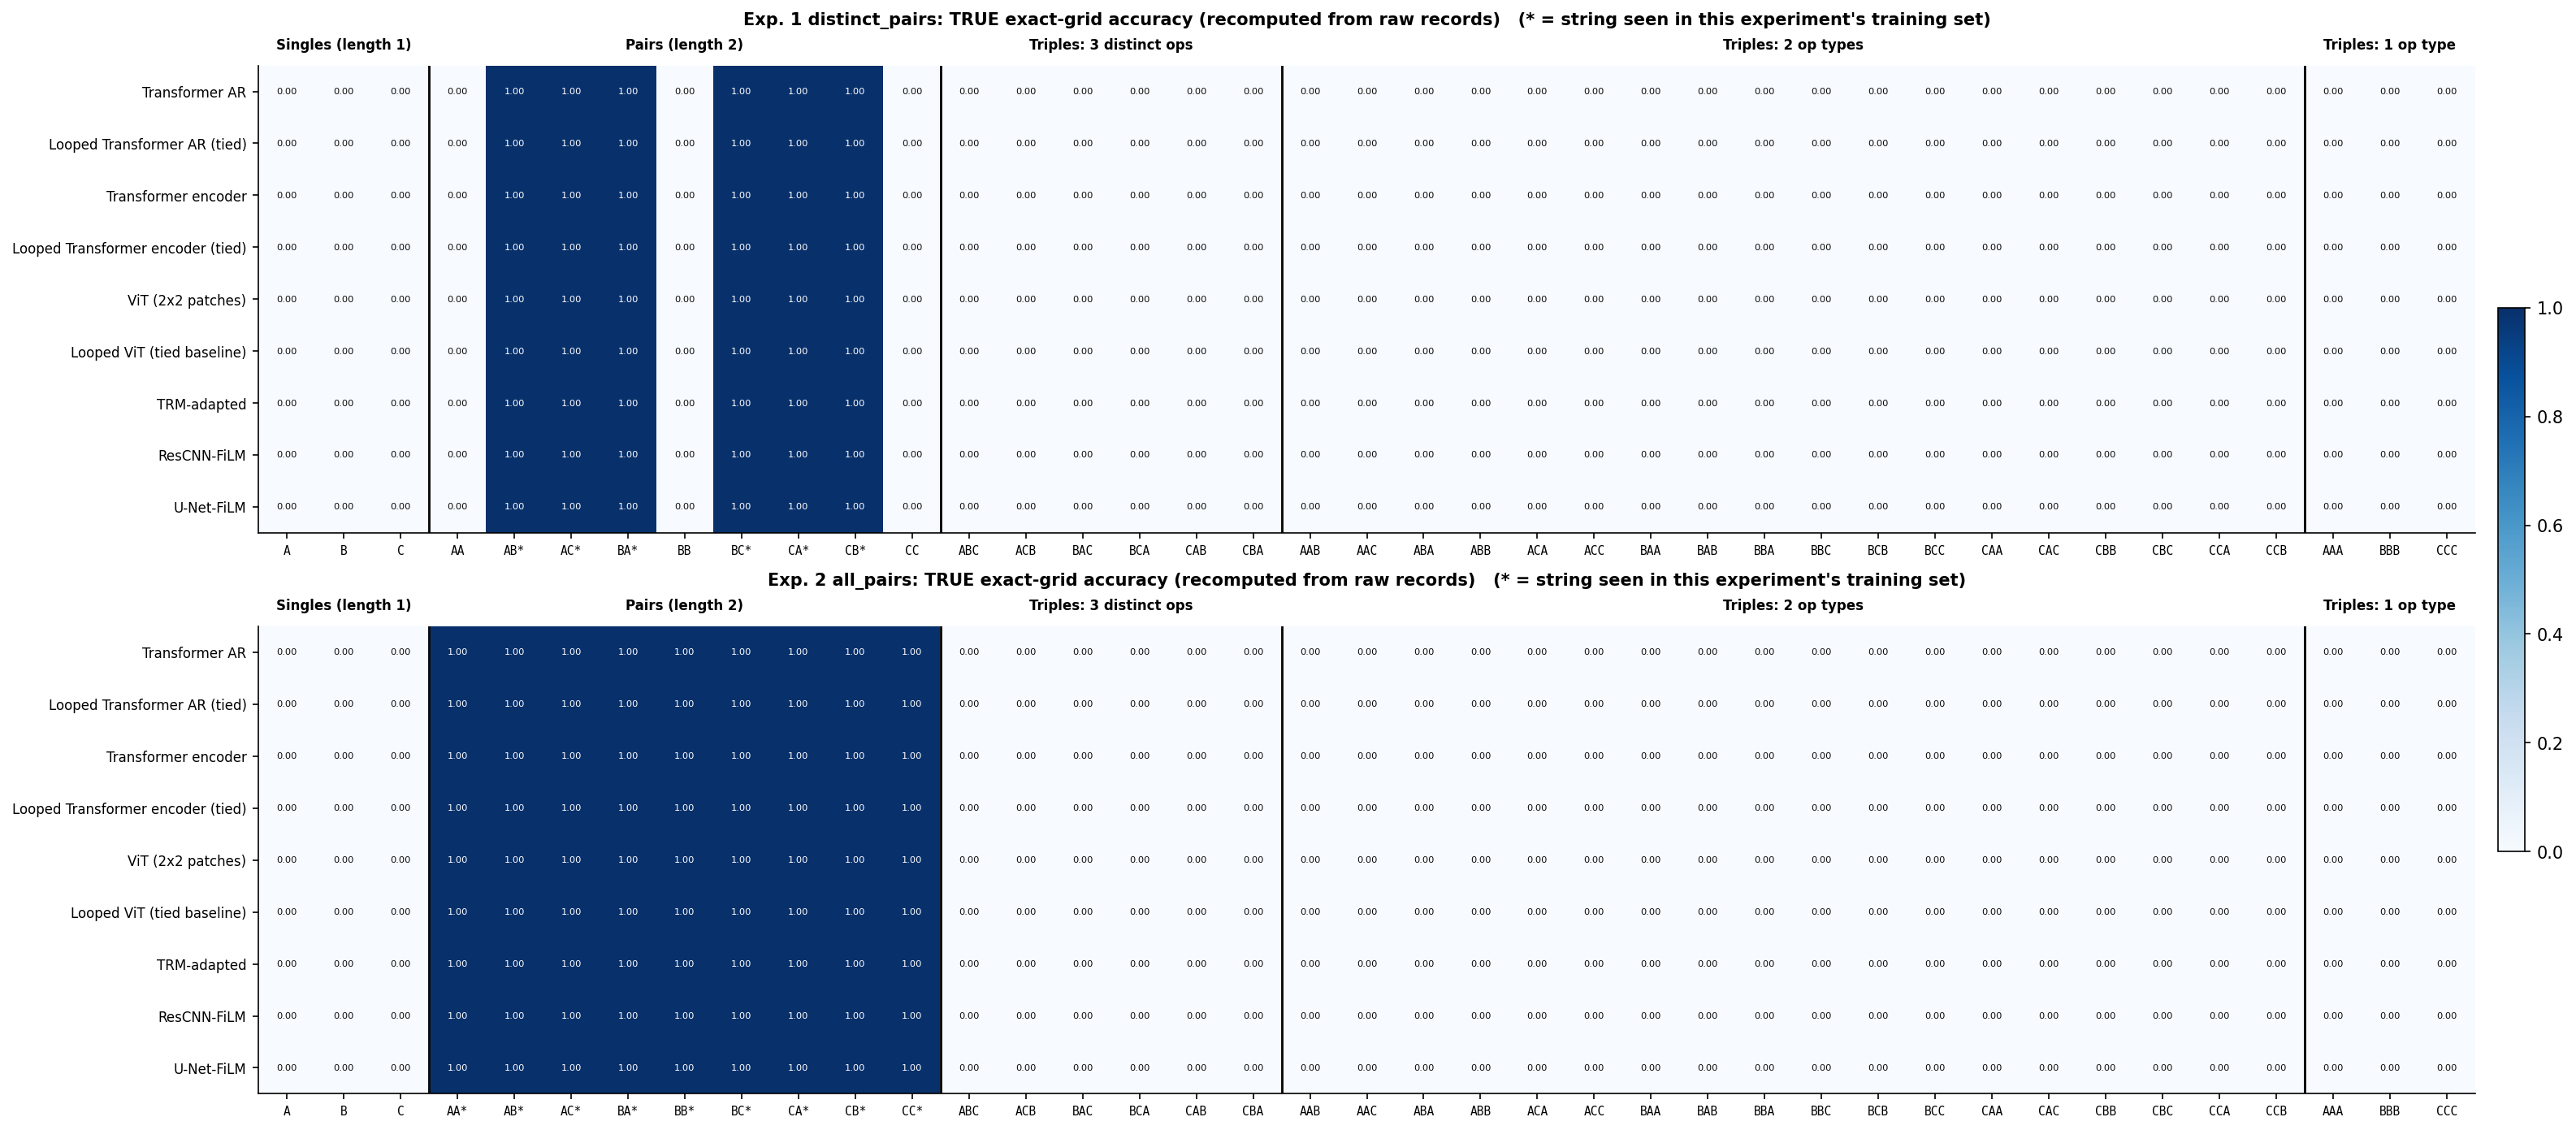

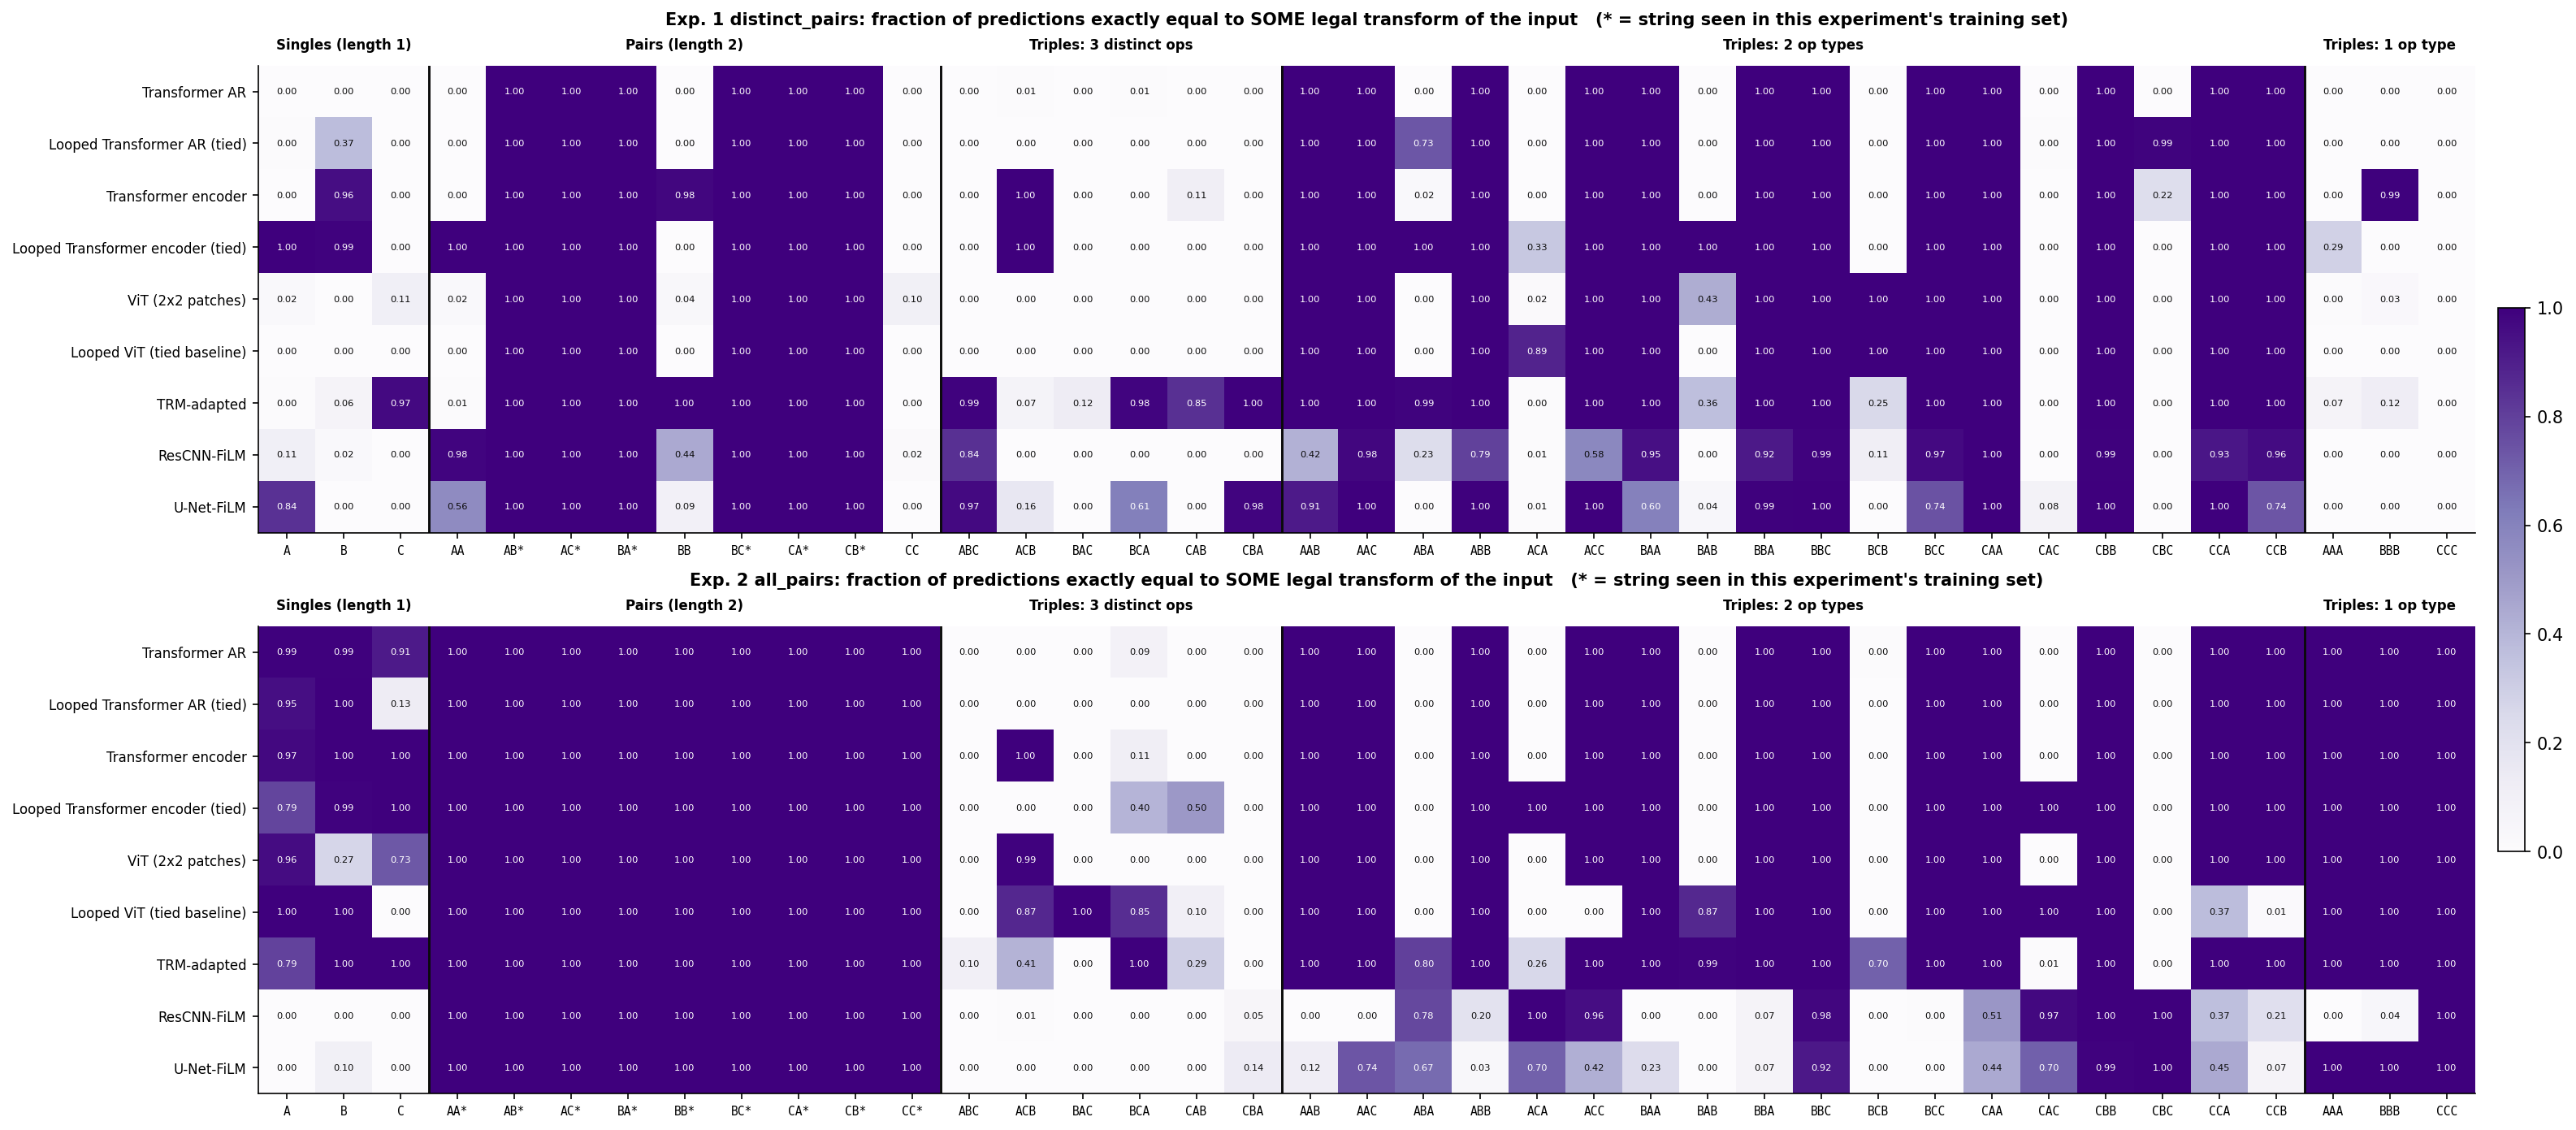

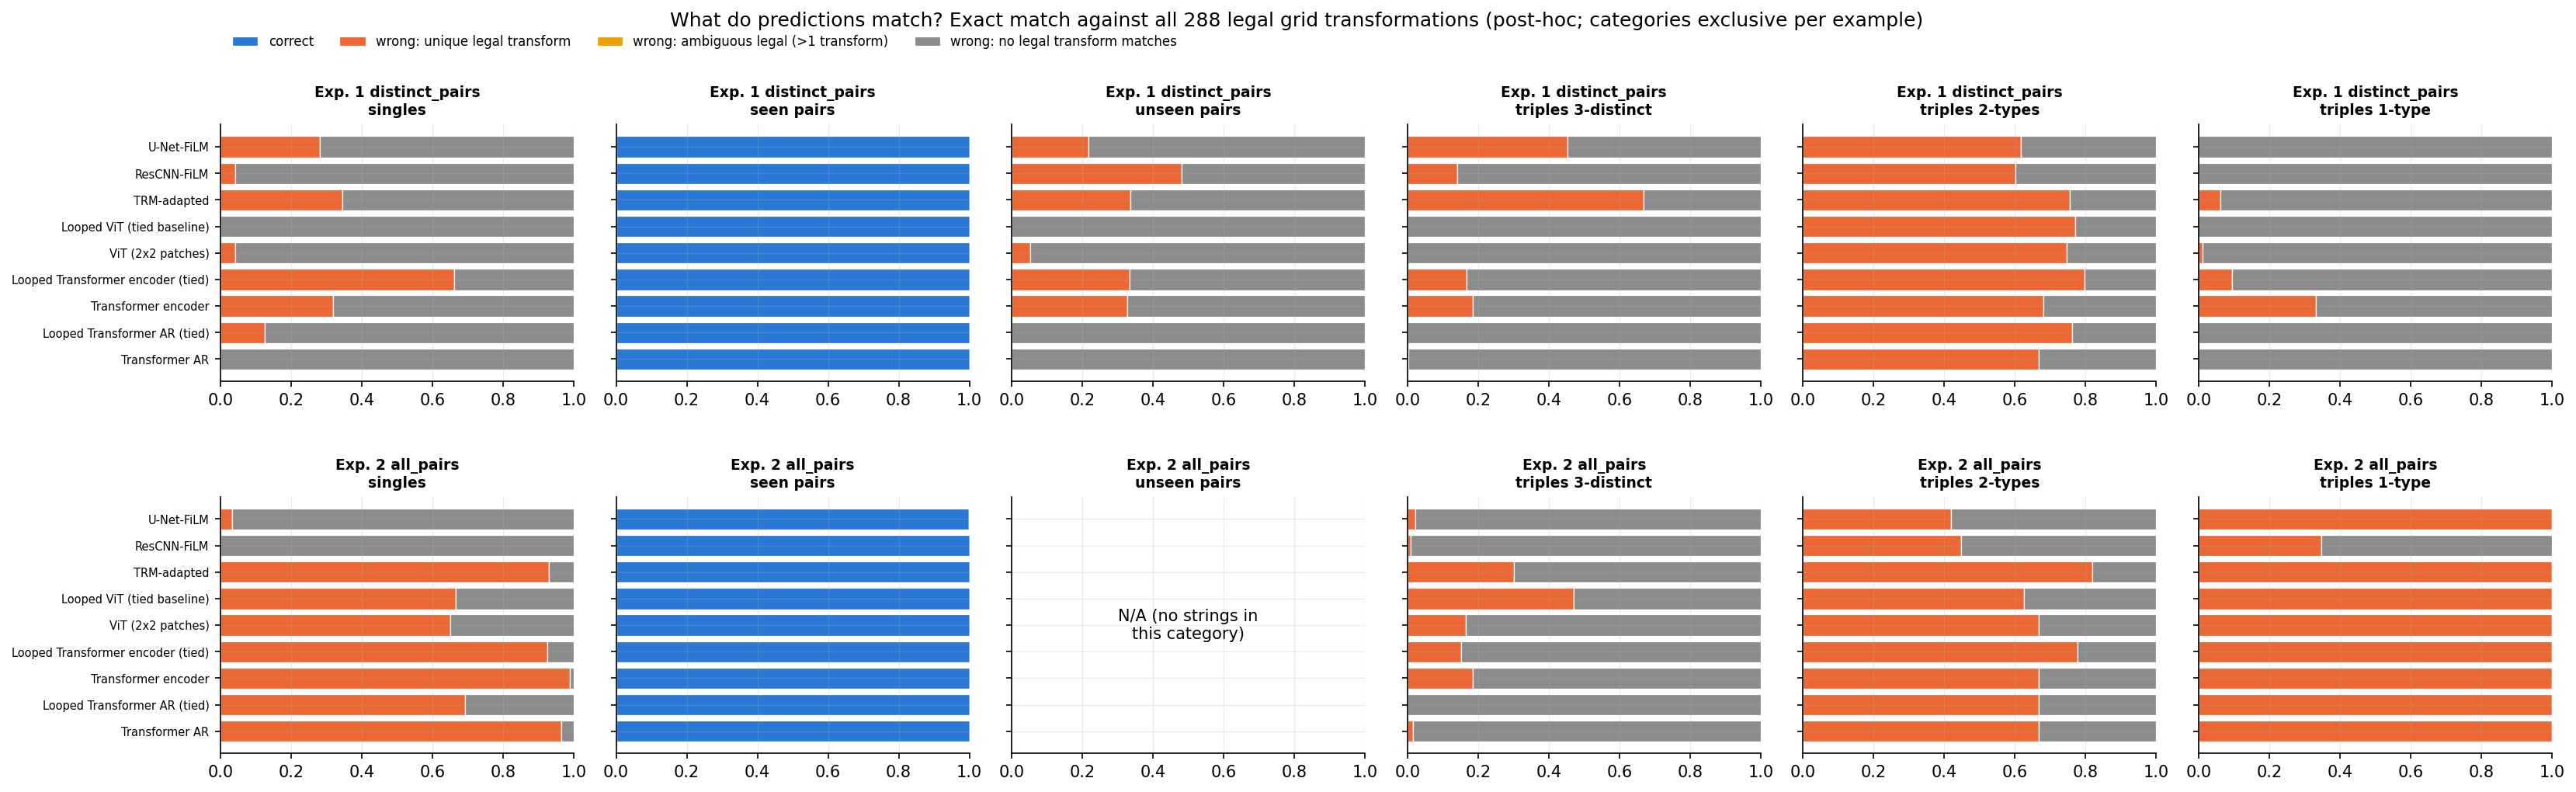

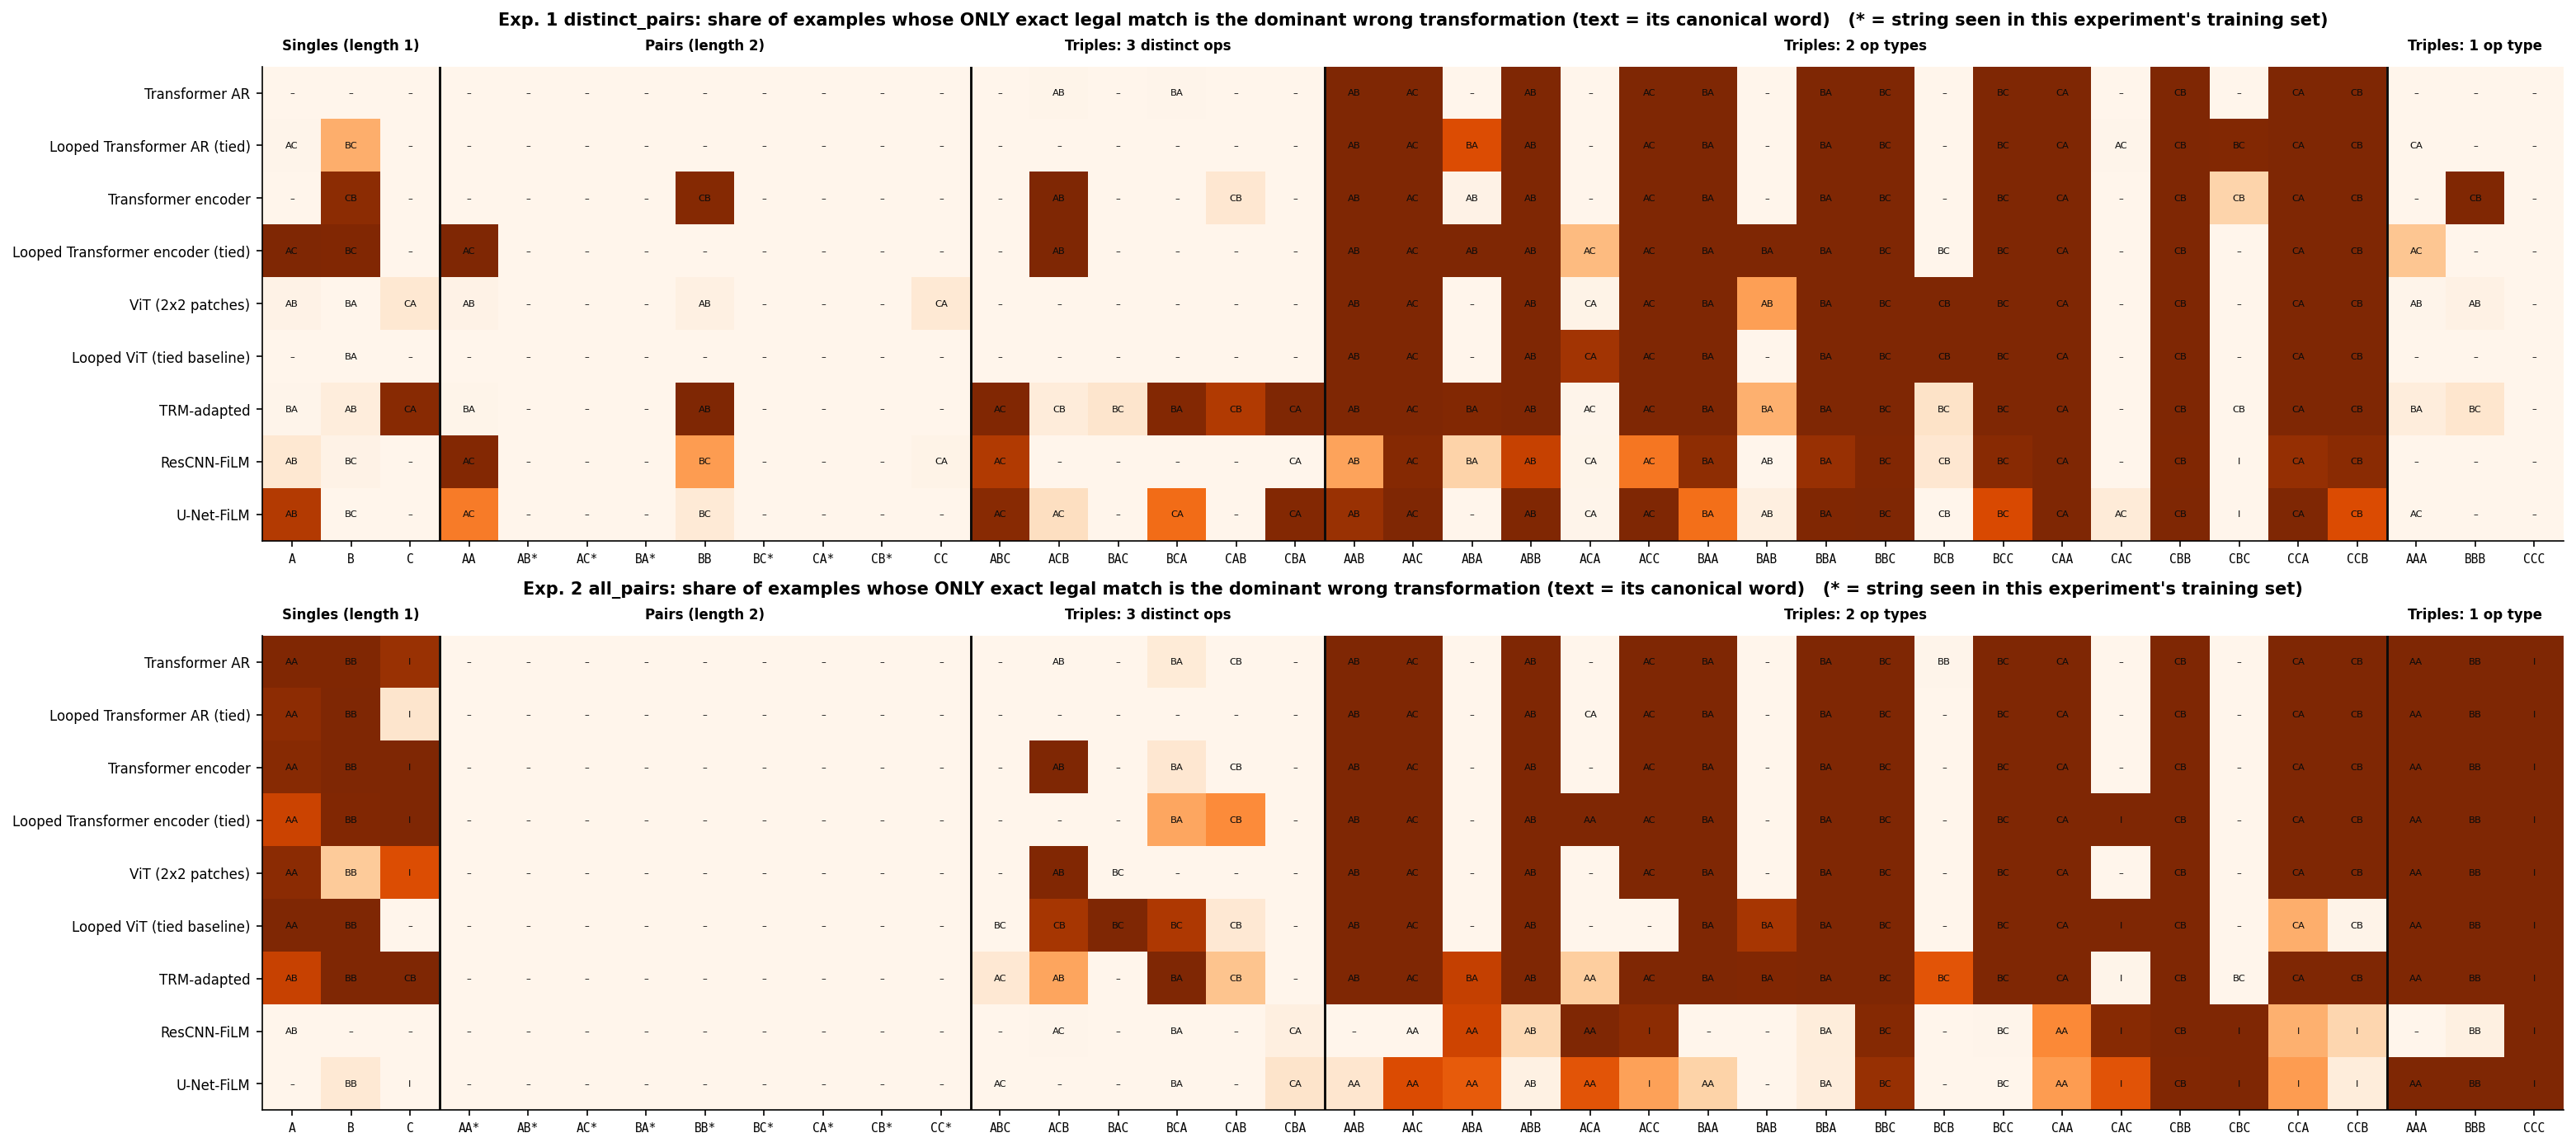

,experiment,model,group,n_strings,n_records,exact_correct,true_exact_acc,true_cell_acc,any_exact_legal_match,wrong_unique_legal,no_legal_match,DIAG stable_rule_exact_fidelity,DIAG stable_rule_cell_fidelity,DIAG bijective_perm_cell_fidelity,DIAG argmax_map_cell_fidelity,alt_generator(Z)_exact_agreement,digit_histogram_preserved
0,distinct_pairs,transformer_ar,singles,3,3000,0,0.0000,0.1035,0.0000,0.0000,1.0000,0.0000,0.5449,0.7207,0.8679,0.0000,0.0000
1,distinct_pairs,transformer_ar,pairs_seen,6,6000,6000,1.0000,1.0000,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,distinct_pairs,transformer_ar,pairs_unseen,3,3000,0,0.0000,0.3448,0.0000,0.0000,1.0000,0.0000,0.5248,0.7231,0.8945,0.0000,0.0000
3,distinct_pairs,transformer_ar,triples_all_distinct,6,6000,0,0.0000,0.1015,0.0028,0.0028,0.9972,0.0027,0.7645,0.8401,0.9380,0.0000,0.0052
4,distinct_pairs,transformer_ar,triples_two_types,18,18000,0,0.0000,0.0997,0.6667,0.6667,0.3333,0.6667,0.8763,0.9248,0.9764,0.0000,0.6667
5,distinct_pairs,transformer_ar,triples_one_type,3,3000,0,0.0000,0.0987,0.0000,0.0000,1.0000,0.0000,0.5391,0.7275,0.8998,0.0000,0.0000
6,distinct_pairs,looped_transformer_ar,singles,3,3000,0,0.0000,0.1000,0.1253,0.1253,0.8747,0.1280,0.8059,0.8695,0.9007,0.0000,0.1307
7,distinct_pairs,looped_transformer_ar,pairs_seen,6,6000,6000,1.0000,1.0000,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
8,distinct_pairs,looped_transformer_ar,pairs_unseen,3,3000,0,0.0000,0.3516,0.0000,0.0000,1.0000,0.0000,0.5394,0.7267,0.8028,0.0000,0.0023
9,distinct_pairs,looped_transformer_ar,triples_all_distinct,6,6000,0,0.0000,0.0983,0.0000,0.0000,1.0000,0.0000,0.6801,0.7144,0.7493,0.0000,0.0003


,experiment,model,string,word,is_training_transform,count,n
2496,all_pairs,unet_film,CCC,I,True,1000,1000
2492,all_pairs,unet_film,BBB,BB,True,1000,1000
2488,all_pairs,unet_film,AAA,AA,True,1000,1000
59,distinct_pairs,transformer_ar,AAB,AB,True,1000,1000
63,distinct_pairs,transformer_ar,AAC,AC,True,1000,1000
...,...,...,...,...,...,...,...
1061,distinct_pairs,rescnn_film,BBC,BC,True,992,1000
2472,all_pairs,unet_film,CBB,CB,True,989,1000
975,distinct_pairs,rescnn_film,AA,AC,True,983,1000
1029,distinct_pairs,rescnn_film,AAC,AC,True,978,1000


In [8]:
# --- 5. What do predictions match? (exact legal-transform matching; true accuracy shown first) ---
show("01_true_exact"); show("02_any_exact"); show("03_explanation"); show("04_dominant")
s = R["summary"]
display(s.style.format(precision=4, na_rep="N/A"))
top = R["confusion"]
top = top[top.bin == "wrong_unique_legal"].sort_values("count", ascending=False)
display(top.groupby(["experiment", "model"]).head(5)[["experiment", "model", "string", "word", "is_training_transform", "count", "n"]])


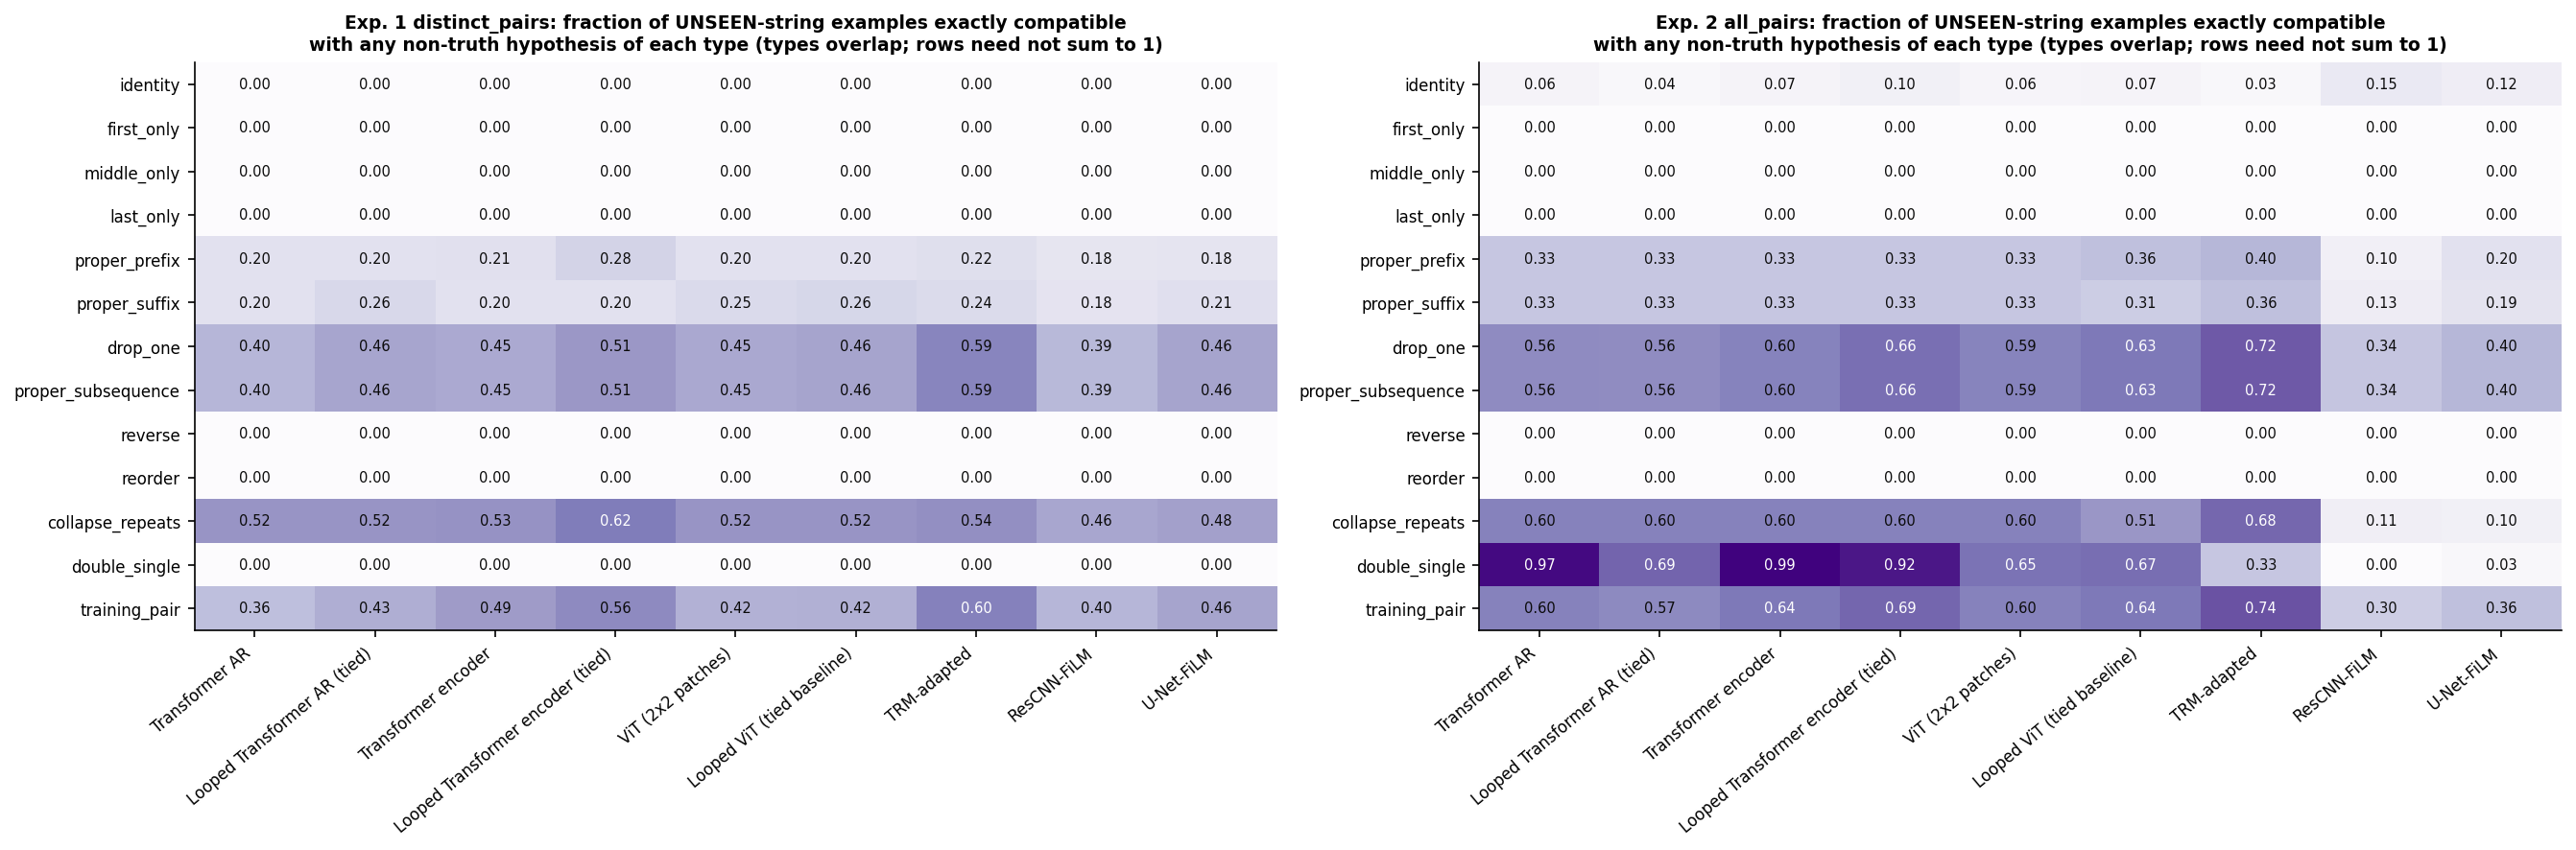

,experiment,model,string,hypothesis_type,executed_word,group_word,aliases,compatible_rate
16280,all_pairs,unet_film,CCC,training_pair,CC,I,identity:I; proper_prefix:CC; proper_suffix:CC...,1.0
351,distinct_pairs,transformer_ar,AAB,proper_suffix,AB,AB,drop_one:AB; proper_subsequence:AB; collapse_r...,1.0
353,distinct_pairs,transformer_ar,AAB,drop_one,AB,AB,proper_suffix:AB; proper_subsequence:AB; colla...,1.0
358,distinct_pairs,transformer_ar,AAB,proper_subsequence,AB,AB,proper_suffix:AB; drop_one:AB; collapse_repeat...,1.0
15317,all_pairs,rescnn_film,CCC,training_pair,CC,I,identity:I; proper_prefix:CC; proper_suffix:CC...,1.0
15306,all_pairs,rescnn_film,CCC,proper_subsequence,CC,I,identity:I; proper_prefix:CC; proper_suffix:CC...,1.0
622,distinct_pairs,transformer_ar,BCC,proper_prefix,BC,BC,drop_one:BC; proper_subsequence:BC; collapse_r...,1.0
588,distinct_pairs,transformer_ar,BBC,training_pair,BC,BC,proper_suffix:BC; drop_one:BC; proper_subseque...,1.0
584,distinct_pairs,transformer_ar,BBC,collapse_repeats,BC,BC,proper_suffix:BC; drop_one:BC; proper_subseque...,1.0
580,distinct_pairs,transformer_ar,BBC,proper_subsequence,BC,BC,proper_suffix:BC; drop_one:BC; collapse_repeat...,1.0


In [9]:
# --- 6. Pre-declared human-readable error hypotheses (overlapping; need not sum to 1) ---
show("05_hypothesis")
h = R["hypotheses"]
display(h[(~h.truth_equivalent) & (h.compatible_rate > 0.2)].sort_values("compatible_rate", ascending=False)
        [["experiment", "model", "string", "hypothesis_type", "executed_word", "group_word", "aliases", "compatible_rate"]].head(40))


## Is the behaviour a stable rule?
Rules are fitted to **model predictions** (never targets) on the FIT half of the base grids and scored on the disjoint DIAG half. Many-to-one source-copy maps and bijective permutations are kept distinct; tie-driven/low-fidelity maps are flagged rather than called learned rules.

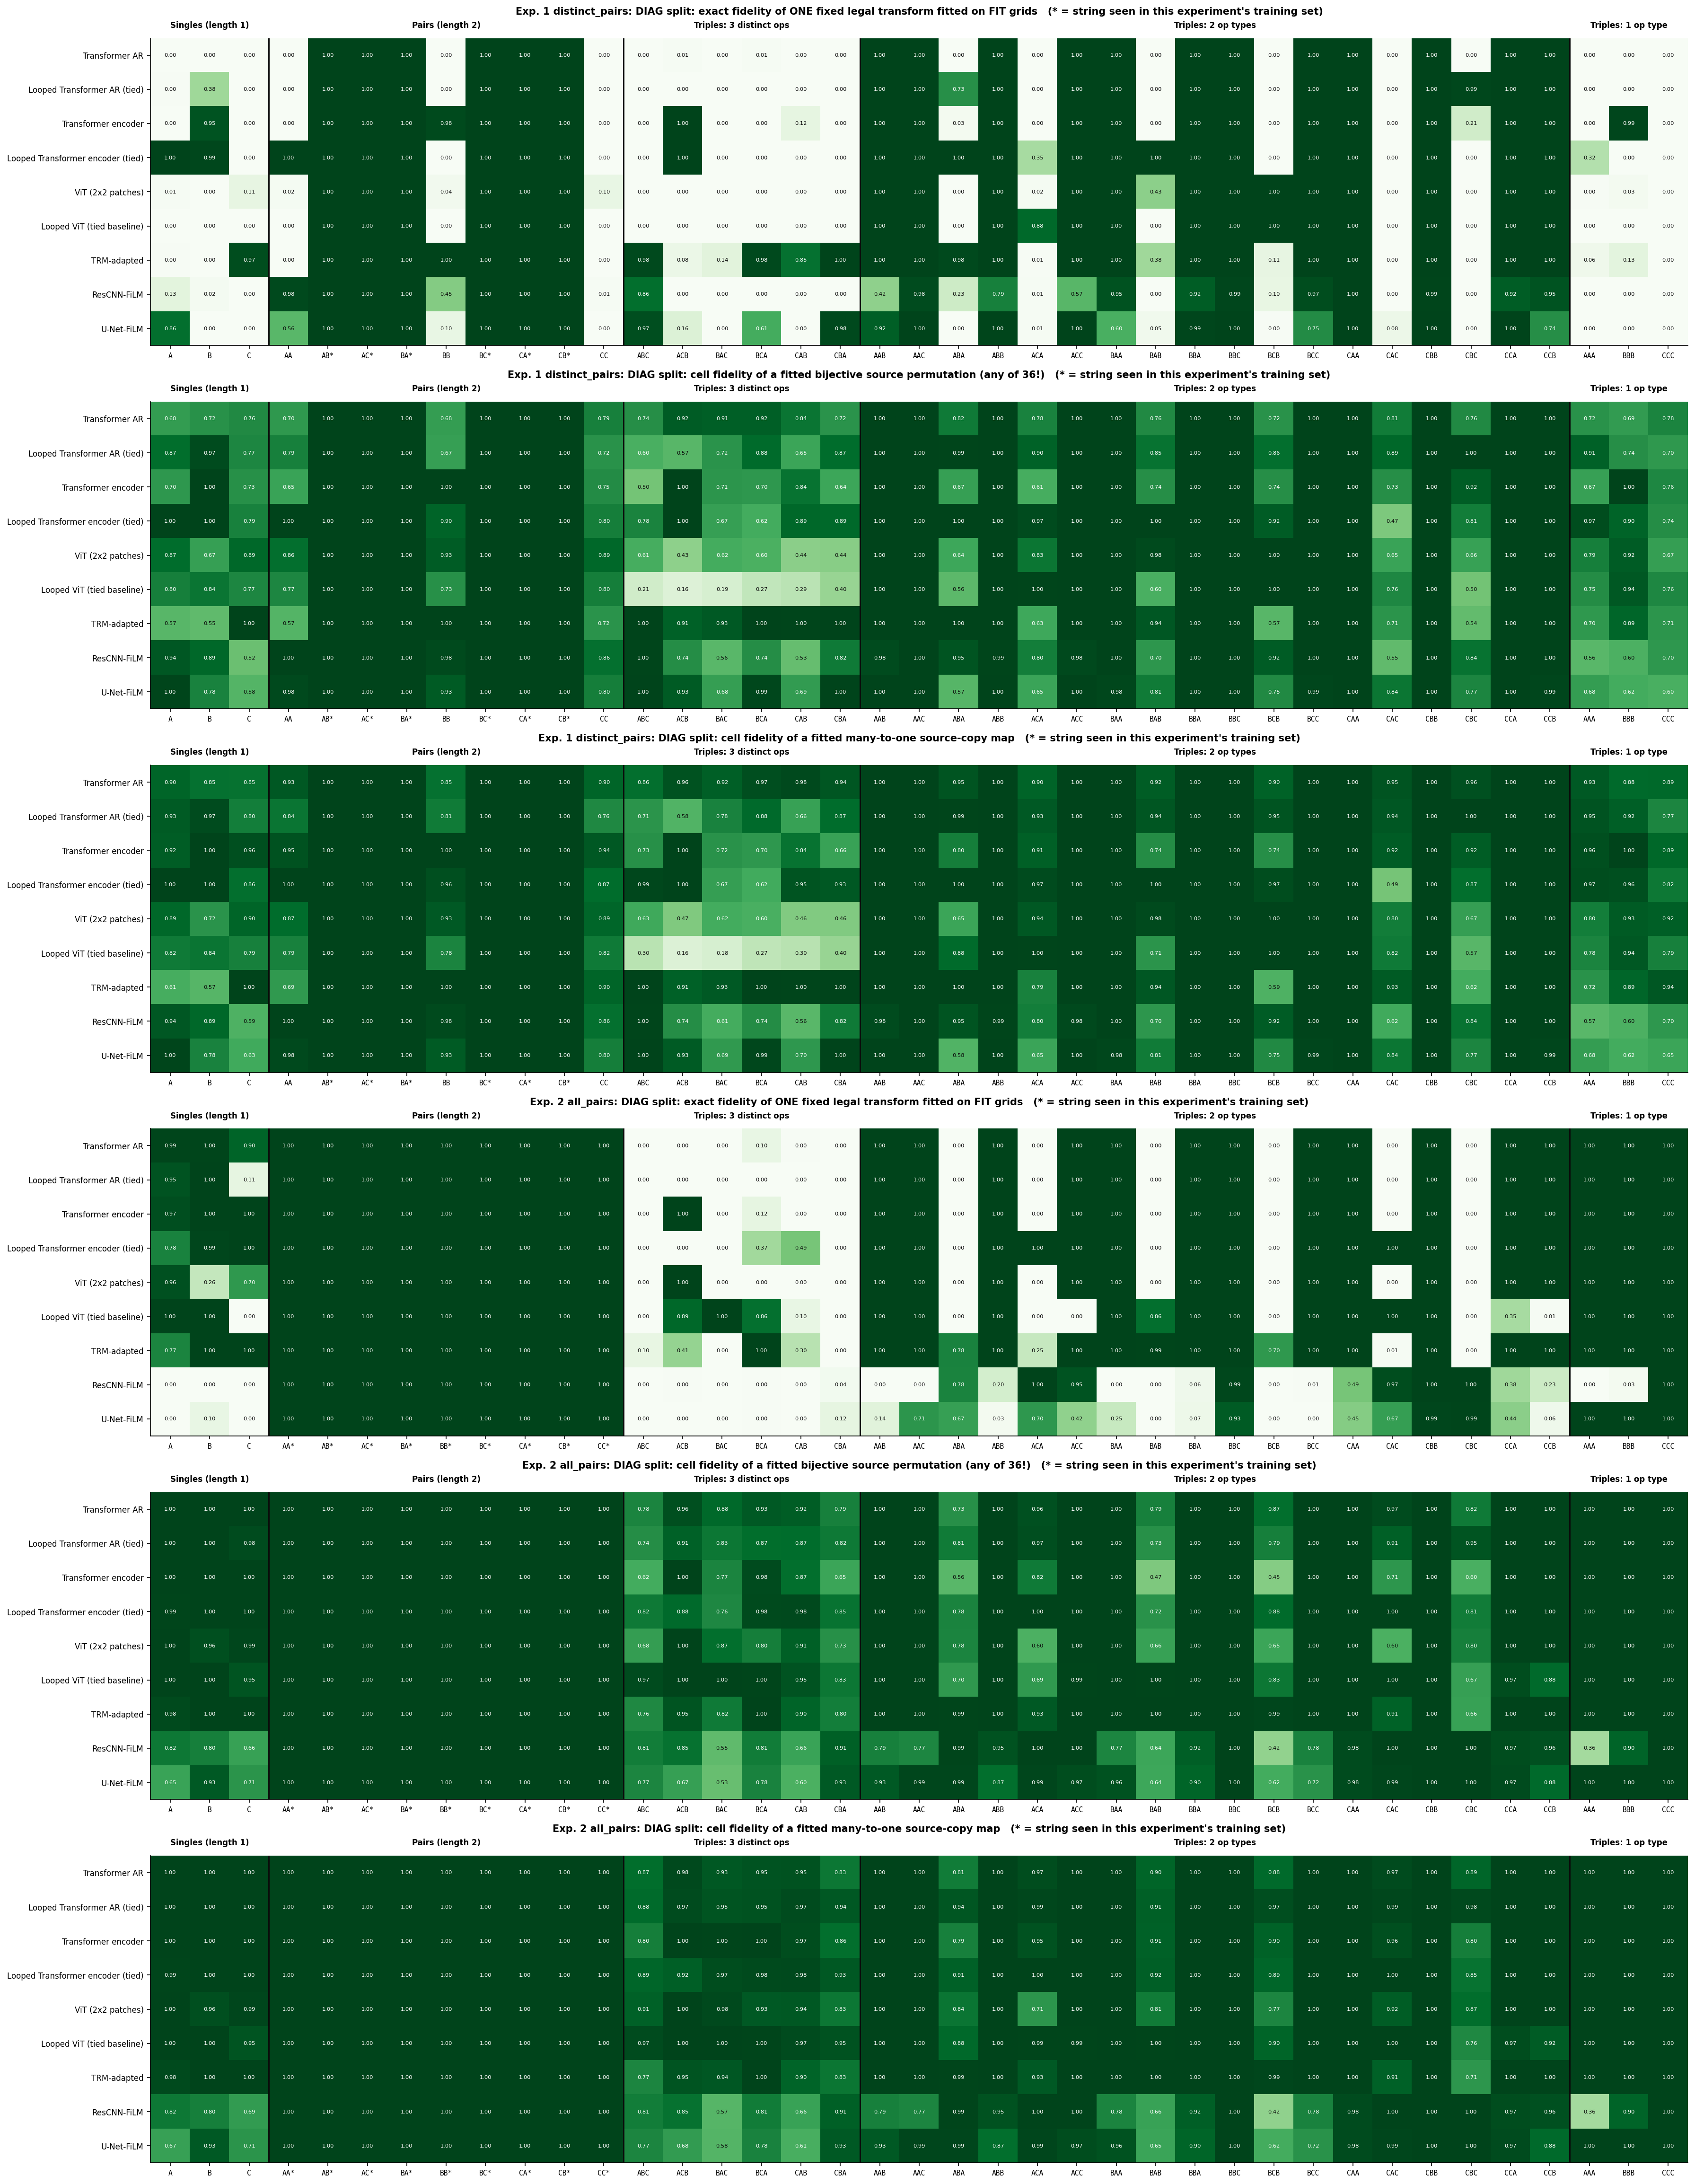

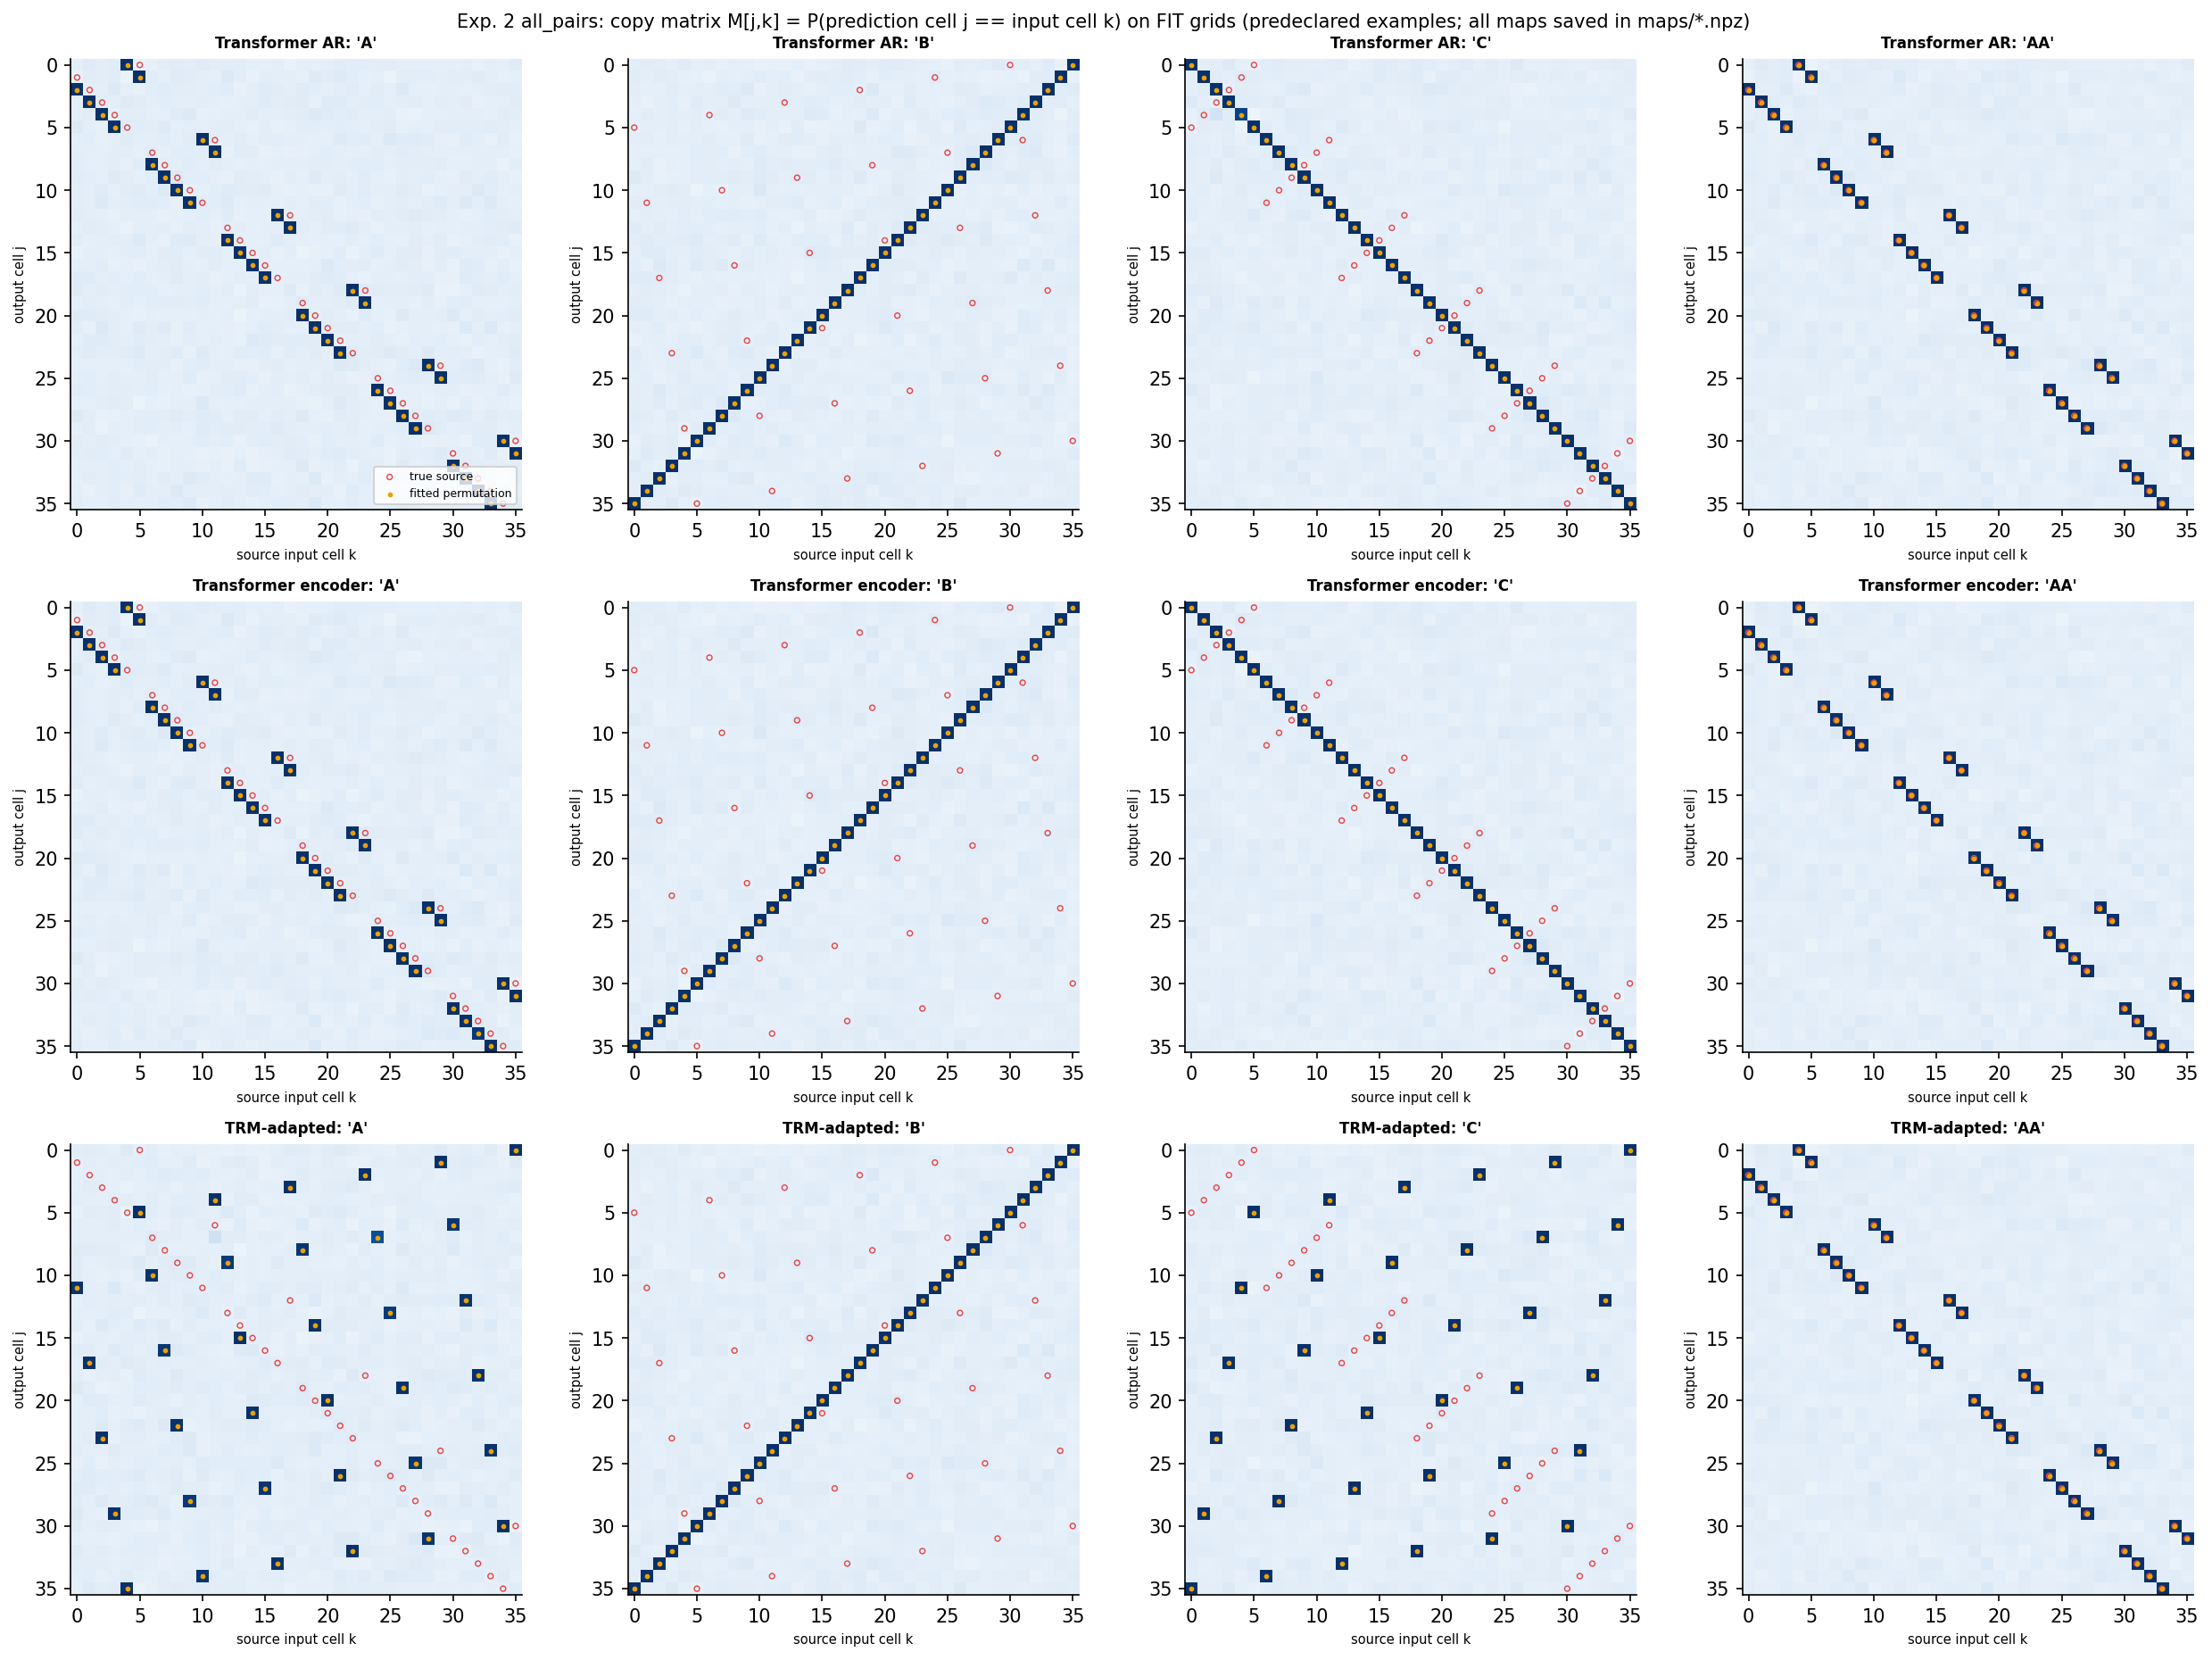

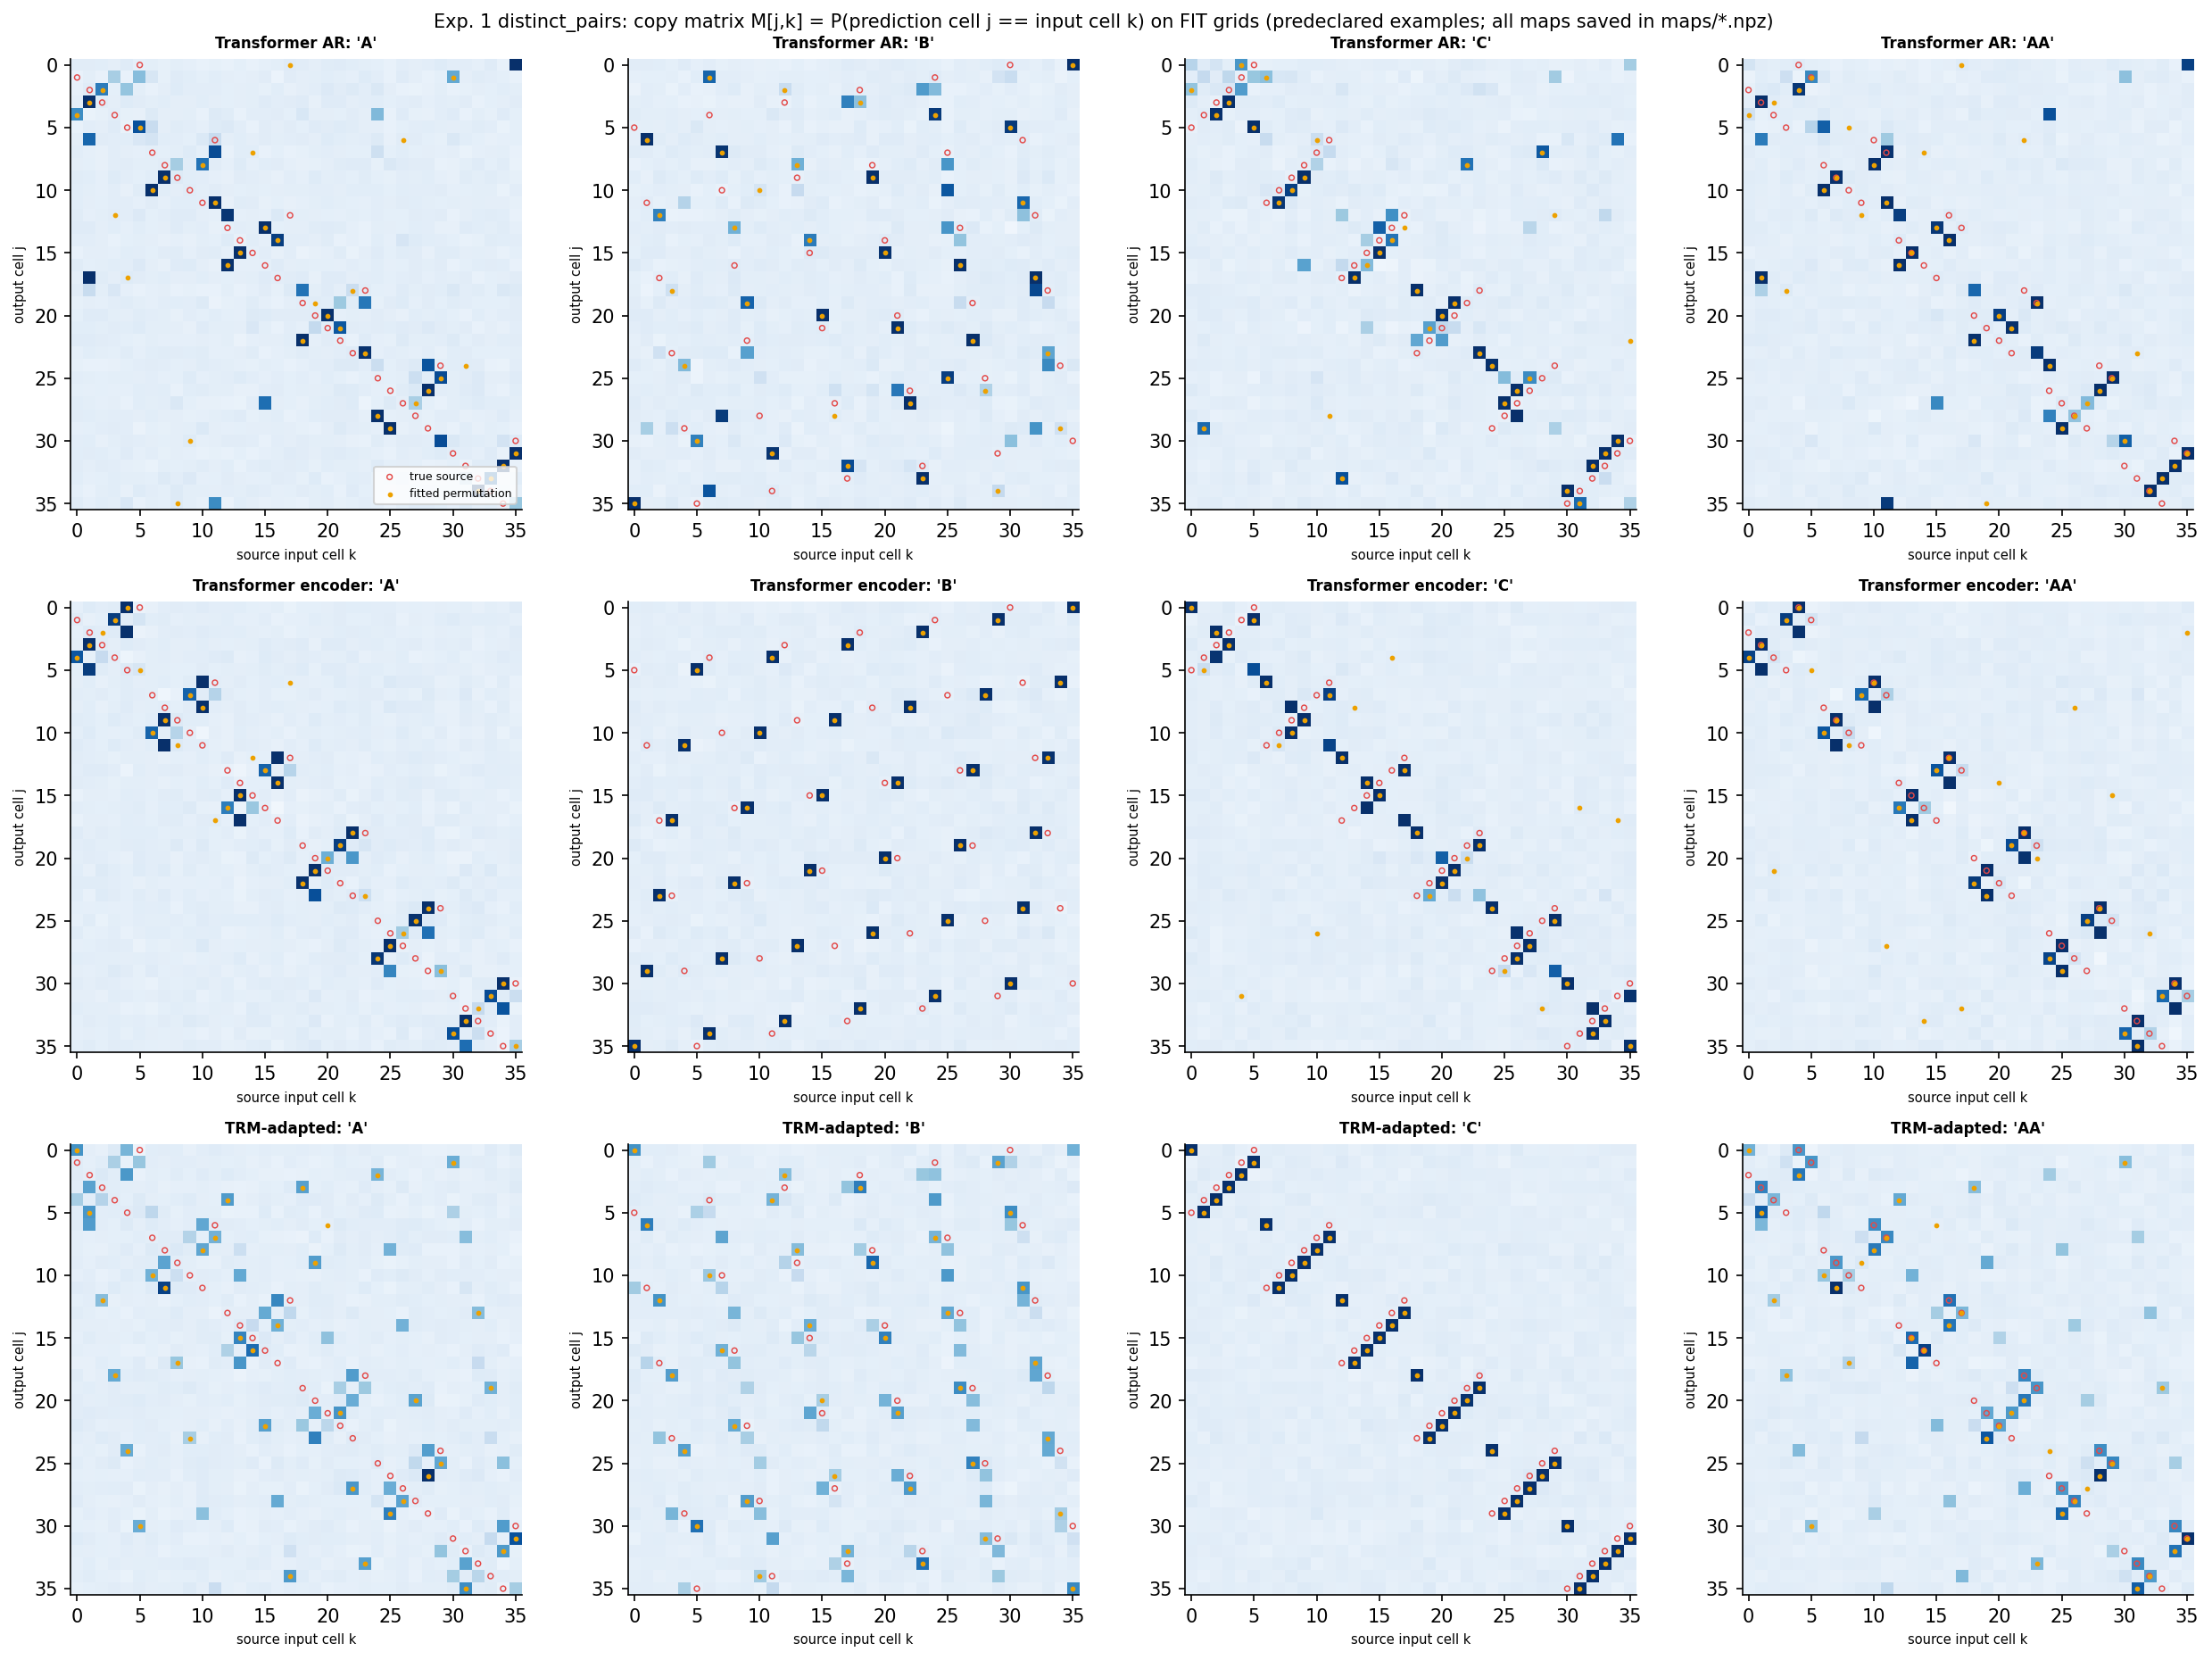

,experiment,model,string,selected_word,n_tied_rules,selected_is_truth,selected_is_alt_generator,selected_is_training_transform,fit_exact_fidelity,diag_exact_fidelity,diag_cell_fidelity
0,distinct_pairs,transformer_ar,A,AC,1,False,False,True,0.000,0.000,0.494278
1,distinct_pairs,transformer_ar,B,BC,1,False,False,True,0.000,0.000,0.667778
2,distinct_pairs,transformer_ar,C,AC,1,False,False,True,0.000,0.000,0.472500
3,distinct_pairs,transformer_ar,AA,CA,1,False,False,True,0.000,0.000,0.550500
4,distinct_pairs,transformer_ar,AB,AB,1,True,True,True,1.000,1.000,1.000000
5,distinct_pairs,transformer_ar,AC,AC,1,True,True,True,1.000,1.000,1.000000
6,distinct_pairs,transformer_ar,BA,BA,1,True,True,True,1.000,1.000,1.000000
7,distinct_pairs,transformer_ar,BB,BC,1,False,False,True,0.000,0.000,0.485278
8,distinct_pairs,transformer_ar,BC,BC,1,True,True,True,1.000,1.000,1.000000
9,distinct_pairs,transformer_ar,CA,CA,1,True,True,True,1.000,1.000,1.000000


experiment      model                       map_kind             
all_pairs       looped_transformer_ar       argmax_source_map         1
                                            bijective_permutation     8
                looped_transformer_encoder  argmax_source_map         3
                                            bijective_permutation     8
                looped_vit                  argmax_source_map         3
                                            bijective_permutation     6
                rescnn_film                 argmax_source_map        15
                                            bijective_permutation    15
                transformer_ar              argmax_source_map         6
                                            bijective_permutation     7
                transformer_encoder         argmax_source_map         4
                                            bijective_permutation    10
                trm                         argmax_source_map         3
                                            bijective_permutation     4
                unet_film                   argmax_source_map        13
                                            bijective_permutation    13
                vit                         argmax_source_map         6
                                            bijective_permutation    10
distinct_pairs  looped_transformer_ar       argmax_source_map        11
                                            bijective_permutation    16
                looped_transformer_encoder  argmax_source_map         7
                                            bijective_permutation    10
                looped_vit                  argmax_source_map        18
                                            bijective_permutation    18
                rescnn_film                 argmax_source_map        15
                                            bijective_permutation    15
                transformer_ar              argmax_source_map         8
                                            bijective_permutation    18
                transformer_encoder         argmax_source_map         9
                                            bijective_permutation    16
                trm                         argmax_source_map         9
                                            bijective_permutation    11
                unet_film                   argmax_source_map        14
                                            bijective_permutation    14
                vit                         argmax_source_map        15
                                            bijective_permutation    17
Name: weak/tie-driven maps, dtype: int64

In [10]:
# --- 7. Stable rules and general source maps (fitted on FIT grids from MODEL predictions; scored on DIAG grids) ---
show("08_stable"); show("10_source_maps")
sr = R["stable_rules"]
display(sr[["experiment", "model", "string", "selected_word", "n_tied_rules", "selected_is_truth", "selected_is_alt_generator",
            "selected_is_training_transform", "fit_exact_fidelity", "diag_exact_fidelity", "diag_cell_fidelity"]].head(60))
sm = R["source_maps"]
display(sm[sm.weak_or_tie_driven].groupby(["experiment", "model", "map_kind"]).size().rename("weak/tie-driven maps"))


## Composition and the half-period ambiguity
With Z = shift by (3, 3), the generators ZA, ZB, ZC reproduce every length-2 training example exactly but predict Z(target) for odd lengths. This checks an explicit explanation; it does not by itself show that this ambiguity caused the behaviour, and it cannot explain failures on unseen pairs.

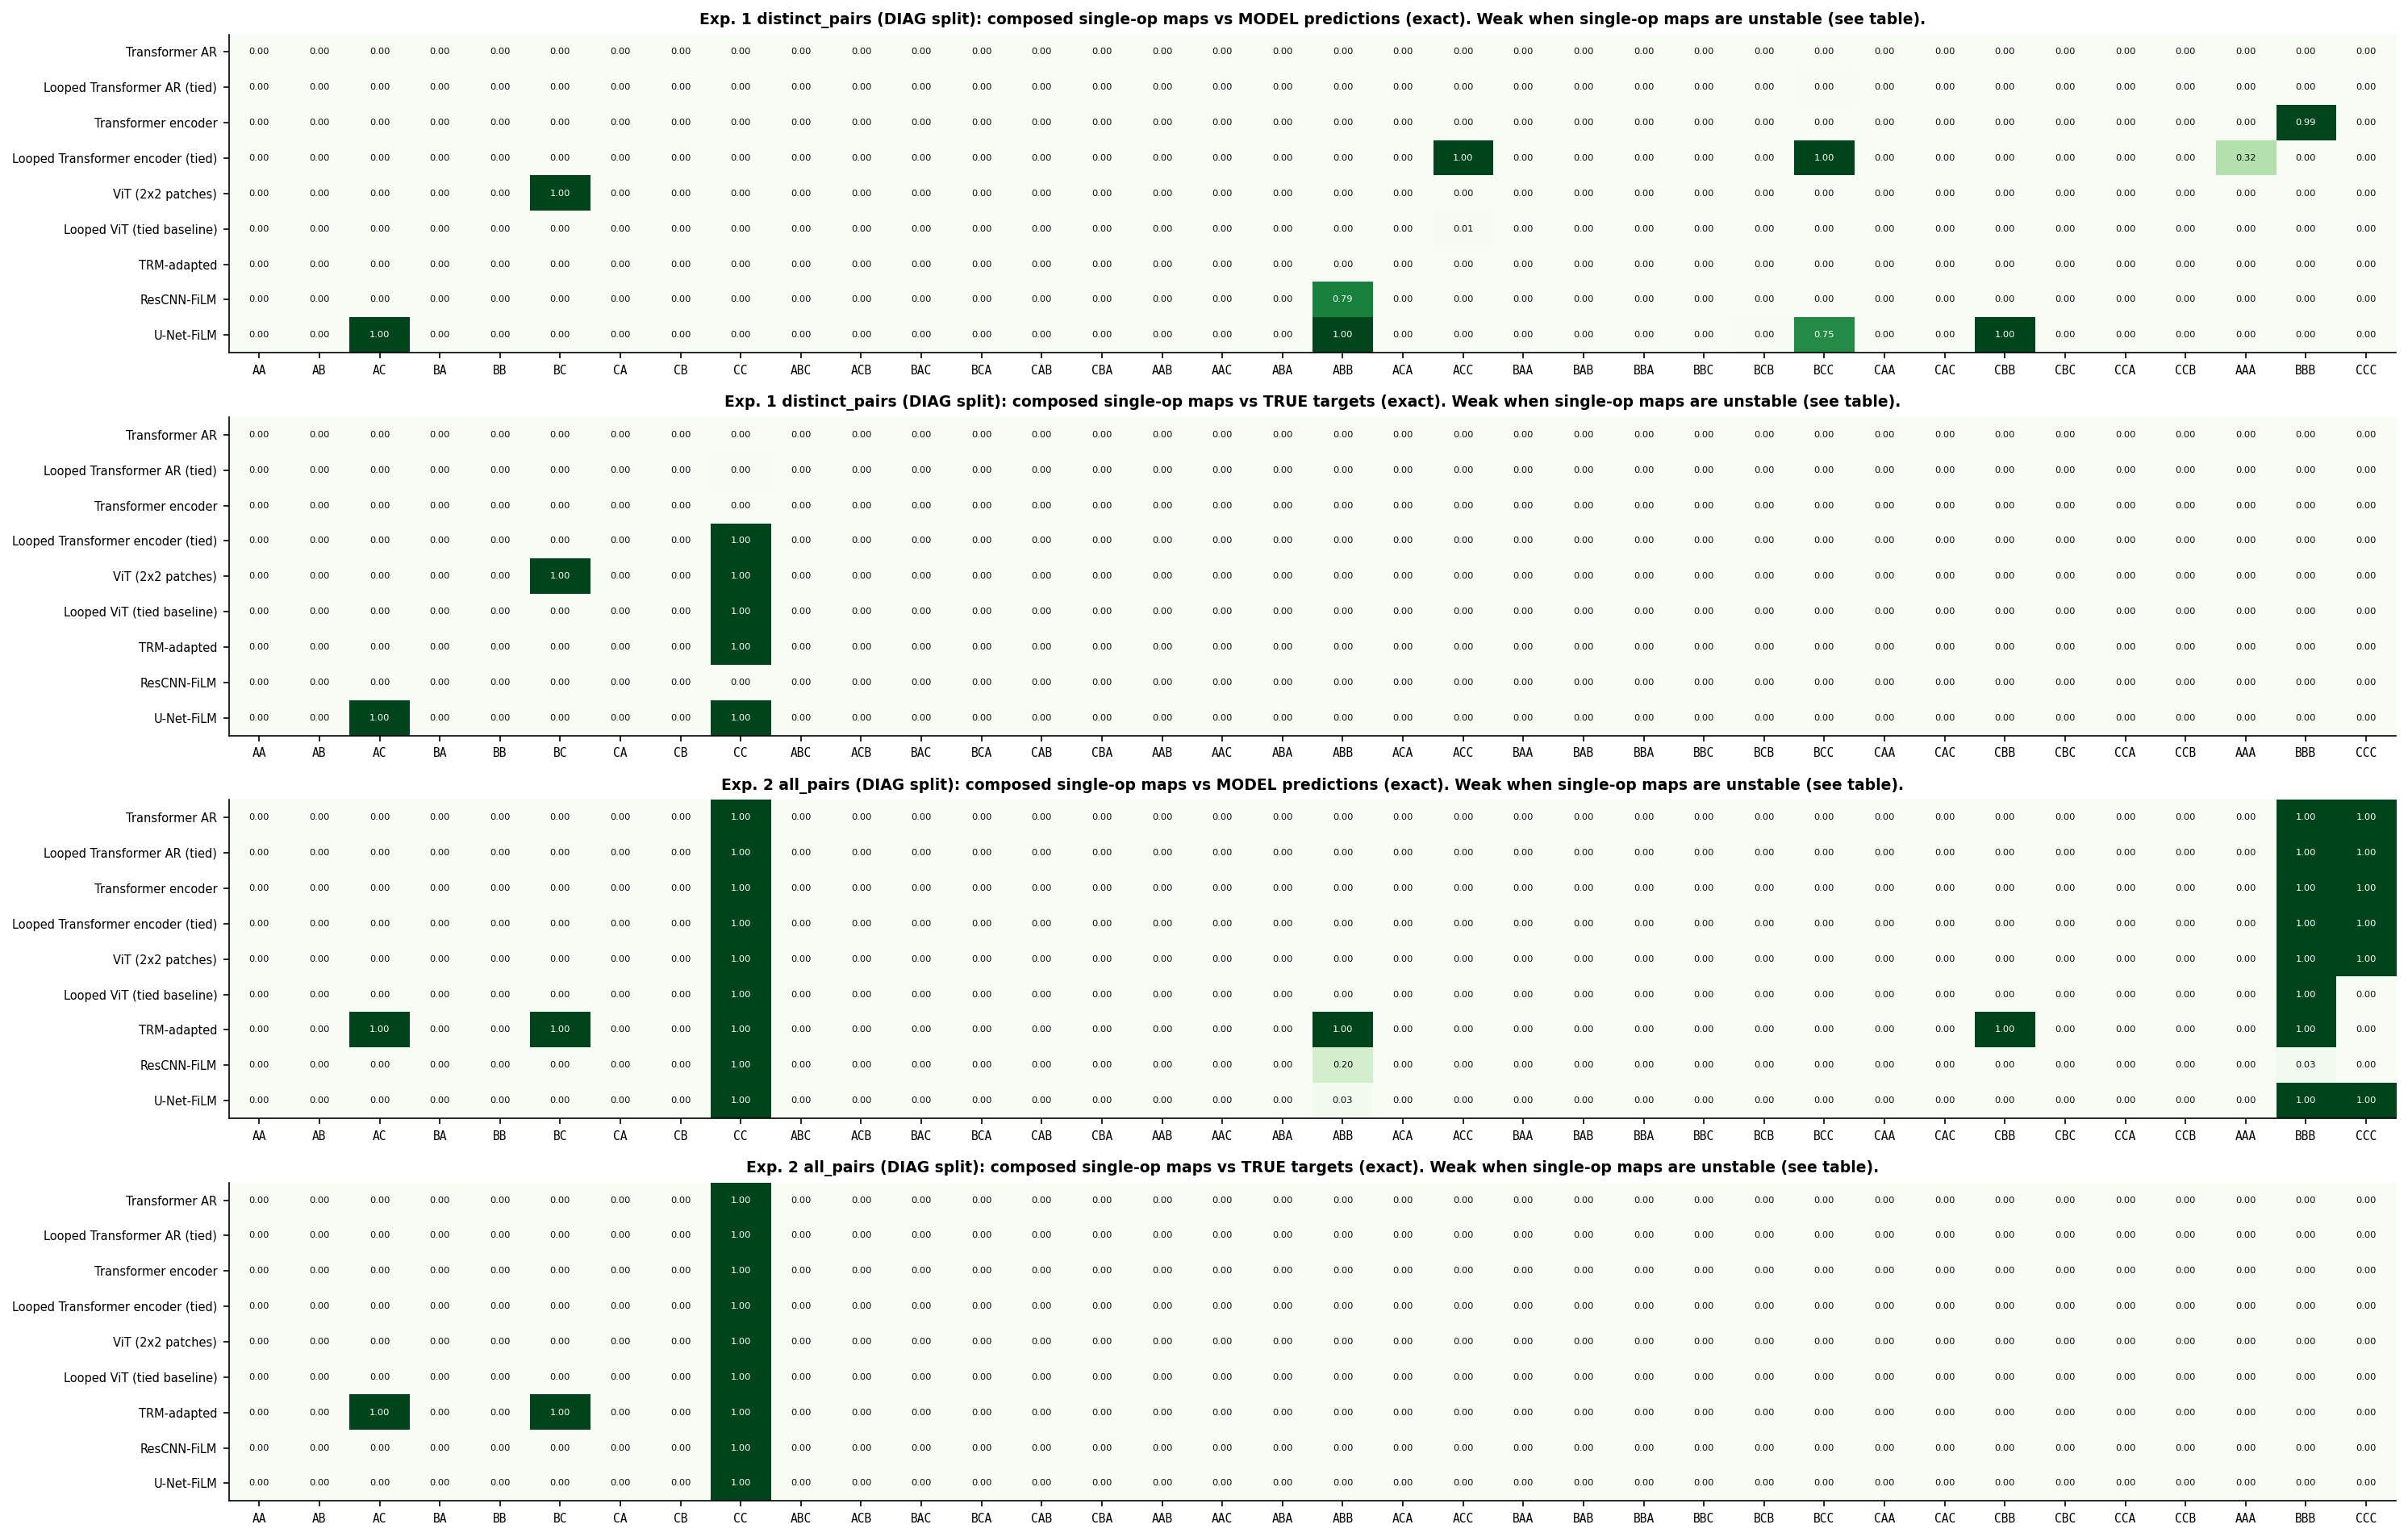

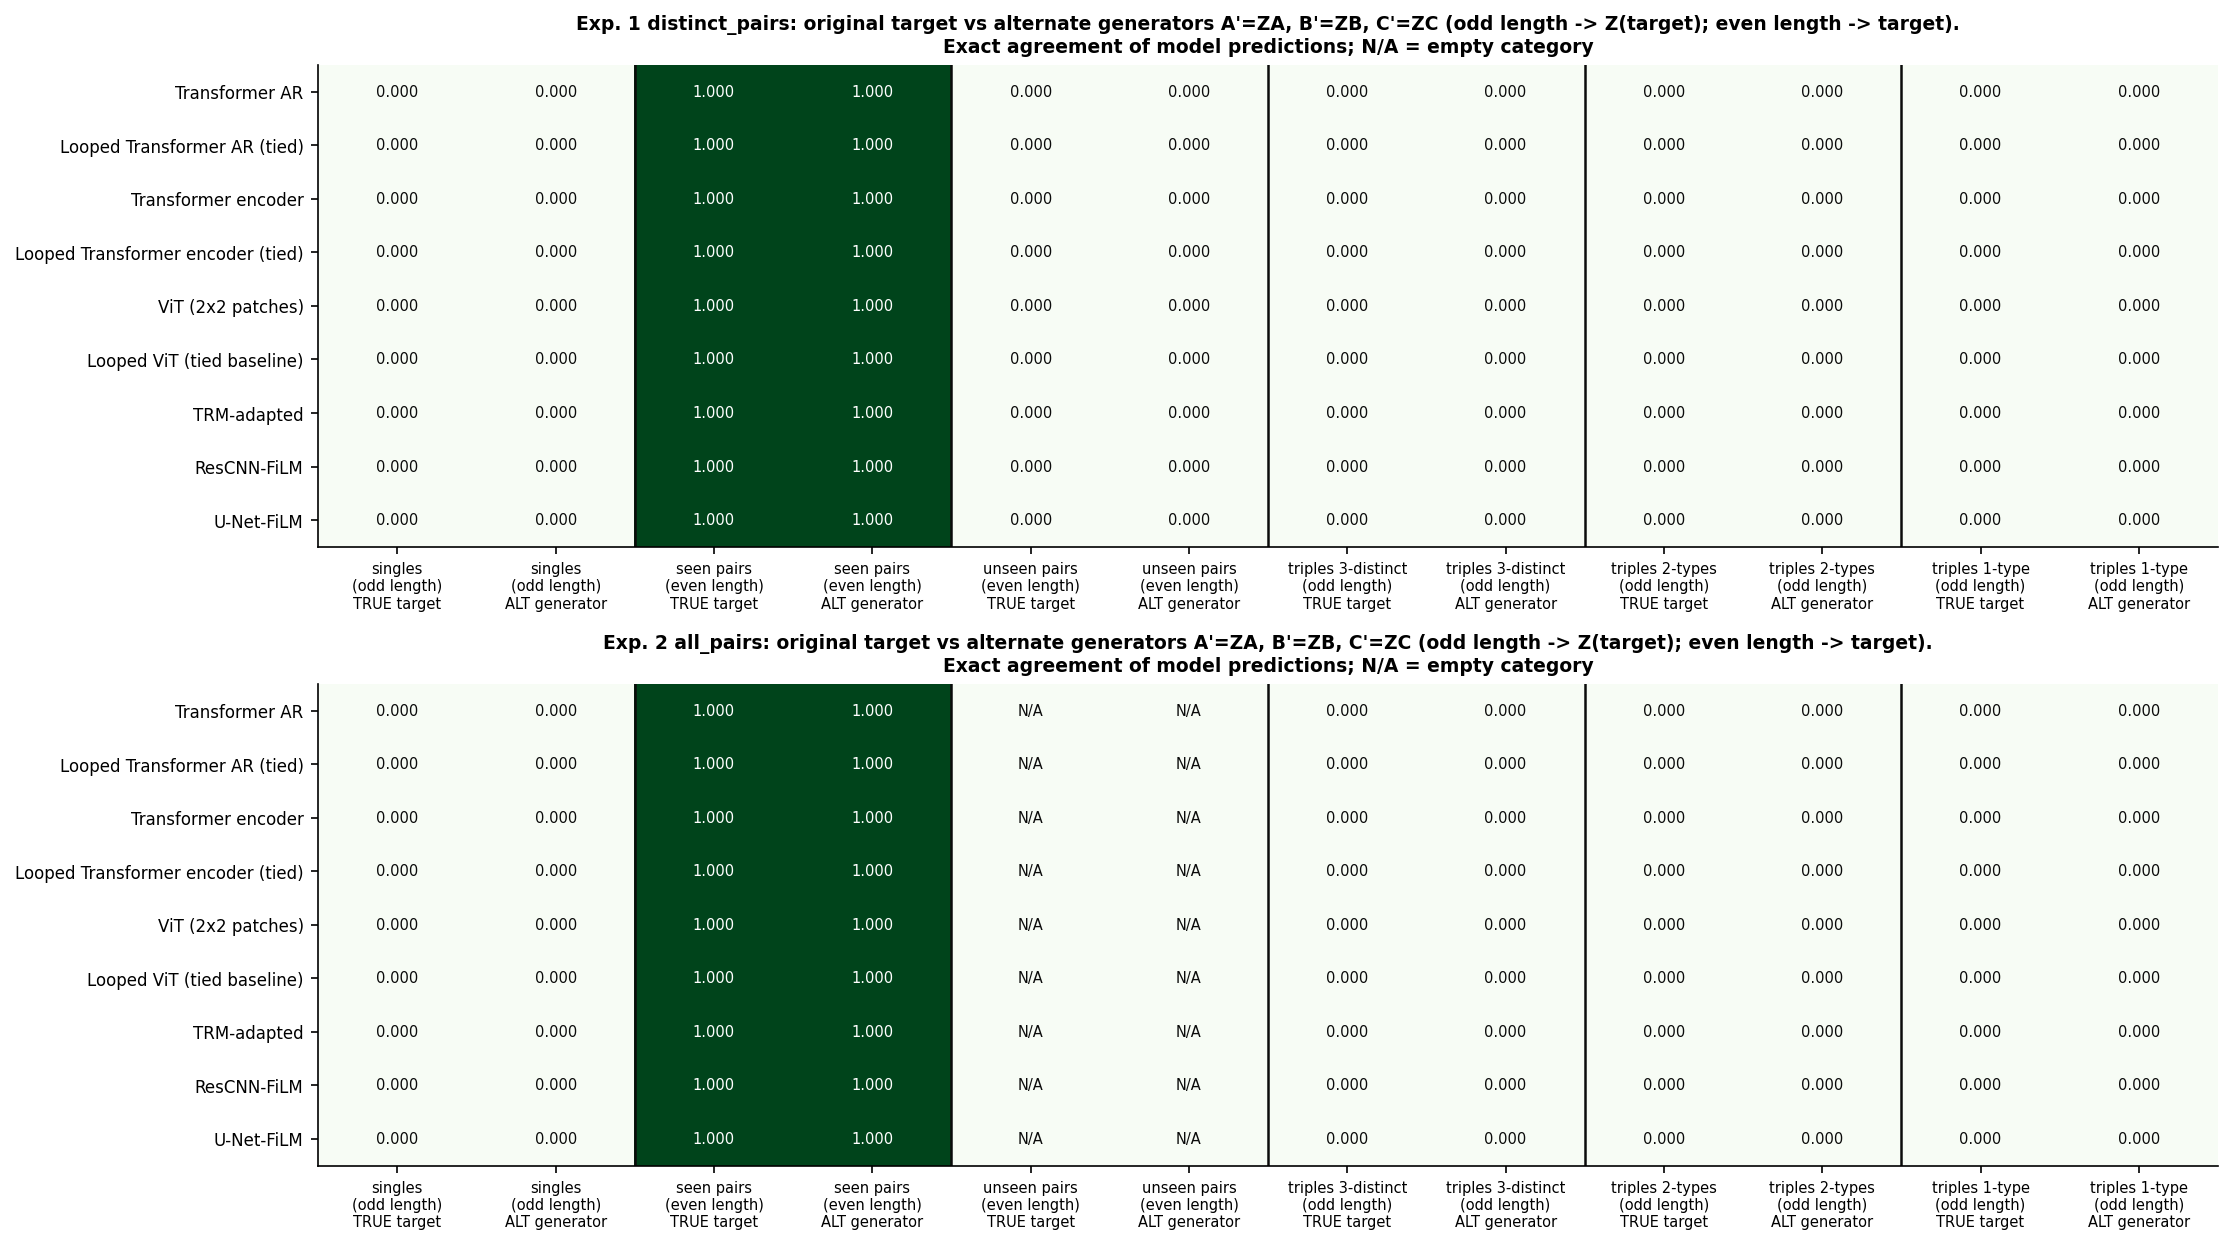

In [11]:
# --- 8. Composition consistency of fitted single-op maps, and the half-period (Z) ambiguity ---
show("09_composition"); show("07_alternate")
zt = R["z_table"]
display(zt.groupby(["experiment", "model", "parity"])[["exact_acc", "alt_generator_exact_rate", "alt_generator_cell_agreement"]]
        .mean().style.format("{:.4f}"))


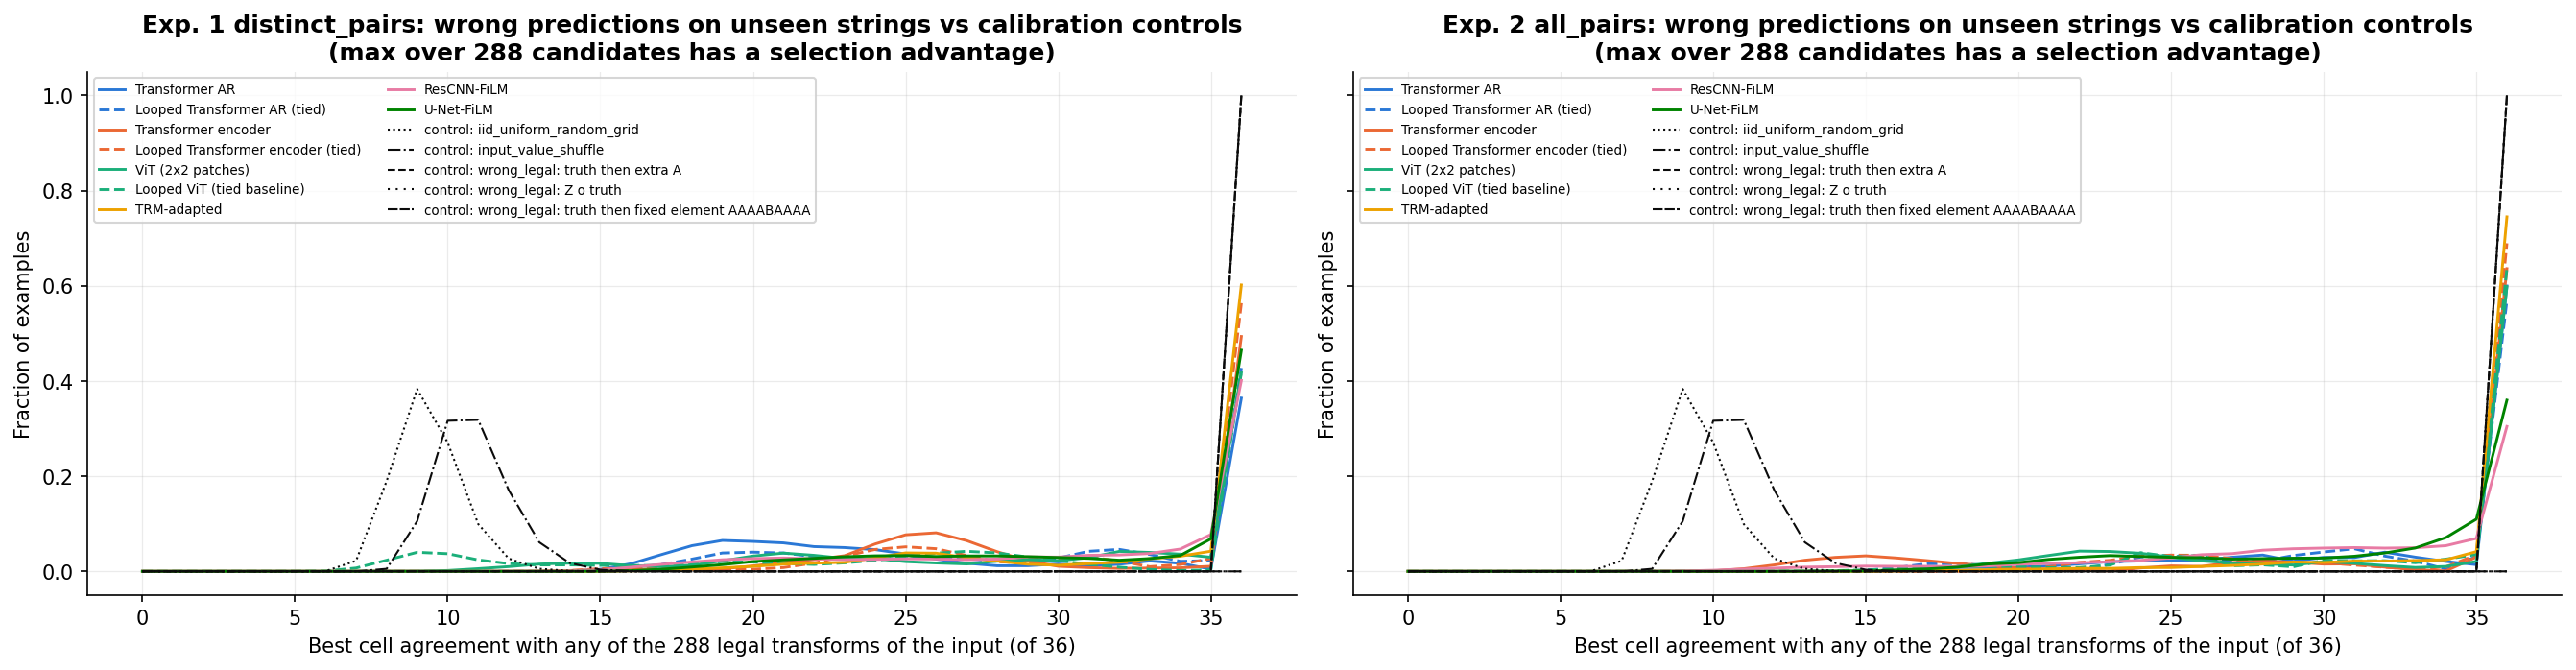

,control,n,exact_group_match_rate,ambiguous_exact_match_rate,mean_best_group_cell_agreement,p05_best,median_best,p95_best,cell_acc_vs_true_target
0,iid_uniform_random_grid,39000,0.0000,0.0000,0.2595,0.2222,0.2500,0.3056,0.1001
1,input_value_shuffle,39000,0.0000,0.0000,0.3006,0.2500,0.3056,0.3611,0.1255
2,wrong_legal: truth then extra A,39000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,0.1004
3,wrong_legal: Z o truth,39000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,0.0965
4,wrong_legal: truth then fixed element AAAABAAAA,39000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,0.1006


,comparison,positions_shared_k,expected_cell_acc_formula,empirical_cell_acc_on_base_grids,log10_exact_agreement_probability
0,A vs A+extra A,0,0.10,0.100750,-30
1,A vs Z o A,0,0.10,0.096500,-18
2,A vs fixed random element,2,0.15,0.152306,-25
3,A vs arbitrary map sharing 6 positions,6,0.25,0.250278,-27
4,A vs arbitrary map sharing 12 positions,12,0.40,0.400944,-21
5,A vs arbitrary map sharing 18 positions,18,0.55,0.549639,-17
6,A vs arbitrary map sharing 30 positions,30,0.85,0.850389,-4


A wrong permutation sharing k of 36 source positions with the truth has expected cell accuracy k/36 + (1-k/36)/10 on iid uniform digits; e.g. an extra right shift (k=0) gives 0.10 and exact agreement probability 10^-30, an extra Z gives 0.10 and 10^-18. Exact accuracy 0 with cell accuracy ~0.10 is therefore compatible with highly structured errors.


In [12]:
# --- 9. Calibration: what low cell accuracy can mean ---
show("06_nearest")
display(R["controls"]["summary"].style.format(precision=4))
display(R["controls"]["formula_check"])
print("A wrong permutation sharing k of 36 source positions with the truth has expected cell accuracy k/36 + (1-k/36)/10 "
      "on iid uniform digits; e.g. an extra right shift (k=0) gives 0.10 and exact agreement probability 10^-30, an extra Z "
      "gives 0.10 and 10^-18. Exact accuracy 0 with cell accuracy ~0.10 is therefore compatible with highly structured errors.")


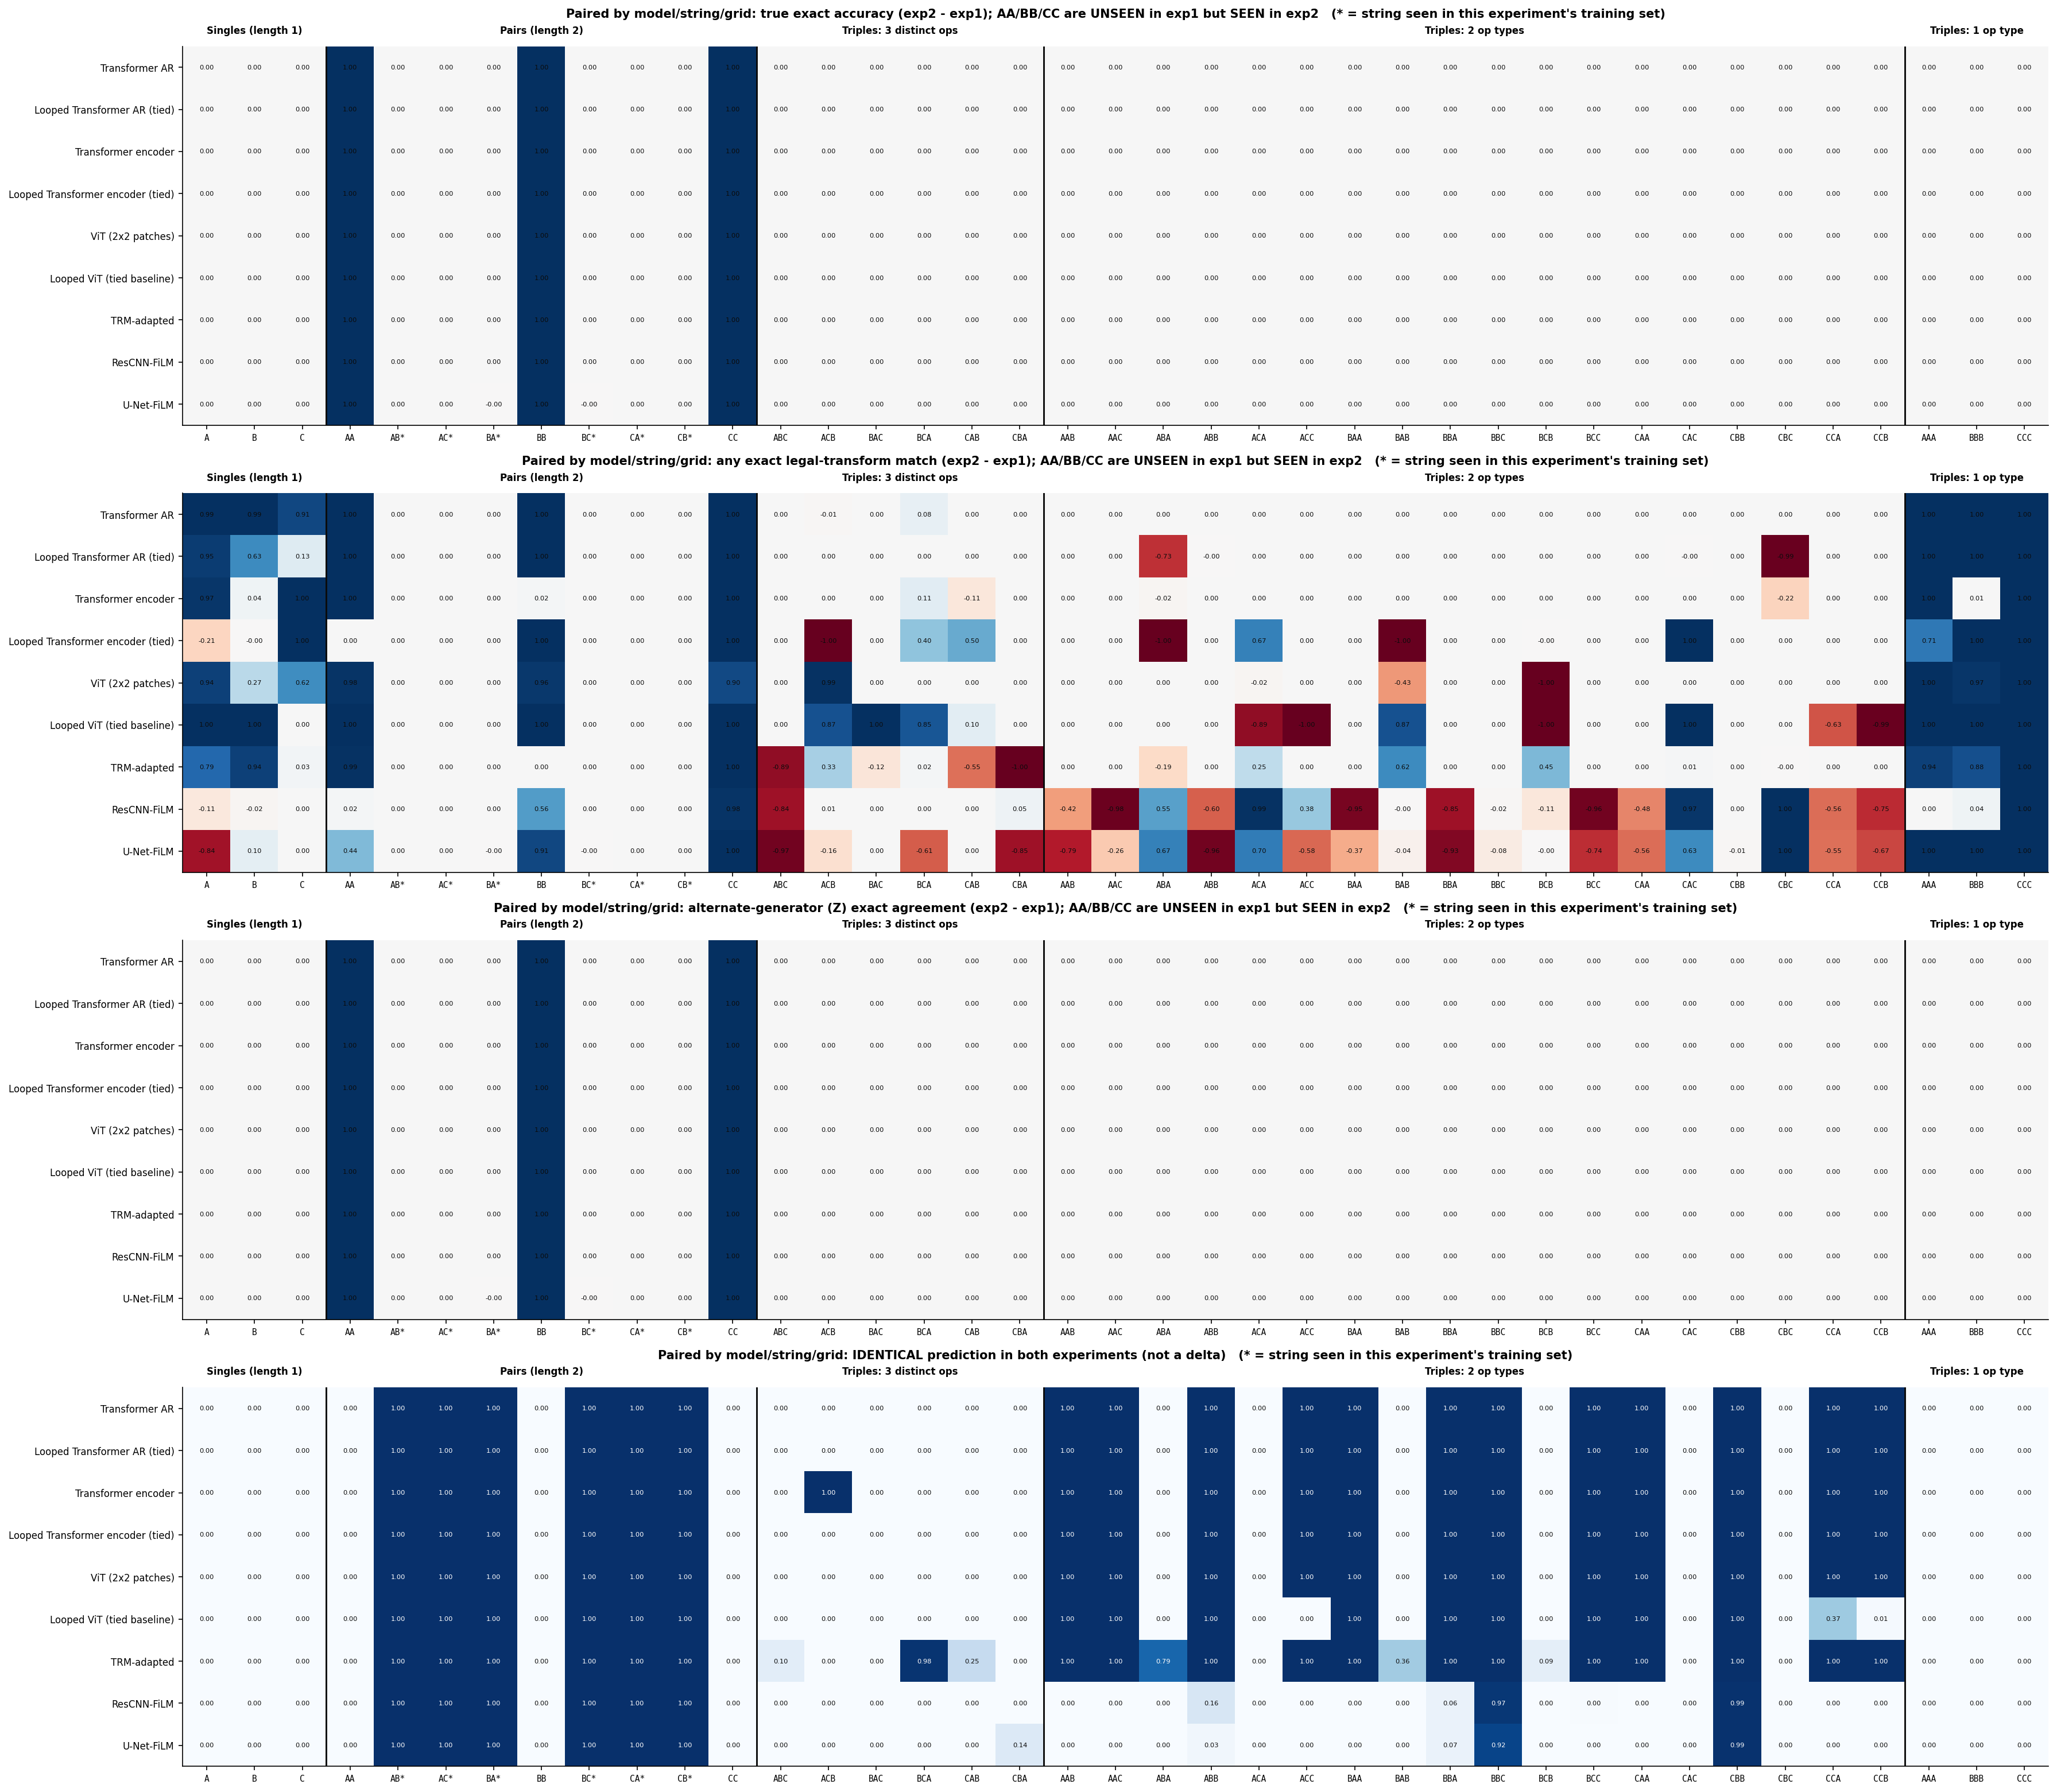

,identical_prediction_rate,same_unique_wrong_element_rate,delta_exact (all_pairs - distinct_pairs),delta_any_legal (all_pairs - distinct_pairs),delta_alt_generator_exact (all_pairs - distinct_pairs)
model,,,,,
looped_transformer_ar,0.4615,0.3076,0.0769,0.1532,0.0769
looped_transformer_encoder,0.4615,0.3077,0.0769,0.1303,0.0769
looped_vit,0.3945,0.2407,0.0769,0.2102,0.0769
rescnn_film,0.2100,0.0561,0.0769,-0.0283,0.0769
transformer_ar,0.4615,0.3077,0.0769,0.2301,0.0769
transformer_encoder,0.4872,0.3333,0.0769,0.1486,0.0769
trm,0.5276,0.3738,0.0769,0.1407,0.0769
unet_film,0.2087,0.0549,0.0769,-0.0396,0.0769
vit,0.4615,0.3077,0.0769,0.1839,0.0769


In [13]:
# --- 10. Paired comparison of the two experiments (same model, string and base grid) ---
show("11_paired")
p = R["paired"]
if len(p):
    display(p.groupby(["model"])[["identical_prediction_rate", "same_unique_wrong_element_rate",
                                  "delta_exact (all_pairs - distinct_pairs)", "delta_any_legal (all_pairs - distinct_pairs)",
                                  "delta_alt_generator_exact (all_pairs - distinct_pairs)"]].mean().style.format("{:.4f}"))
else:
    print("Paired comparison unavailable: a model needs predictions in BOTH experiments.")


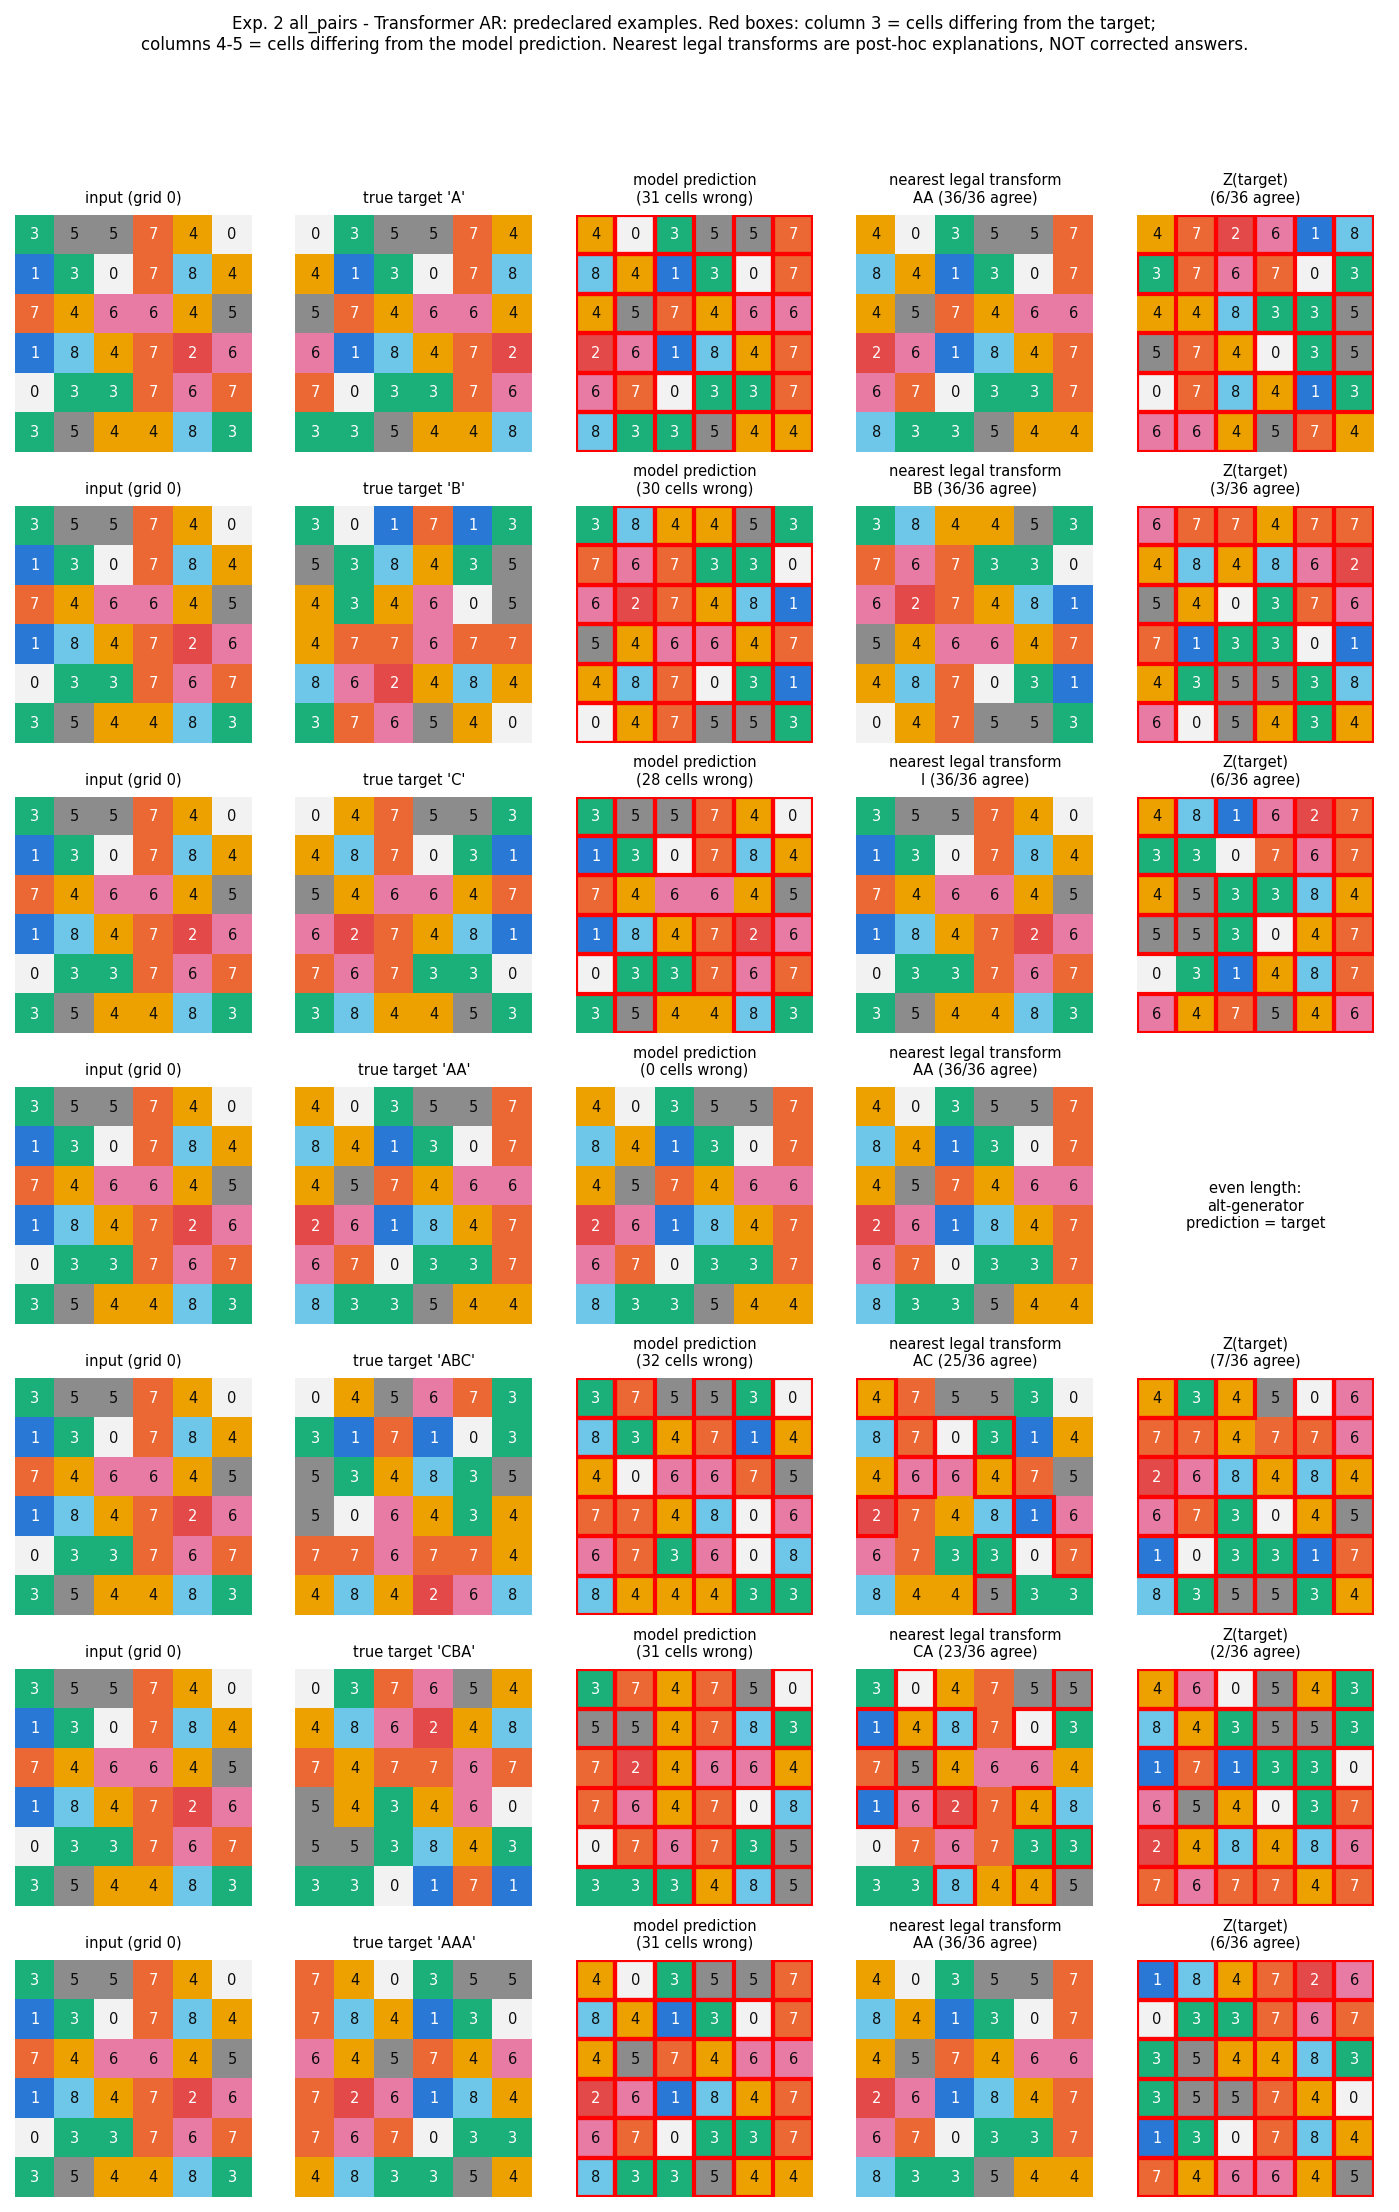

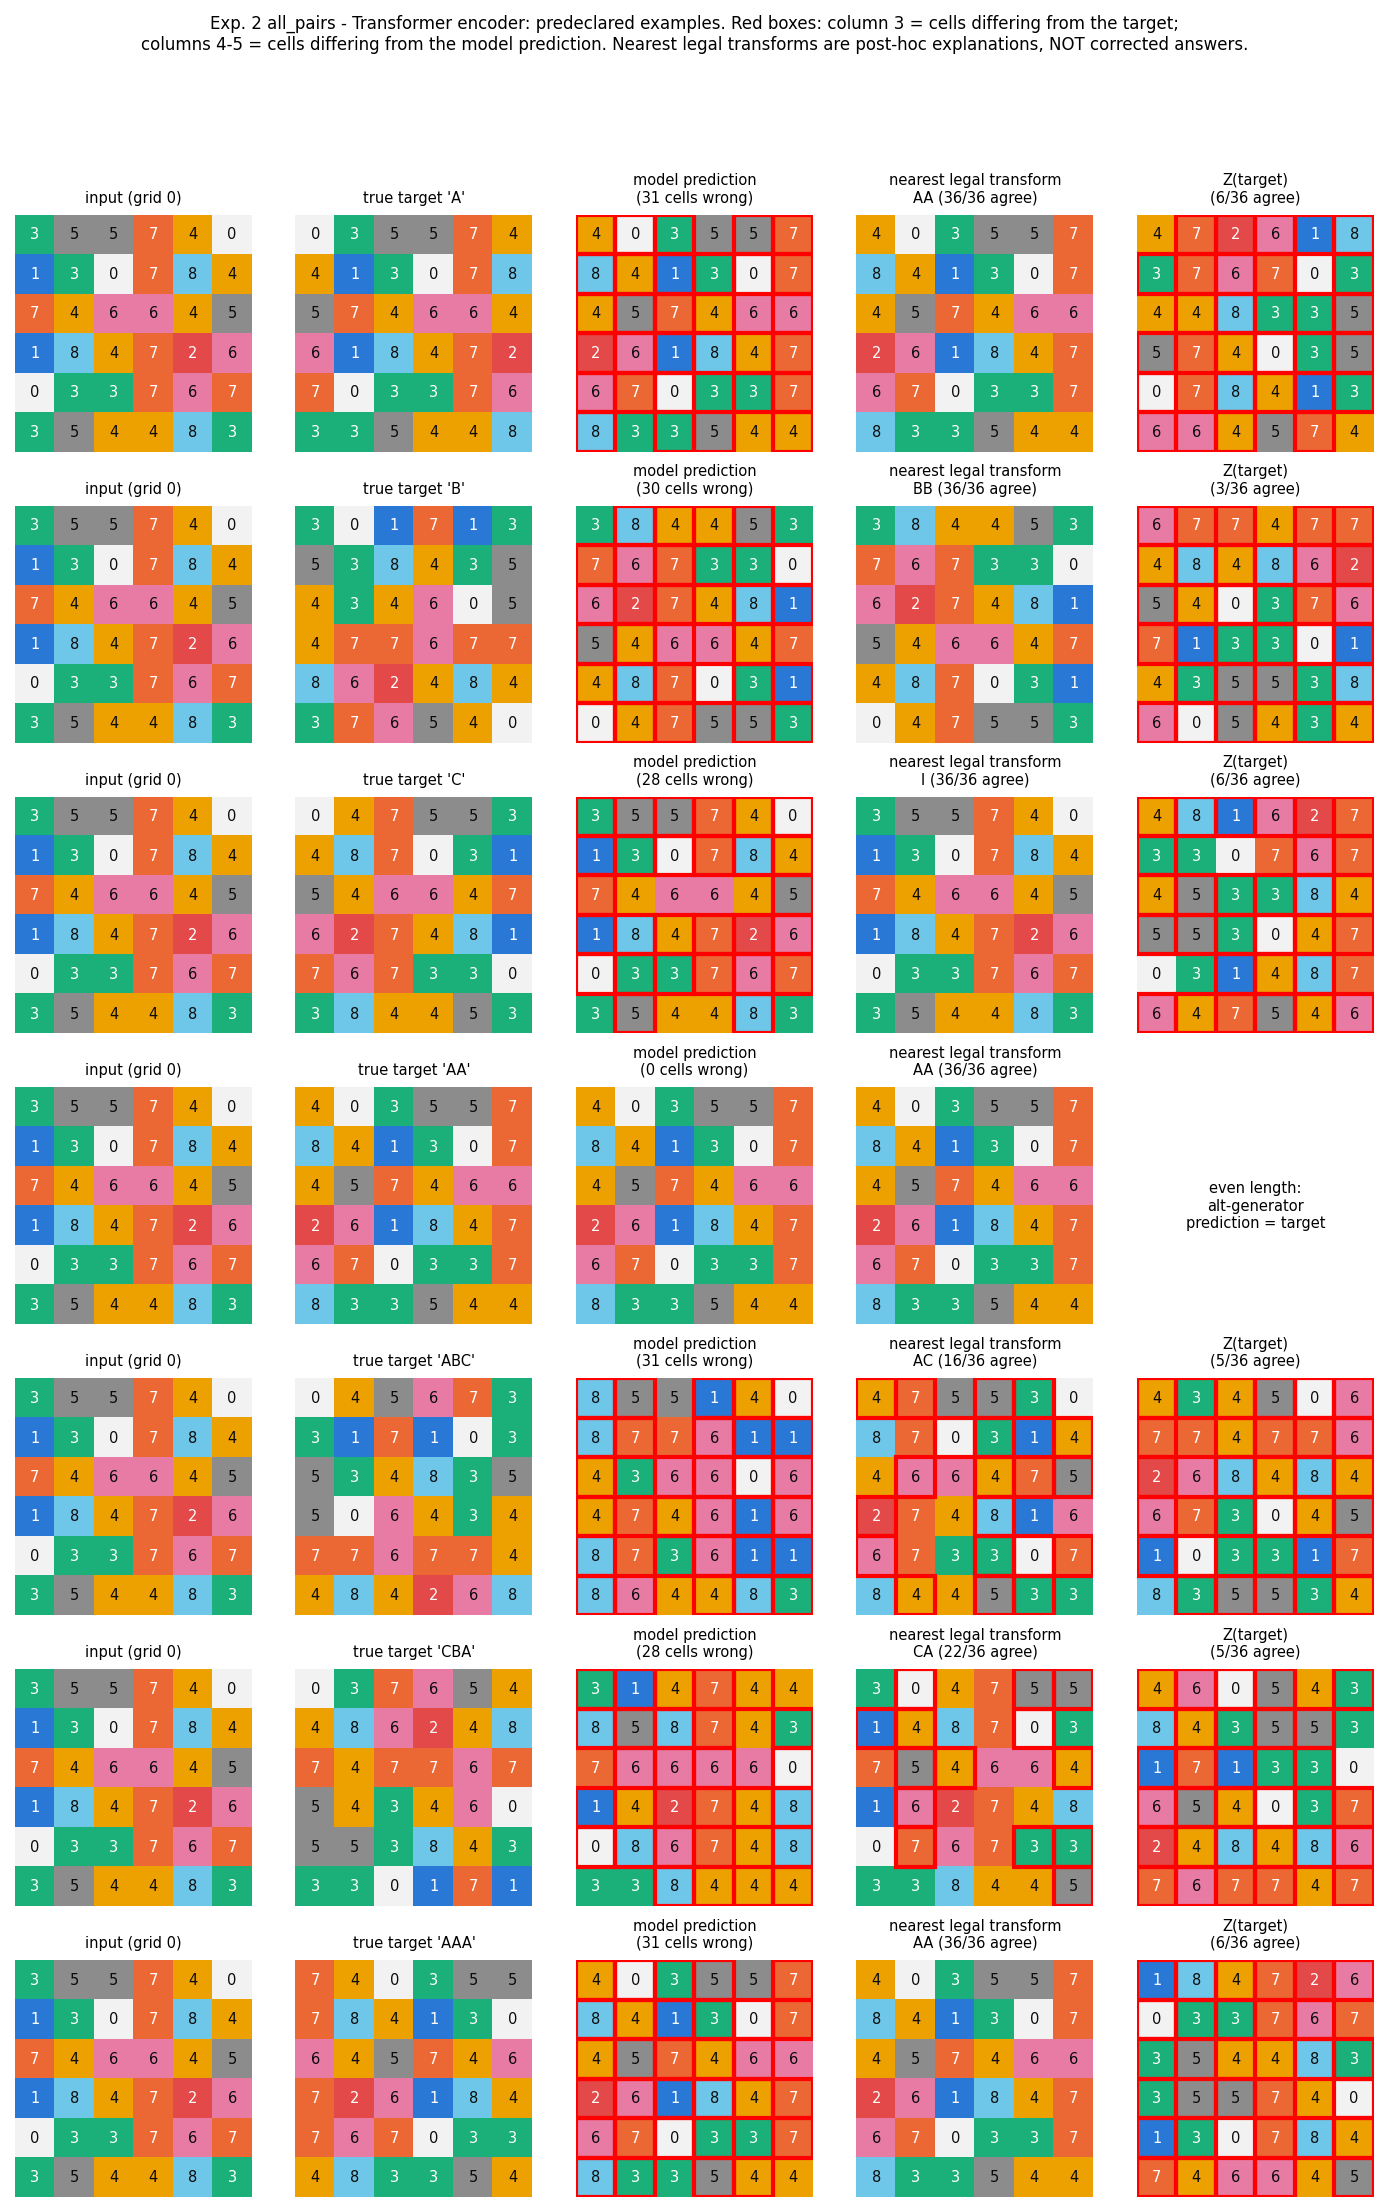

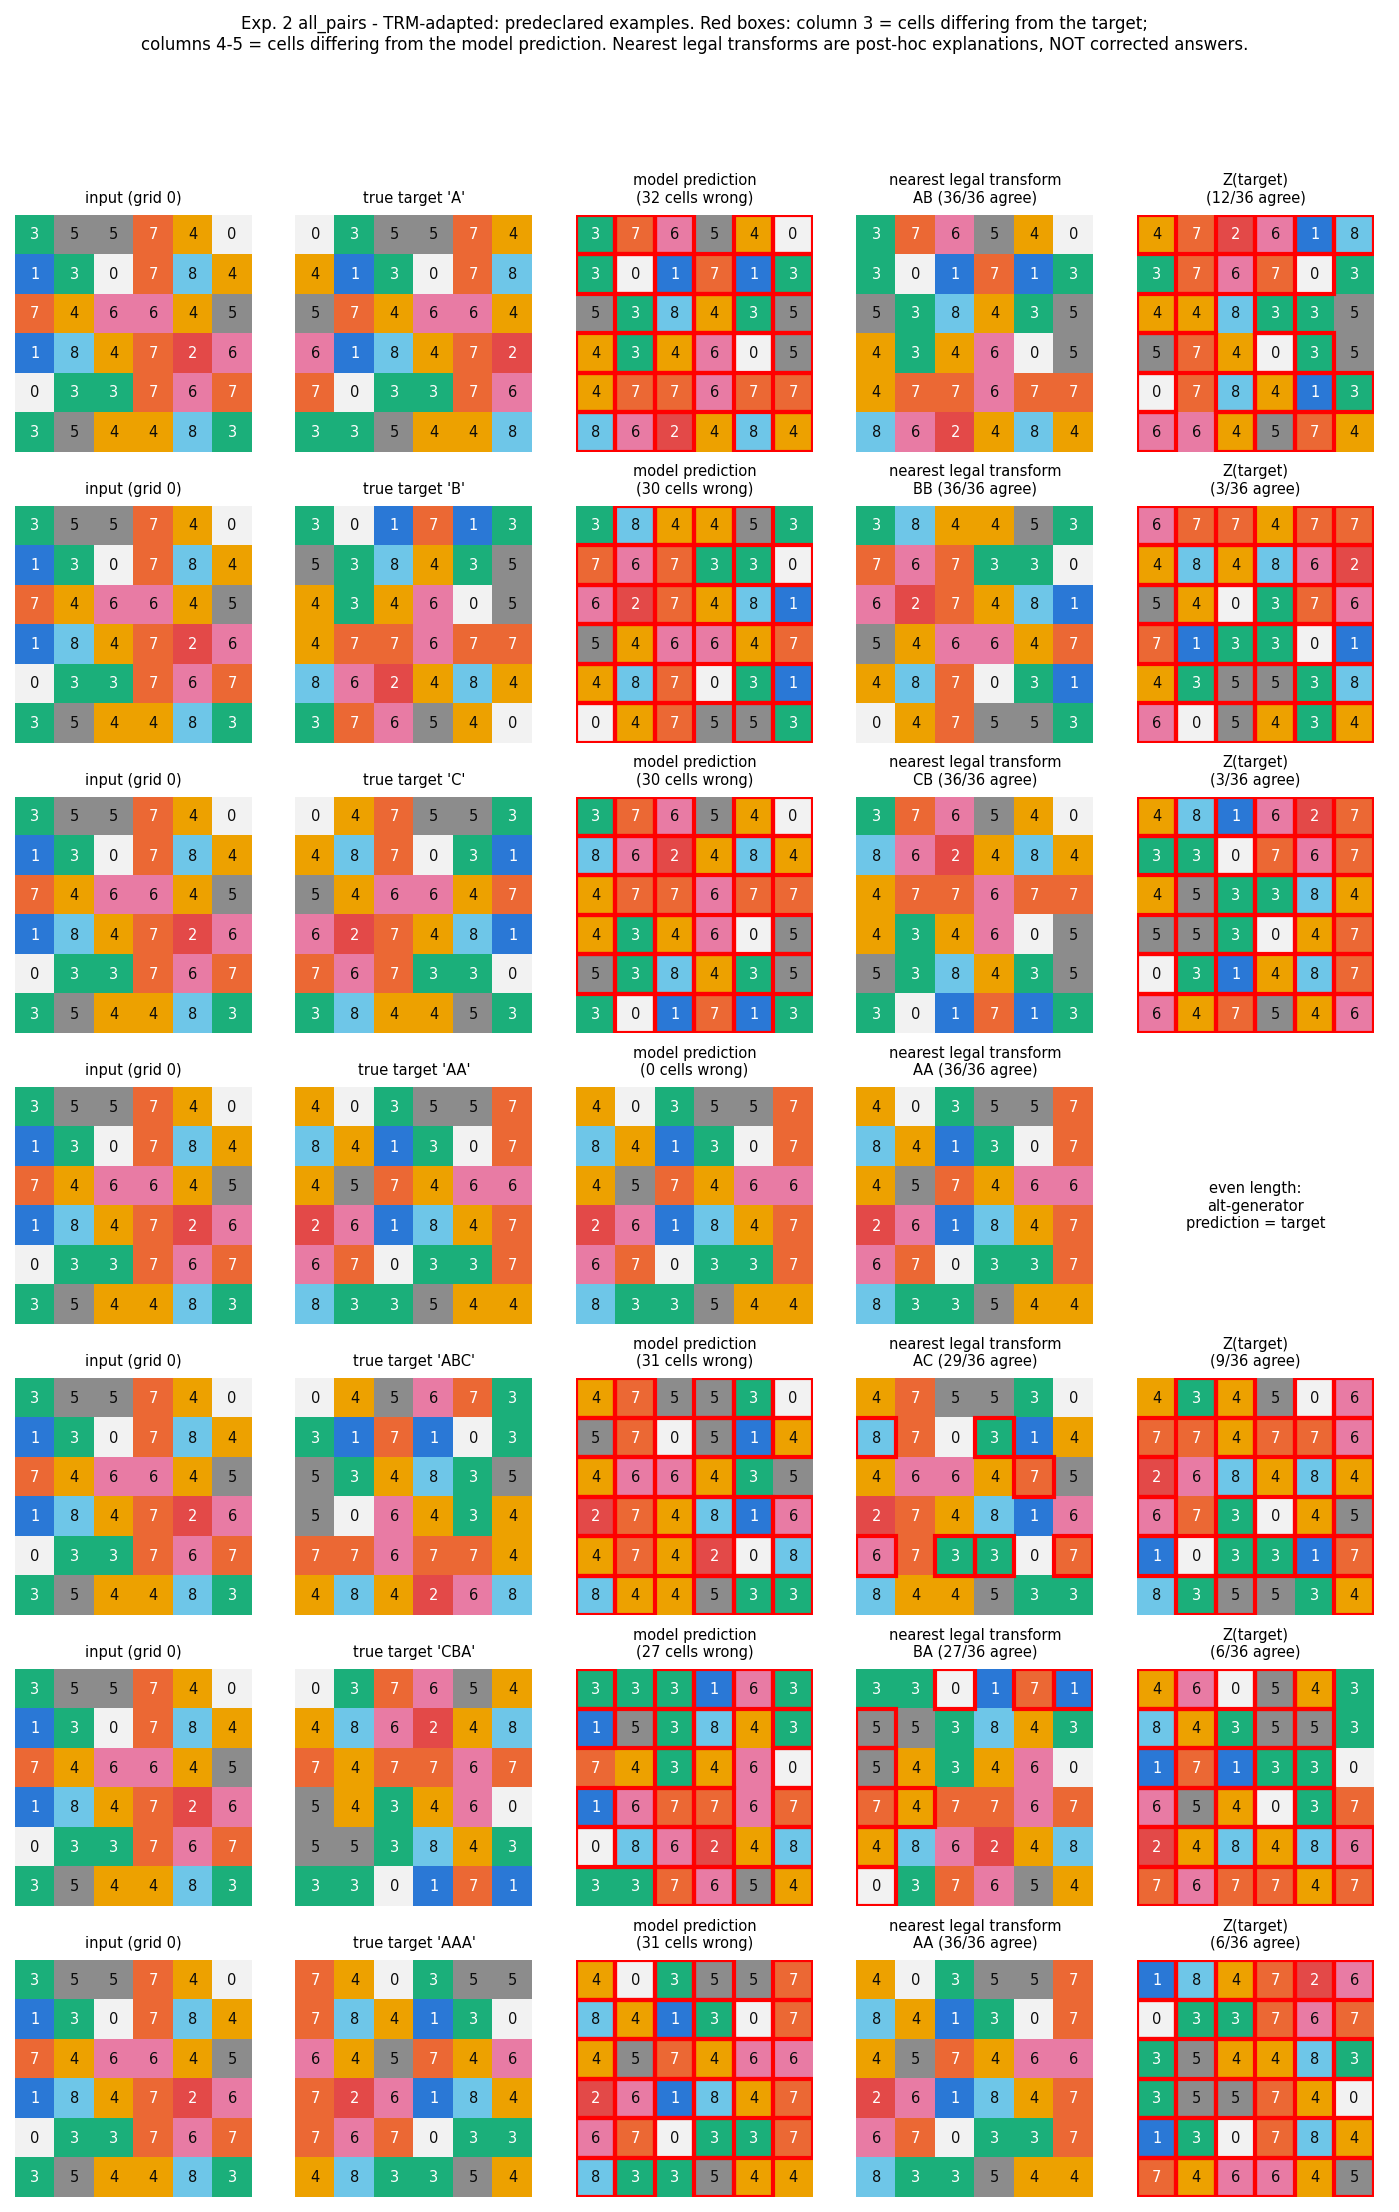

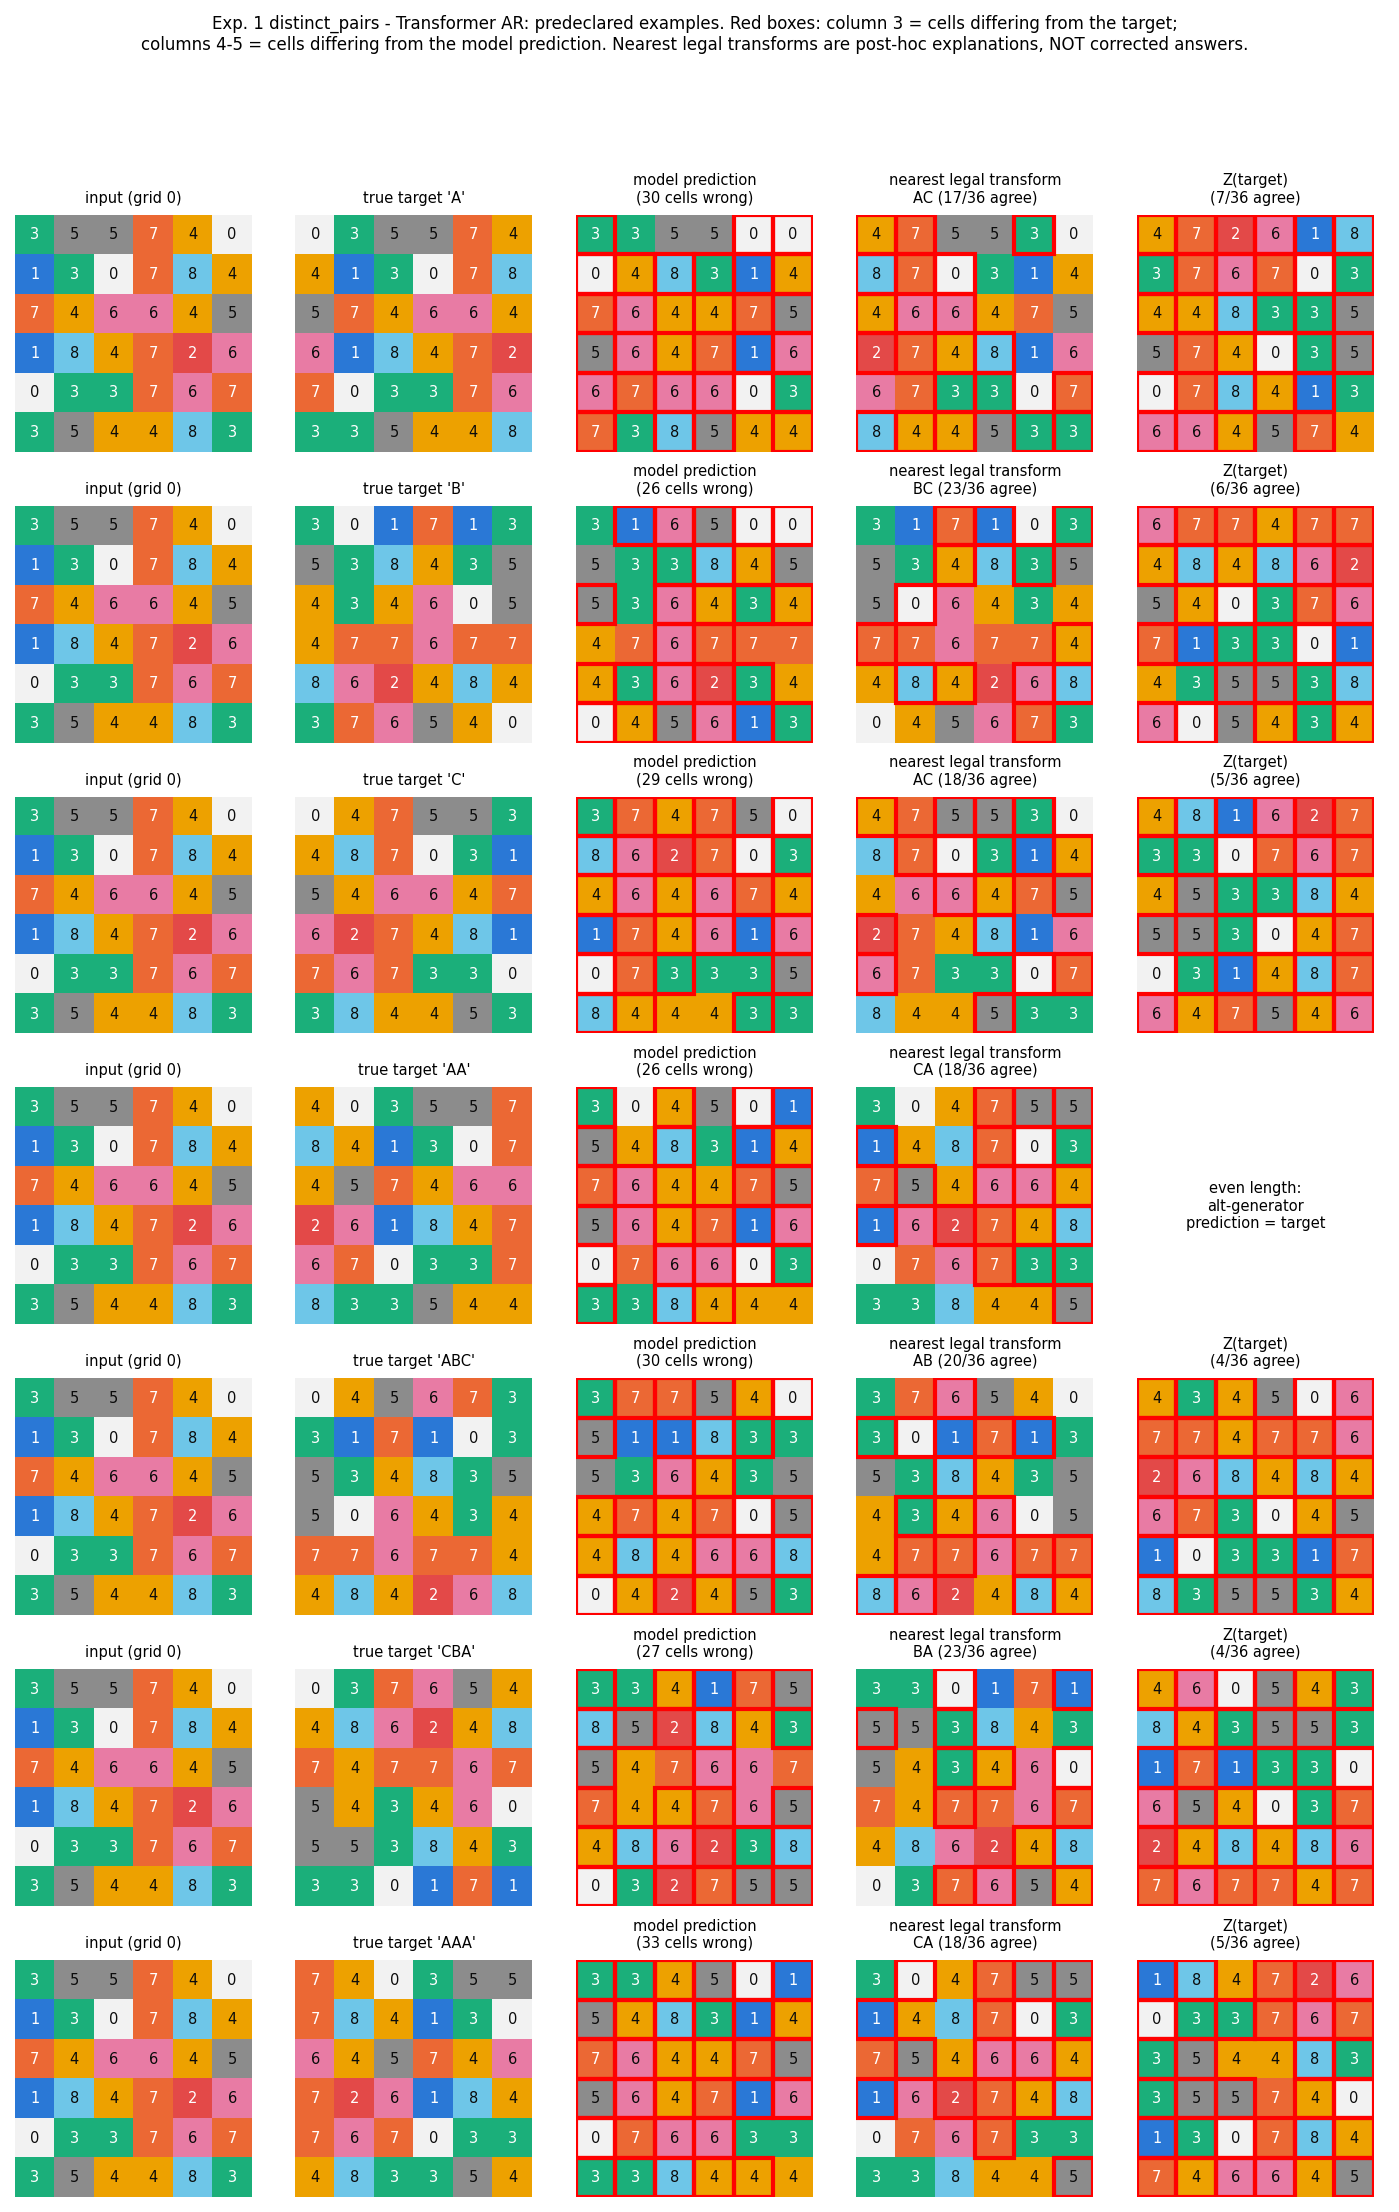

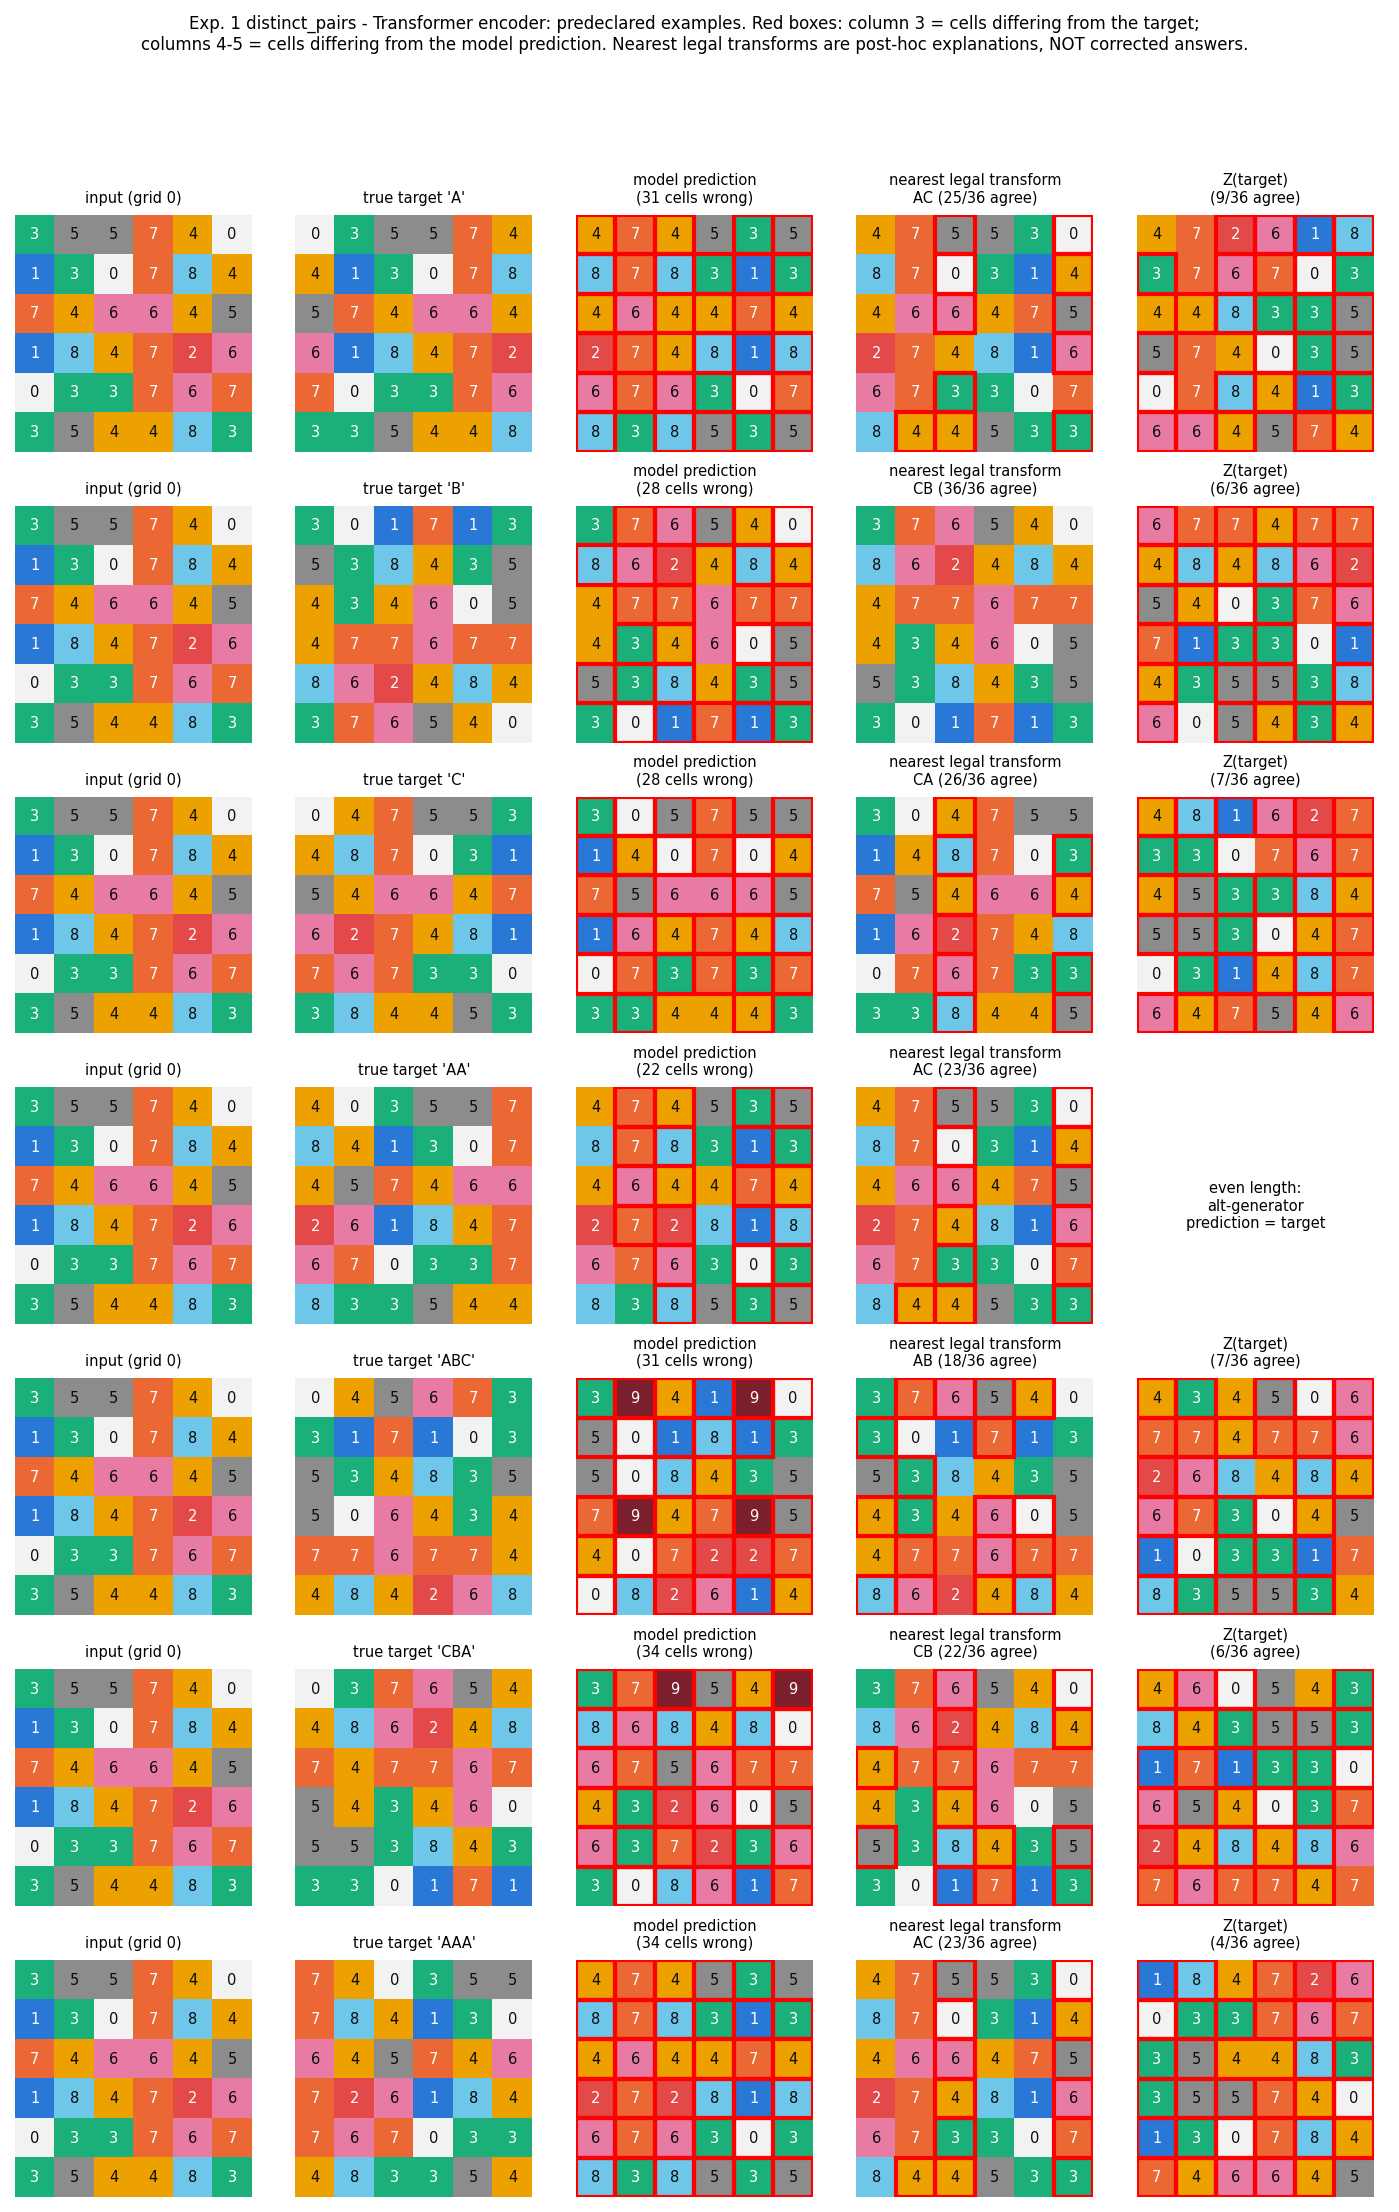

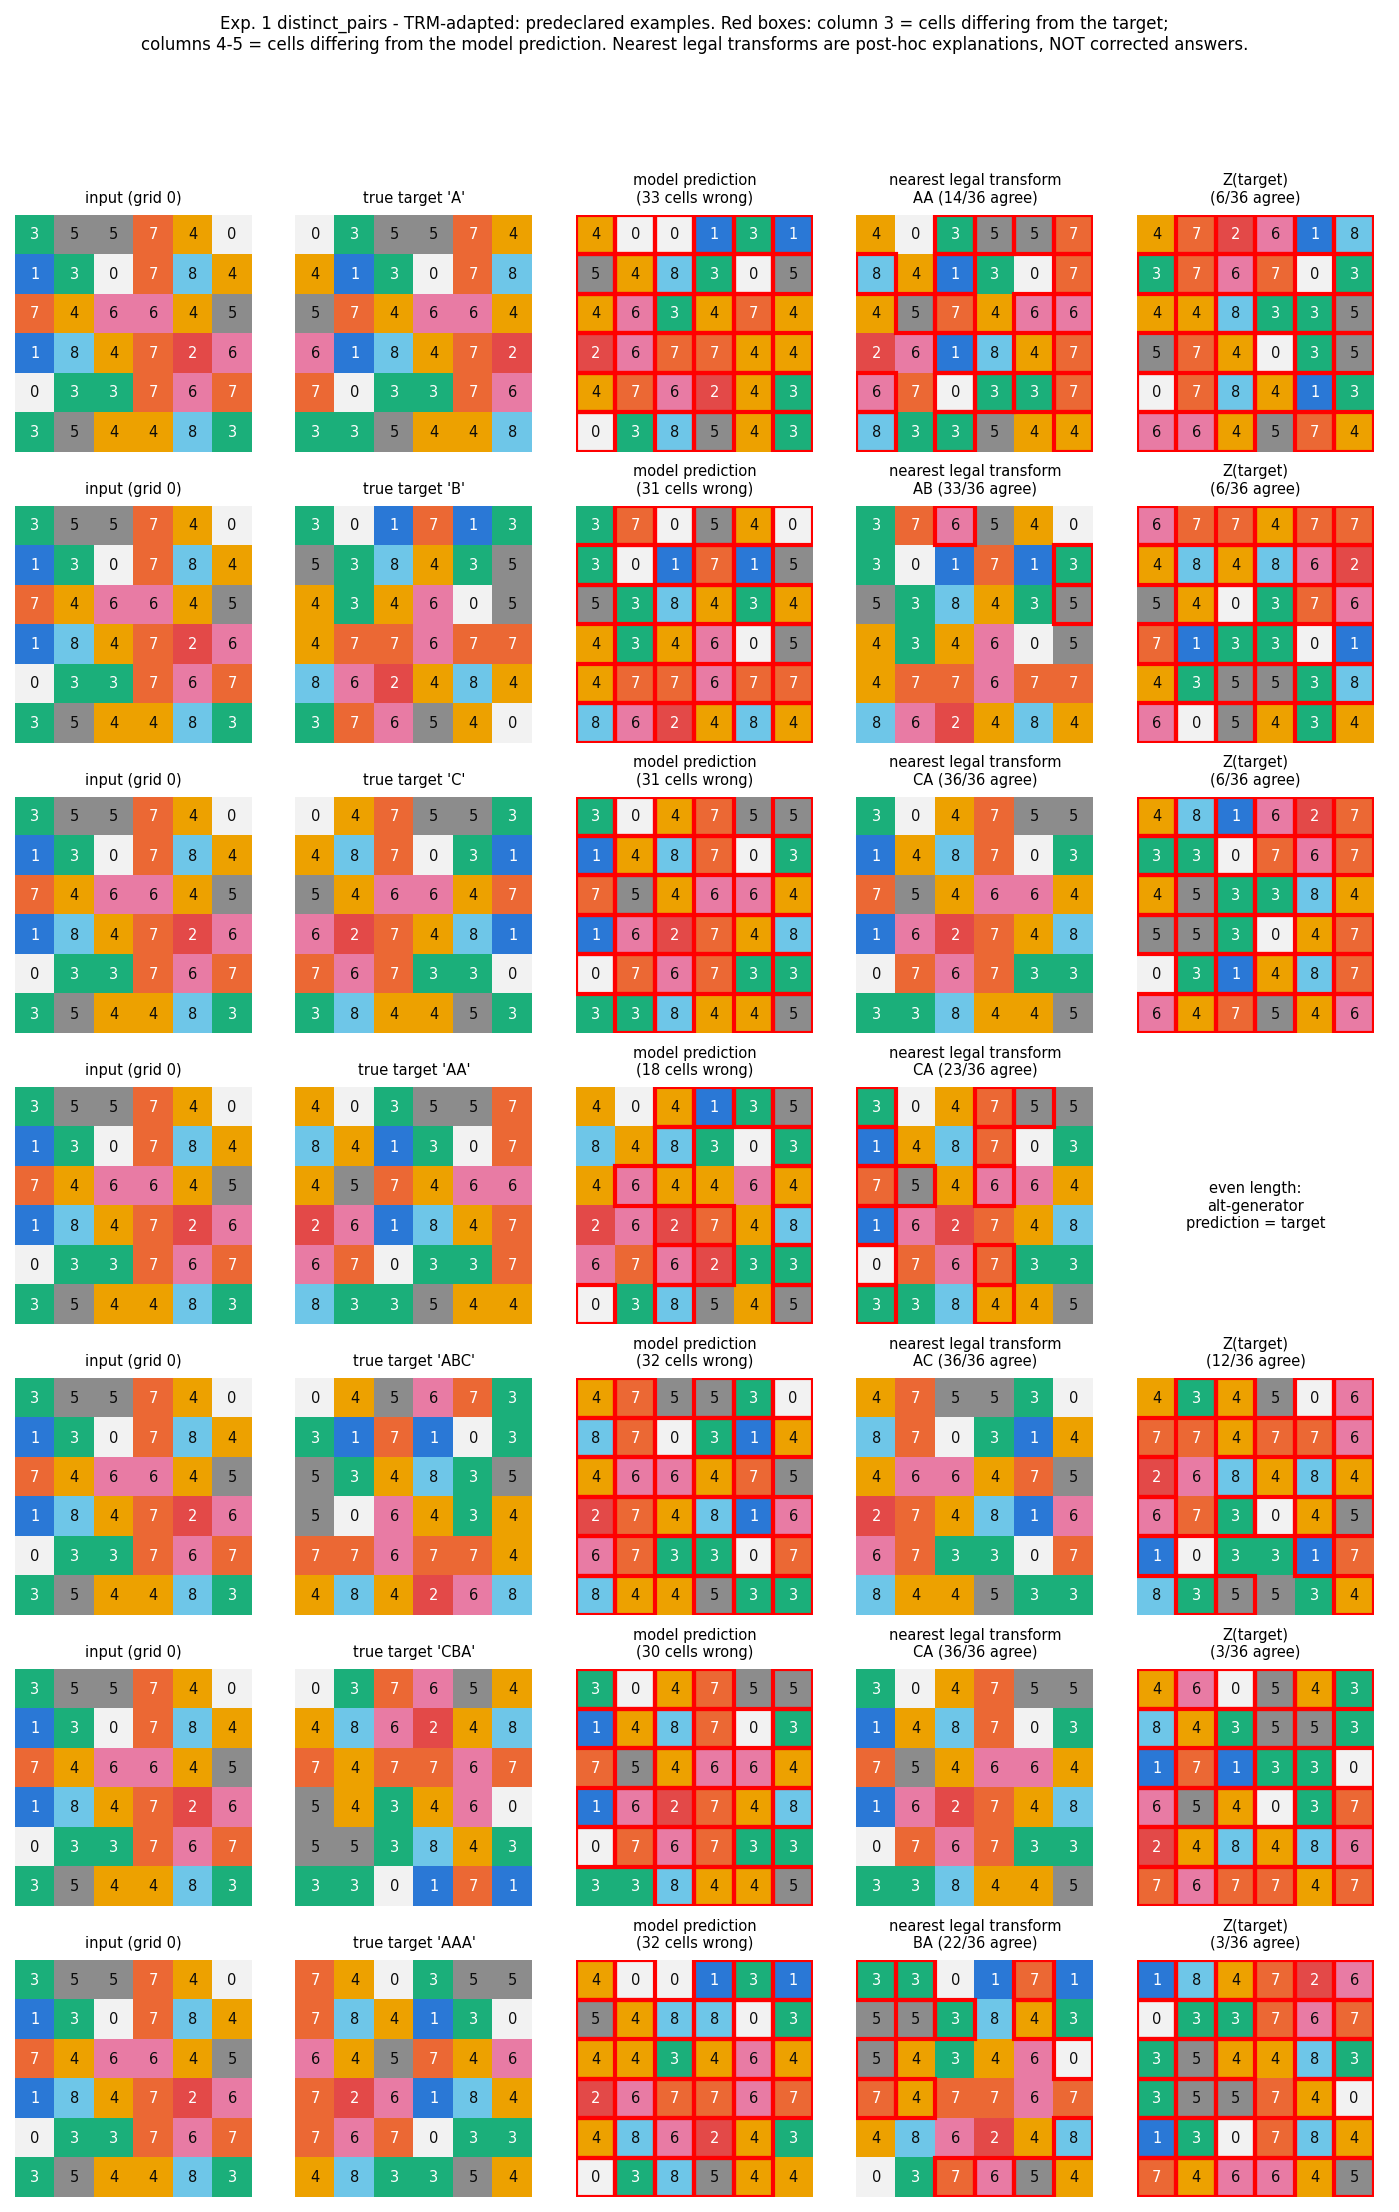

In [14]:
# --- 11. Fixed-ID qualitative examples (predeclared grid IDs, strings and models) ---
show("12_examples")


In [15]:
# --- 12. Evidence-based report + compact export (cache excluded) ---
import zipfile
display(Markdown(pathlib.Path(R["report_path"]).read_text()))
out = pathlib.Path(cfg.output_dir)
arch = out.parent / (out.name + "_export.zip")
with zipfile.ZipFile(arch, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(out.rglob("*")):
        rel = f.relative_to(out)
        if f.is_file() and rel.parts[0] not in ("cache", "selfcheck", "regenerated_predictions"):
            z.write(f, pathlib.Path(out.name) / rel)
print("All derived outputs:", out)
print("Compact export:", arch, f"({arch.stat().st_size / 2**20:.1f} MiB)")


# Generalization-failure diagnostics (post-hoc, frozen predictions)

This report is generated automatically from the saved prediction artifacts listed below. It describes model BEHAVIOUR on test inputs. Compatibility with an explanation does not establish internal representations or causality, and only one training seed exists, so nothing here is a cross-seed robustness claim.

## 1. Data coverage and provenance

| experiment | model | status |
|---|---|---|
| distinct_pairs | transformer_ar | predictions available (original) |
| distinct_pairs | looped_transformer_ar | predictions available (original) |
| distinct_pairs | transformer_encoder | predictions available (original) |
| distinct_pairs | looped_transformer_encoder | predictions available (original) |
| distinct_pairs | vit | predictions available (original) |
| distinct_pairs | looped_vit | predictions available (original) |
| distinct_pairs | trm | predictions available (original) |
| distinct_pairs | rescnn_film | predictions available (original) |
| distinct_pairs | unet_film | predictions available (original) |
| all_pairs | transformer_ar | predictions available (original) |
| all_pairs | looped_transformer_ar | predictions available (original) |
| all_pairs | transformer_encoder | predictions available (original) |
| all_pairs | looped_transformer_encoder | predictions available (original) |
| all_pairs | vit | predictions available (original) |
| all_pairs | looped_vit | predictions available (original) |
| all_pairs | trm | predictions available (original) |
| all_pairs | rescnn_film | predictions available (original) |
| all_pairs | unet_film | predictions available (original) |

### Audit

| experiment | model | source | n_records | n_strings | selected_step | code_commit_at_eval | decoding | duplicate_keys | invalid_records | target_oracle_mismatches | input_manifest_mismatches | attribution_blocked |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| distinct_pairs | transformer_ar | original | 39000 | 39 | 4750 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| distinct_pairs | looped_transformer_ar | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| distinct_pairs | transformer_encoder | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| distinct_pairs | looped_transformer_encoder | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| distinct_pairs | vit | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| distinct_pairs | looped_vit | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| distinct_pairs | trm | original | 39000 | 39 | 4750 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax of final refinement (S=2 refinements)); not autoregressive | 0 | 0 | 0 | 0 | False |
| distinct_pairs | rescnn_film | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| distinct_pairs | unet_film | original | 39000 | 39 | 4500 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| all_pairs | transformer_ar | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| all_pairs | looped_transformer_ar | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| all_pairs | transformer_encoder | original | 39000 | 39 | 3500 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| all_pairs | looped_transformer_encoder | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| all_pairs | vit | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| all_pairs | looped_vit | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| all_pairs | trm | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax of final refinement (S=2 refinements)); not autoregressive | 0 | 0 | 0 | 0 | False |
| all_pairs | rescnn_film | original | 39000 | 39 | 5000 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| all_pairs | unet_film | original | 39000 | 39 | 4750 | 9e9fc06c27bd2701e8b3b001d7901bac234169bd | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |


- Stored targets re-derived with the independent oracle for **702,000** records; mismatches: **0**.
- Test manifests identical across experiments: **True**.
- A synthetic perfect-oracle predictor passed through the same loader/metric code scores 100% on all 39 strings (this checks the analysis path, not any checkpoint's forward pass).

## 2. Verified observations (recomputed from raw records)

Columns prefixed DIAG use only the diagnostic half of the base grids (rules fitted on the other half). N/A = empty category (e.g. unseen pairs in all_pairs).

| experiment | model | group | exact_correct | n_records | true_exact_acc | true_cell_acc | any_exact_legal_match | wrong_unique_legal | no_legal_match | DIAG stable_rule_exact_fidelity | DIAG bijective_perm_cell_fidelity | alt_generator(Z)_exact_agreement |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| distinct_pairs | Transformer AR | singles | 0 | 3000 | 0.000 | 0.103 | 0.000 | 0.000 | 1.000 | 0.000 | 0.721 | 0.000 |
| distinct_pairs | Transformer AR | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | Transformer AR | pairs_unseen | 0 | 3000 | 0.000 | 0.345 | 0.000 | 0.000 | 1.000 | 0.000 | 0.723 | 0.000 |
| distinct_pairs | Transformer AR | triples_all_distinct | 0 | 6000 | 0.000 | 0.101 | 0.003 | 0.003 | 0.997 | 0.003 | 0.840 | 0.000 |
| distinct_pairs | Transformer AR | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.667 | 0.667 | 0.333 | 0.667 | 0.925 | 0.000 |
| distinct_pairs | Transformer AR | triples_one_type | 0 | 3000 | 0.000 | 0.099 | 0.000 | 0.000 | 1.000 | 0.000 | 0.728 | 0.000 |
| distinct_pairs | Looped Transformer AR (tied) | singles | 0 | 3000 | 0.000 | 0.100 | 0.125 | 0.125 | 0.875 | 0.128 | 0.870 | 0.000 |
| distinct_pairs | Looped Transformer AR (tied) | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | Looped Transformer AR (tied) | pairs_unseen | 0 | 3000 | 0.000 | 0.352 | 0.000 | 0.000 | 1.000 | 0.000 | 0.727 | 0.000 |
| distinct_pairs | Looped Transformer AR (tied) | triples_all_distinct | 0 | 6000 | 0.000 | 0.098 | 0.000 | 0.000 | 1.000 | 0.000 | 0.714 | 0.000 |
| distinct_pairs | Looped Transformer AR (tied) | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.763 | 0.763 | 0.237 | 0.762 | 0.972 | 0.000 |
| distinct_pairs | Looped Transformer AR (tied) | triples_one_type | 0 | 3000 | 0.000 | 0.097 | 0.001 | 0.001 | 0.999 | 0.001 | 0.780 | 0.000 |
| distinct_pairs | Transformer encoder | singles | 0 | 3000 | 0.000 | 0.099 | 0.319 | 0.319 | 0.681 | 0.317 | 0.809 | 0.000 |
| distinct_pairs | Transformer encoder | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | Transformer encoder | pairs_unseen | 0 | 3000 | 0.000 | 0.482 | 0.327 | 0.327 | 0.673 | 0.327 | 0.801 | 0.000 |
| distinct_pairs | Transformer encoder | triples_all_distinct | 0 | 6000 | 0.000 | 0.100 | 0.185 | 0.185 | 0.815 | 0.187 | 0.732 | 0.000 |
| distinct_pairs | Transformer encoder | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.680 | 0.680 | 0.320 | 0.680 | 0.912 | 0.000 |
| distinct_pairs | Transformer encoder | triples_one_type | 0 | 3000 | 0.000 | 0.101 | 0.331 | 0.331 | 0.669 | 0.330 | 0.810 | 0.000 |
| distinct_pairs | Looped Transformer encoder (tied) | singles | 0 | 3000 | 0.000 | 0.101 | 0.663 | 0.663 | 0.337 | 0.662 | 0.929 | 0.000 |
| distinct_pairs | Looped Transformer encoder (tied) | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | Looped Transformer encoder (tied) | pairs_unseen | 0 | 3000 | 0.000 | 0.460 | 0.333 | 0.333 | 0.667 | 0.333 | 0.900 | 0.000 |
| distinct_pairs | Looped Transformer encoder (tied) | triples_all_distinct | 0 | 6000 | 0.000 | 0.098 | 0.167 | 0.167 | 0.833 | 0.167 | 0.808 | 0.000 |
| distinct_pairs | Looped Transformer encoder (tied) | triples_two_types | 0 | 18000 | 0.000 | 0.101 | 0.796 | 0.796 | 0.204 | 0.797 | 0.954 | 0.000 |
| distinct_pairs | Looped Transformer encoder (tied) | triples_one_type | 0 | 3000 | 0.000 | 0.101 | 0.096 | 0.096 | 0.904 | 0.105 | 0.871 | 0.000 |
| distinct_pairs | ViT (2x2 patches) | singles | 0 | 3000 | 0.000 | 0.100 | 0.043 | 0.043 | 0.957 | 0.041 | 0.811 | 0.000 |
| distinct_pairs | ViT (2x2 patches) | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | ViT (2x2 patches) | pairs_unseen | 0 | 3000 | 0.000 | 0.257 | 0.053 | 0.053 | 0.947 | 0.053 | 0.892 | 0.000 |
| distinct_pairs | ViT (2x2 patches) | triples_all_distinct | 0 | 6000 | 0.000 | 0.099 | 0.000 | 0.000 | 1.000 | 0.000 | 0.523 | 0.000 |
| distinct_pairs | ViT (2x2 patches) | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.747 | 0.747 | 0.253 | 0.747 | 0.931 | 0.000 |
| distinct_pairs | ViT (2x2 patches) | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 0.011 | 0.011 | 0.989 | 0.011 | 0.797 | 0.000 |
| distinct_pairs | Looped ViT (tied baseline) | singles | 0 | 3000 | 0.000 | 0.100 | 0.001 | 0.001 | 0.999 | 0.001 | 0.801 | 0.000 |
| distinct_pairs | Looped ViT (tied baseline) | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | Looped ViT (tied baseline) | pairs_unseen | 0 | 3000 | 0.000 | 0.310 | 0.000 | 0.000 | 1.000 | 0.000 | 0.765 | 0.000 |
| distinct_pairs | Looped ViT (tied baseline) | triples_all_distinct | 0 | 6000 | 0.000 | 0.100 | 0.000 | 0.000 | 1.000 | 0.000 | 0.253 | 0.000 |
| distinct_pairs | Looped ViT (tied baseline) | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.771 | 0.771 | 0.229 | 0.771 | 0.912 | 0.000 |
| distinct_pairs | Looped ViT (tied baseline) | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 0.000 | 0.000 | 1.000 | 0.000 | 0.815 | 0.000 |
| distinct_pairs | TRM-adapted | singles | 0 | 3000 | 0.000 | 0.099 | 0.345 | 0.345 | 0.655 | 0.325 | 0.705 | 0.000 |
| distinct_pairs | TRM-adapted | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | TRM-adapted | pairs_unseen | 0 | 3000 | 0.000 | 0.441 | 0.337 | 0.337 | 0.663 | 0.333 | 0.764 | 0.000 |
| distinct_pairs | TRM-adapted | triples_all_distinct | 0 | 6000 | 0.000 | 0.100 | 0.669 | 0.669 | 0.331 | 0.673 | 0.973 | 0.000 |
| distinct_pairs | TRM-adapted | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.756 | 0.756 | 0.244 | 0.749 | 0.911 | 0.000 |
| distinct_pairs | TRM-adapted | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 0.063 | 0.063 | 0.937 | 0.063 | 0.767 | 0.000 |
| distinct_pairs | ResCNN-FiLM | singles | 0 | 3000 | 0.000 | 0.097 | 0.043 | 0.043 | 0.957 | 0.053 | 0.783 | 0.000 |
| distinct_pairs | ResCNN-FiLM | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | ResCNN-FiLM | pairs_unseen | 0 | 3000 | 0.000 | 0.390 | 0.481 | 0.481 | 0.519 | 0.483 | 0.945 | 0.000 |
| distinct_pairs | ResCNN-FiLM | triples_all_distinct | 0 | 6000 | 0.000 | 0.099 | 0.141 | 0.141 | 0.859 | 0.144 | 0.732 | 0.000 |
| distinct_pairs | ResCNN-FiLM | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.601 | 0.601 | 0.399 | 0.600 | 0.929 | 0.000 |
| distinct_pairs | ResCNN-FiLM | triples_one_type | 0 | 3000 | 0.000 | 0.098 | 0.000 | 0.000 | 1.000 | 0.000 | 0.621 | 0.000 |
| distinct_pairs | U-Net-FiLM | singles | 0 | 3000 | 0.000 | 0.095 | 0.281 | 0.281 | 0.719 | 0.287 | 0.785 | 0.000 |
| distinct_pairs | U-Net-FiLM | pairs_seen | 6000 | 6000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| distinct_pairs | U-Net-FiLM | pairs_unseen | 0 | 3000 | 0.000 | 0.393 | 0.218 | 0.218 | 0.782 | 0.221 | 0.903 | 0.000 |
| distinct_pairs | U-Net-FiLM | triples_all_distinct | 0 | 6000 | 0.000 | 0.097 | 0.454 | 0.454 | 0.546 | 0.455 | 0.879 | 0.000 |
| distinct_pairs | U-Net-FiLM | triples_two_types | 0 | 18000 | 0.000 | 0.098 | 0.618 | 0.618 | 0.382 | 0.618 | 0.909 | 0.000 |
| distinct_pairs | U-Net-FiLM | triples_one_type | 0 | 3000 | 0.000 | 0.096 | 0.000 | 0.000 | 1.000 | 0.001 | 0.633 | 0.000 |
| all_pairs | Transformer AR | singles | 0 | 3000 | 0.000 | 0.100 | 0.966 | 0.966 | 0.034 | 0.963 | 0.999 | 0.000 |
| all_pairs | Transformer AR | pairs_seen | 9000 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | Transformer AR | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | Transformer AR | triples_all_distinct | 0 | 6000 | 0.000 | 0.099 | 0.015 | 0.015 | 0.985 | 0.017 | 0.878 | 0.000 |
| all_pairs | Transformer AR | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.667 | 0.667 | 0.333 | 0.667 | 0.952 | 0.000 |
| all_pairs | Transformer AR | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 1.000 | 1.000 | 0.000 | 1.000 | 1.000 | 0.000 |
| all_pairs | Looped Transformer AR (tied) | singles | 0 | 3000 | 0.000 | 0.100 | 0.693 | 0.693 | 0.307 | 0.688 | 0.991 | 0.000 |
| all_pairs | Looped Transformer AR (tied) | pairs_seen | 9000 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | Looped Transformer AR (tied) | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | Looped Transformer AR (tied) | triples_all_distinct | 0 | 6000 | 0.000 | 0.102 | 0.000 | 0.000 | 1.000 | 0.000 | 0.840 | 0.000 |
| all_pairs | Looped Transformer AR (tied) | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.667 | 0.667 | 0.333 | 0.667 | 0.954 | 0.000 |
| all_pairs | Looped Transformer AR (tied) | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 1.000 | 1.000 | 0.000 | 1.000 | 1.000 | 0.000 |
| all_pairs | Transformer encoder | singles | 0 | 3000 | 0.000 | 0.100 | 0.990 | 0.990 | 0.010 | 0.989 | 1.000 | 0.000 |
| all_pairs | Transformer encoder | pairs_seen | 9000 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | Transformer encoder | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | Transformer encoder | triples_all_distinct | 0 | 6000 | 0.000 | 0.111 | 0.186 | 0.186 | 0.814 | 0.187 | 0.813 | 0.000 |
| all_pairs | Transformer encoder | triples_two_types | 0 | 18000 | 0.000 | 0.120 | 0.667 | 0.667 | 0.333 | 0.667 | 0.867 | 0.000 |
| all_pairs | Transformer encoder | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 1.000 | 1.000 | 0.000 | 1.000 | 1.000 | 0.000 |
| all_pairs | Looped Transformer encoder (tied) | singles | 0 | 3000 | 0.000 | 0.100 | 0.925 | 0.925 | 0.075 | 0.924 | 0.998 | 0.000 |
| all_pairs | Looped Transformer encoder (tied) | pairs_seen | 9000 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | Looped Transformer encoder (tied) | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | Looped Transformer encoder (tied) | triples_all_distinct | 0 | 6000 | 0.000 | 0.101 | 0.151 | 0.151 | 0.849 | 0.143 | 0.879 | 0.000 |
| all_pairs | Looped Transformer encoder (tied) | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.778 | 0.778 | 0.222 | 0.778 | 0.955 | 0.000 |
| all_pairs | Looped Transformer encoder (tied) | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 1.000 | 1.000 | 0.000 | 1.000 | 1.000 | 0.000 |
| all_pairs | ViT (2x2 patches) | singles | 0 | 3000 | 0.000 | 0.100 | 0.651 | 0.651 | 0.349 | 0.639 | 0.984 | 0.000 |
| all_pairs | ViT (2x2 patches) | pairs_seen | 9000 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | ViT (2x2 patches) | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | ViT (2x2 patches) | triples_all_distinct | 0 | 6000 | 0.000 | 0.101 | 0.165 | 0.165 | 0.835 | 0.167 | 0.830 | 0.000 |
| all_pairs | ViT (2x2 patches) | triples_two_types | 0 | 18000 | 0.000 | 0.099 | 0.667 | 0.667 | 0.333 | 0.667 | 0.893 | 0.000 |
| all_pairs | ViT (2x2 patches) | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 1.000 | 1.000 | 0.000 | 1.000 | 1.000 | 0.000 |
| all_pairs | Looped ViT (tied baseline) | singles | 0 | 3000 | 0.000 | 0.099 | 0.667 | 0.667 | 0.333 | 0.667 | 0.982 | 0.000 |
| all_pairs | Looped ViT (tied baseline) | pairs_seen | 9000 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | Looped ViT (tied baseline) | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | Looped ViT (tied baseline) | triples_all_distinct | 0 | 6000 | 0.000 | 0.100 | 0.472 | 0.472 | 0.528 | 0.474 | 0.958 | 0.000 |
| all_pairs | Looped ViT (tied baseline) | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.625 | 0.625 | 0.375 | 0.624 | 0.930 | 0.000 |
| all_pairs | Looped ViT (tied baseline) | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 1.000 | 1.000 | 0.000 | 1.000 | 1.000 | 0.000 |
| all_pairs | TRM-adapted | singles | 0 | 3000 | 0.000 | 0.100 | 0.929 | 0.929 | 0.071 | 0.925 | 0.993 | 0.000 |
| all_pairs | TRM-adapted | pairs_seen | 9000 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | TRM-adapted | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | TRM-adapted | triples_all_distinct | 0 | 6000 | 0.000 | 0.103 | 0.301 | 0.301 | 0.699 | 0.302 | 0.872 | 0.000 |
| all_pairs | TRM-adapted | triples_two_types | 0 | 18000 | 0.000 | 0.103 | 0.820 | 0.820 | 0.180 | 0.819 | 0.971 | 0.000 |
| all_pairs | TRM-adapted | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 1.000 | 1.000 | 0.000 | 1.000 | 1.000 | 0.000 |
| all_pairs | ResCNN-FiLM | singles | 0 | 3000 | 0.000 | 0.094 | 0.001 | 0.001 | 0.999 | 0.001 | 0.761 | 0.000 |
| all_pairs | ResCNN-FiLM | pairs_seen | 9000 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | ResCNN-FiLM | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | ResCNN-FiLM | triples_all_distinct | 0 | 6000 | 0.000 | 0.099 | 0.010 | 0.010 | 0.990 | 0.008 | 0.764 | 0.000 |
| all_pairs | ResCNN-FiLM | triples_two_types | 0 | 18000 | 0.000 | 0.100 | 0.447 | 0.447 | 0.553 | 0.447 | 0.885 | 0.000 |
| all_pairs | ResCNN-FiLM | triples_one_type | 0 | 3000 | 0.000 | 0.098 | 0.347 | 0.347 | 0.653 | 0.343 | 0.755 | 0.000 |
| all_pairs | U-Net-FiLM | singles | 0 | 3000 | 0.000 | 0.095 | 0.034 | 0.034 | 0.966 | 0.033 | 0.767 | 0.000 |
| all_pairs | U-Net-FiLM | pairs_seen | 8998 | 9000 | 1.000 | 1.000 | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | 1.000 |
| all_pairs | U-Net-FiLM | pairs_unseen | 0 | 0 | N/A | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| all_pairs | U-Net-FiLM | triples_all_distinct | 0 | 6000 | 0.000 | 0.095 | 0.023 | 0.023 | 0.977 | 0.021 | 0.715 | 0.000 |
| all_pairs | U-Net-FiLM | triples_two_types | 0 | 18000 | 0.000 | 0.099 | 0.420 | 0.420 | 0.580 | 0.418 | 0.910 | 0.000 |
| all_pairs | U-Net-FiLM | triples_one_type | 0 | 3000 | 0.000 | 0.100 | 1.000 | 1.000 | 0.000 | 1.000 | 1.000 | 0.000 |


### distinct_pairs

- Unseen strings: 0 exact-correct of 297,000 records (0.000000).
- Wrong predictions on unseen strings that EXACTLY equal some legal transform of the input: 0.4616 of 297,000.
- (model, unseen string) cells where ONE fixed legal transform fitted on FIT grids reproduces >= 95% of DIAG predictions exactly: 121 of 297.
  - of these, the fitted rule is a training-pair transformation in 121 and equals the alternate-generator (Z-twisted) prediction in 0; most frequent fitted rules (canonical words): AC x22, CB x22, CA x20, AB x19, BC x19, BA x19
- Odd-length strings: exact agreement with Z(target) = 0.0000 (record-weighted over models/strings).
- Composition of fitted single-operation maps (DIAG): mean exact agreement with model predictions 0.0273, with true targets 0.0216; 302 of 324 rows flagged WEAK (unstable single maps).

### all_pairs

- Unseen strings: 0 exact-correct of 270,000 records (0.000000).
- Wrong predictions on unseen strings that EXACTLY equal some legal transform of the input: 0.5709 of 270,000.
- (model, unseen string) cells where ONE fixed legal transform fitted on FIT grids reproduces >= 95% of DIAG predictions exactly: 136 of 270.
  - of these, the fitted rule is a training-pair transformation in 136 and equals the alternate-generator (Z-twisted) prediction in 0; most frequent fitted rules (canonical words): I x17, CB x16, AB x16, BC x16, BA x16, AA x15, BB x14, AC x13
- Odd-length strings: exact agreement with Z(target) = 0.0000 (record-weighted over models/strings).
- Composition of fitted single-operation maps (DIAG): mean exact agreement with model predictions 0.0841, with true targets 0.0340; 70 of 324 rows flagged WEAK (unstable single maps).

### Cross-experiment (same model, string and base grid)

| model | identical_prediction_rate | delta_exact (all_pairs - distinct_pairs) | delta_any_legal (all_pairs - distinct_pairs) |
|---|---|---|---|
| looped_transformer_ar | 0.461 | 0.077 | 0.153 |
| looped_transformer_encoder | 0.462 | 0.077 | 0.130 |
| looped_vit | 0.395 | 0.077 | 0.210 |
| rescnn_film | 0.210 | 0.077 | -0.028 |
| transformer_ar | 0.462 | 0.077 | 0.230 |
| transformer_encoder | 0.487 | 0.077 | 0.149 |
| trm | 0.528 | 0.077 | 0.141 |
| unet_film | 0.209 | 0.077 | -0.040 |
| vit | 0.462 | 0.077 | 0.184 |


## 3. Hypotheses compatible with the observations

- all_pairs: 0.584 of unseen-string examples are exactly compatible with a non-truth 'double_single' hypothesis (hypothesis types overlap).
- all_pairs: 0.571 of unseen-string examples are exactly compatible with a non-truth 'training_pair' hypothesis (hypothesis types overlap).
- all_pairs: 0.562 of unseen-string examples are exactly compatible with a non-truth 'proper_subsequence' hypothesis (hypothesis types overlap).
- all_pairs: 0.562 of unseen-string examples are exactly compatible with a non-truth 'drop_one' hypothesis (hypothesis types overlap).
- distinct_pairs: 0.524 of unseen-string examples are exactly compatible with a non-truth 'collapse_repeats' hypothesis (hypothesis types overlap).
- all_pairs: 0.490 of unseen-string examples are exactly compatible with a non-truth 'collapse_repeats' hypothesis (hypothesis types overlap).
- distinct_pairs: 0.463 of unseen-string examples are exactly compatible with a non-truth 'proper_subsequence' hypothesis (hypothesis types overlap).
- distinct_pairs: 0.463 of unseen-string examples are exactly compatible with a non-truth 'drop_one' hypothesis (hypothesis types overlap).
- distinct_pairs: 0.462 of unseen-string examples are exactly compatible with a non-truth 'training_pair' hypothesis (hypothesis types overlap).
- all_pairs: 0.303 of unseen-string examples are exactly compatible with a non-truth 'proper_prefix' hypothesis (hypothesis types overlap).
- all_pairs: 0.295 of unseen-string examples are exactly compatible with a non-truth 'proper_suffix' hypothesis (hypothesis types overlap).

## 4. Unresolved cases

(model, unseen string) cells with no stable legal rule (DIAG exact < 0.5) AND no stable source map (DIAG cell fidelity < 0.9): **160**. This only rules out these specific explanation families; it is not evidence of randomness.

| experiment | model | string |
|---|---|---|
| all_pairs | looped_transformer_ar | ABC |
| all_pairs | looped_transformer_encoder | ABC BCB CBC |
| all_pairs | looped_vit | ABA BCB CBC |
| all_pairs | rescnn_film | A B C ABC ACB BAC BCA CAB AAB AAC BAA BAB BCB BCC AAA |
| all_pairs | transformer_ar | ABC CBA ABA BAB BCB CBC |
| all_pairs | transformer_encoder | ABC CBA ABA CBC |
| all_pairs | trm | ABC CBA CBC |
| all_pairs | unet_film | A C ABC ACB BAC BCA CAB ABB BAB BBA BCB BCC CCB |
| all_pairs | vit | CBA ABA ACA BAB BCB CBC |
| distinct_pairs | looped_transformer_ar | C AA BB CC ABC ACB BAC BCA CAB CBA CCC |
| distinct_pairs | looped_transformer_encoder | C CC BAC BCA CAC CBC CCC |
| distinct_pairs | looped_vit | A B C AA BB CC ABC ACB BAC BCA CAB CBA ABA BAB CAC CBC AAA CCC |
| distinct_pairs | rescnn_film | B C CC ACB BAC BCA CAB CBA ACA BAB CAC CBC AAA BBB CCC |
| distinct_pairs | transformer_ar | A B C BB CC ABC BBB CCC |
| distinct_pairs | transformer_encoder | ABC BAC BCA CAB CBA ABA BAB BCB CCC |
| distinct_pairs | trm | A B AA CC ACA BCB CBC AAA BBB |
| distinct_pairs | unet_film | B C CC BAC CAB ABA ACA BAB BCB CAC CBC AAA BBB CCC |
| distinct_pairs | vit | A B C AA CC ABC ACB BAC BCA CAB CBA ABA CAC CBC AAA |


## 5. Limits

- Exact legal-transform matching uses all 288 transformations; matching one does not identify which symbolic string the model 'executed', and ambiguous matches are kept as ambiguous.
- DIAG-split fidelities describe frozen predictions with rules fitted to those predictions; they are not a new held-out benchmark of the neural models.
- Behavioural compatibility is not a causal or mechanistic claim; one seed only.


All derived outputs: /content/drive/MyDrive/decompositionality_results/diagnostics_generalization_failures
Compact export: /content/drive/MyDrive/decompositionality_results/diagnostics_generalization_failures_export.zip (17.7 MiB)


## Outputs
`<DIAGNOSTICS_OUTPUT_DIR>/`: `tables/` (CSV), `figures/` (PNG+PDF+CSV), `per_example/` (compact per-record diagnostics), `maps/` (all fitted source maps), `REPORT.md`, `provenance.json` (file hashes, selected steps, analysis code commit), `cache/`. Original predictions and checkpoints are only read.